# 1. Title and Overview

## Comparative Evaluation of ResNet-50 and Vision Transformer (ViT-Base) Architectures for Automated Detection of Pulmonary Tuberculosis Bacilli in Ziehl-Neelsen Stained Sputum Smear Images

**Module:** RPDA8412 Research Project, The Independent Institute of Education

**Researcher:** Cameron Chetty (ST10251759)

**Supervisor:** Dr Janine Upton

**Dataset:** Tuberculosis Image Dataset (Saife, 2020), Kaggle, secondary and anonymised (ethics waiver approved 21/06/2026); source images and annotations originate from the Makerere Automated Lab Diagnostics Database, Mulago National Referral Hospital, Kampala, Uganda

This notebook implements the approved methodology of the research proposal (RPDA8411), with the documented decisions and deviations recorded in the decisions log (Section 3.4). It produces every number, table and figure reported in the Findings section of the Research Report, and nothing that is reported was produced anywhere else. Every cell's output is captured automatically in `outputs/outputs.txt` (full history) and `outputs/outputs_latest.txt` (latest run of each cell), so the run record and the report can always be checked against each other.

**Overview of what this notebook does, in the order it does it:**

1. Verifies the raw dataset file by file before trusting anything about its class balance (Section 4).
2. Profiles the verified dataset in depth, including properties specific to this imaging problem: bacillus size and location, image sharpness, and near-duplicate content (Section 5).
3. Builds an identical preprocessing and augmentation pipeline for both architectures (Section 6).
4. Creates one stratified 80:20 split with five folds, shared by both models (Section 7).
5. Trains and evaluates ResNet-50 and ViT-Base as two independent, symmetric pipelines built on the same shared training engine (Sections 8 and 9).
6. Compares the two models statistically and qualitatively on the same held-out test images (Section 10).
7. States what the results do and do not support (Section 11), and lists every code source used (Section 12).

**Run rule:** run the cells in order, top to bottom. Section 10.4 unlocks the held-out test set once only.

### Golden thread: where each research question is answered

| Research element | Metric or output | Statistical test | Section |
|---|---|---|---|
| SQ1 / H01, H11 | Accuracy (all test images) | McNemar's test | 10.2, 10.3 |
| SQ2 / H02, H12 | Sensitivity (positive-label test images only) | McNemar's test on the positive subset | 10.2, 10.3 |
| SQ3 / H03, H13 | Specificity (negative-label test images only) | McNemar's test on the negative subset | 10.2, 10.3 |
| SQ4 / H04, H14 | AUC-ROC | DeLong's method | 10.2, 10.3 |
| Secondary indicators | Precision, F1-score | Descriptive only, with bootstrap intervals | 10.3 |
| SQ5 (exploratory) | Grad-CAM (ResNet-50, Section 8.3) and last-layer attention maps (ViT-Base, Section 9.3) | Qualitative only, no clinician validation | 10.4 |
| Model stability | Five-fold cross-validation mean and SD | Descriptive only | 8.2, 9.2 |

All four primary tests use a Bonferroni-adjusted significance level of 0.05 / 4 = 0.0125 (proposal Section 3.6).

### How to run

1. Complete the environment setup described in `README.md` (local Python 3.10.11 environment, or Google Colab).
2. Run Section 3 to set up paths, logging, configuration and seeds.
3. Run Section 4 (dataset gate and manual review). **If the gate fails, stop and consult the supervisor. Do not continue.** Complete the manual review in Cells 4.4 and 4.5 before Section 5.
4. Run Sections 5 to 7 in order.
5. Section 8 opens with the shared training utilities and a compute benchmark (Cell 8.0), which reads its timing before you commit to the full grid search. Sections 8 and 9 are then long-running and resumable: if a session disconnects, re-run Section 3, Cells 4.1 to 4.3 and 4.5, Cell 4.6, Section 6, Section 7, and Cell 8.0, then re-run the Training subsections (8.2, 9.2). Completed runs are skipped automatically.
6. Run Sections 10 to 12 in order.

# 2. Table of Contents

1. Title and Overview
2. Table of Contents
3. Imports and Environment Setup
   3.1 Package installation | 3.2 Core and deep-learning imports | 3.3 Paths and the automatic outputs log | 3.4 Experimental configuration | 3.5 Versions, hardware and seeds
4. Dataset Justification and Overview
   4.1 Why this dataset | 4.2 Locate the dataset | 4.3 Integrity checks and the dataset gate | 4.4 Raw annotation inspection | 4.5 Manual review of every negative image | 4.6 Final labelled dataset composition
5. Exploratory Data Analysis
   5.1 Class distribution and bacilli counts | 5.2 Bounding-box geometry | 5.3 Spatial distribution of bacilli | 5.4 Resolution and colour statistics | 5.5 Image sharpness and edge density | 5.6 Feature correlations with class | 5.7 Near-duplicate content check | 5.8 Visual spot check of negatives | 5.9 Annotated sample images | 5.10 EDA summary
6. Data Preprocessing and Augmentation
   6.1 Resize and cache | 6.2 Normalisation and transform pipelines | 6.3 Dataset class and loaders | 6.4 Augmentation preview
7. Train-Validation-Test Split
   7.1 Stratified split and five-fold assignment
8. Model 1: ResNet-50
   8.0 Shared training utilities and compute benchmark | 8.1 Architecture | 8.2 Training | 8.3 Evaluation
9. Model 2: ViT-Base
   9.1 Architecture | 9.2 Training | 9.3 Evaluation
10. Comparative Analysis
    10.1 Combined test performance | 10.2 Statistical hypothesis tests | 10.3 Uncertainty and effect sizes | 10.4 Exploratory interpretability | 10.5 Report-ready tables and environment record
11. Conclusion and Recommendations
12. References

# 3. Imports and Environment Setup

This section fixes everything that must be identical for both architectures: paths, the logging system, the full experimental configuration and the random seeds. Holding these constant is what allows any performance difference to be attributed to architecture rather than to experimental inconsistency (proposal Section 3.8).

In [1]:
# CELL 3.1  Package installation
# Colab: PyTorch and torchvision are pre-installed; this installs the two remaining packages.
# Local: install everything from requirements.txt in your terminal instead (see README).
import sys
if "google.colab" in sys.modules:
    %pip install -q timm kagglehub
else:
    print("Local environment detected: packages come from requirements.txt (see README).")

In [2]:
# CELL 3.2  Core imports (standard library and scientific stack)
import hashlib
import itertools
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import scipy
import sklearn
from PIL import Image, ImageDraw
from scipy import ndimage, stats
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split

In [3]:
# CELL 3.2  Deep learning imports
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

In [4]:
# CELL 3.3  Paths and the automatic outputs log
# From this cell onward, everything a cell prints (including warnings and errors) is copied into
# outputs/outputs.txt automatically, under a header naming the cell. Two files are kept:
#   outputs.txt         full, append-only history of every run (never edited: the audit trail)
#   outputs_latest.txt  regenerated after every cell: the most recent run of each cell, in notebook order
# CODE ATTRIBUTION: pre_run_cell and post_run_cell hooks follow the IPython documentation on events,
#   https://ipython.readthedocs.io/en/stable/config/callbacks.html
import re
import traceback

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Persist everything on Google Drive so a disconnected session loses nothing.
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/RPDA8412_TB_ResNet50_vs_ViTBase")
else:
    PROJECT_ROOT = Path.cwd()  # the folder that contains this notebook

DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUT = PROJECT_ROOT / "outputs"
DIRS = {name: OUT / name for name in
        ["manifests", "splits", "figures", "logs", "results", "tables", "models"]}
for folder in [DATA_DIR, OUT, *DIRS.values()]:
    folder.mkdir(parents=True, exist_ok=True)

OUTPUT_LOG = OUT / "outputs.txt"
LATEST_LOG = OUT / "outputs_latest.txt"
_CURRENT_CELL = {"id": "3.3", "started": time.time()}
HEADER_PATTERN = re.compile(r"^\[CELL (?P<id>[^\]]+)\] (?P<title>.*?)\s+\|\s+(?P<stamp>\S+)\s*$")
FOOTER_PATTERN = re.compile(r"^\[(?P<id>[^\]]+)\] --- finished in (?P<secs>[\d.]+) s \| status (?P<status>\w+)")


def _append(text: str) -> None:
    with OUTPUT_LOG.open("a", encoding="utf-8") as handle:
        handle.write(text)


class _TeeStream:
    """Sends everything written to the screen to outputs.txt as well, one line at a time.
    A carriage return (used by progress bars to redraw a line) discards the unfinished line,
    so only the final state of a progress bar is recorded."""

    def __init__(self, original):
        self.original = original
        self.pending = ""

    def write(self, text):
        self.original.write(text)
        for segment in re.split(r"(\r|\n)", text.replace("\r\n", "\n")):
            if segment == "\n":
                _append(self.pending + "\n")
                self.pending = ""
            elif segment == "\r":
                self.pending = ""
            else:
                self.pending += segment
        return len(text)

    def flush_pending(self):
        if self.pending:
            _append(self.pending + "\n")
            self.pending = ""

    def flush(self):
        self.original.flush()

    def __getattr__(self, name):
        return getattr(self.original, name)


# Install the tee once, even if this cell is run again
for stream_name in ("stdout", "stderr"):
    current = getattr(sys, stream_name)
    if isinstance(current, _TeeStream) or type(current).__name__ == "_TeeStream":
        current = current.original
    setattr(sys, stream_name, _TeeStream(current))


def _write_header(cell_id: str, title: str) -> None:
    _CURRENT_CELL.update(id=cell_id, started=time.time())
    stamp = datetime.now().isoformat(timespec="seconds")
    _append(f"\n{'=' * 78}\n[CELL {cell_id}] {title}  |  {stamp}\n{'=' * 78}\n")


def start_cell(cell_id: str, title: str) -> None:
    """Kept for compatibility: the header is now written automatically before each cell runs."""
    _CURRENT_CELL["id"] = cell_id


def log(message: str) -> None:
    """Print a message tagged with the current cell (the tee copies it into outputs.txt)."""
    print(f"[{_CURRENT_CELL['id']}] {message}")


def save_fig(fig, name: str) -> Path:
    """Save a figure at 300 dpi for the report and log where it went."""
    path = DIRS["figures"] / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    log(f"Figure saved: {path.relative_to(PROJECT_ROOT)}")
    return path


def sha256_of_file(path: Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _cell_sort_key(cell_id: str):
    parts = cell_id.split(".")
    if all(p.isdigit() for p in parts):
        return (0, tuple(int(p) for p in parts))
    return (1, (cell_id,))


def rebuild_latest_log() -> None:
    """Rewrite outputs_latest.txt: the most recent run of each cell, sorted in notebook order."""
    if not OUTPUT_LOG.exists():
        return
    blocks, current = {}, None
    for line in OUTPUT_LOG.read_text(encoding="utf-8").splitlines():
        match = HEADER_PATTERN.match(line)
        if match:
            current = match.group("id")
            blocks[current] = {"title": match.group("title"), "stamp": match.group("stamp"),
                               "status": "no status line", "lines": [line]}
            continue
        if current is None or set(line) == {"="}:
            continue
        blocks[current]["lines"].append(line)
        footer = FOOTER_PATTERN.match(line)
        if footer and footer.group("id") == current:
            blocks[current]["status"] = footer.group("status")
    order = sorted(blocks, key=_cell_sort_key)
    summary = [f"LATEST RUN OF EACH CELL  |  rebuilt {datetime.now().isoformat(timespec='seconds')}",
               f"Full history: {OUTPUT_LOG.name} (append-only, never edited)", "",
               f"{'Cell':<10}{'Last run':<22}{'Status':<16}Title"]
    summary += [f"{cid:<10}{blocks[cid]['stamp']:<22}{blocks[cid]['status']:<16}{blocks[cid]['title']}"
                for cid in order]
    body = []
    for cid in order:
        body += ["", "=" * 78] + blocks[cid]["lines"]
    LATEST_LOG.write_text("\n".join(summary + body) + "\n", encoding="utf-8")


def _pre_run_cell(info) -> None:
    first_line = next((l.strip() for l in info.raw_cell.splitlines() if l.strip()), "")
    match = re.match(r"#\s*CELL\s+([\w.]+)\s+(.*)", first_line)
    if match:
        _write_header(match.group(1), match.group(2).strip())
    else:
        _write_header("untagged", first_line[:70] or "(empty cell)")


def _post_run_cell(result) -> None:
    error = result.error_before_exec or result.error_in_exec
    elapsed = time.time() - _CURRENT_CELL["started"]
    for stream in (sys.stdout, sys.stderr):
        if isinstance(stream, _TeeStream):
            stream.flush_pending()
    if error is not None:
        _append("".join(traceback.format_exception(type(error), error, error.__traceback__)))
    _append(f"[{_CURRENT_CELL['id']}] --- finished in {elapsed:.1f} s | status {'ERROR' if error else 'OK'}\n")
    rebuild_latest_log()


# Register the hooks once, even if this cell is run again
_ip = get_ipython()
_hooks_were_active = any(getattr(cb, "__name__", "") == "_pre_run_cell" for cb in _ip.events.callbacks["pre_run_cell"])
for event_name, callback in (("pre_run_cell", _pre_run_cell), ("post_run_cell", _post_run_cell)):
    for existing in list(_ip.events.callbacks[event_name]):
        if getattr(existing, "__name__", "") == callback.__name__:
            _ip.events.unregister(event_name, existing)
    _ip.events.register(event_name, callback)

_append(f"\n{'#' * 78}\n# SESSION START {datetime.now().isoformat(timespec='seconds')} | "
        f"Colab: {IN_COLAB}\n{'#' * 78}\n")
if not _hooks_were_active:  # on a re-run, the pre-run hook has already written this header
    _write_header("3.3", "Paths and the automatic outputs log")
log(f"PROJECT_ROOT = {PROJECT_ROOT.resolve()}")
log(f"Running in Colab: {IN_COLAB}")
log("Automatic logging is on: every cell from here onward is recorded in outputs/outputs.txt, "
    "and outputs/outputs_latest.txt holds the latest run of each cell.")
log("Cells 1.1 to 1.3 ran before logging started; library versions are recorded in Cell 1.6.")

Mounted at /content/drive
[3.3] PROJECT_ROOT = /content/drive/MyDrive/RPDA8412_TB_ResNet50_vs_ViTBase
[3.3] Running in Colab: True
[3.3] Automatic logging is on: every cell from here onward is recorded in outputs/outputs.txt, and outputs/outputs_latest.txt holds the latest run of each cell.
[3.3] Cells 1.1 to 1.3 ran before logging started; library versions are recorded in Cell 1.6.


### 3.4 Experimental configuration and decisions log

Every hyperparameter and design decision lives in the single `CONFIG` dictionary below. It is saved to `outputs/config.json` so the exact configuration behind every result is on file.

| ID | Decision | Relationship to the approved proposal |
|---|---|---|
| D1 | Stage 2 unfreezes the full network | As approved |
| D2 | Interpretability subset covers correct and incorrect predictions in both classes | Documented deviation (richer qualitative evidence) |
| D3 | Augmentation (flips, rotation of 15 degrees either way, colour jitter, random resized crop) applied to training data in every run | Clarification |
| D4 | Exhaustive grid search over 12 configurations; weight decay is tuned, not fixed | Wording correction |
| D5 | Class-weighted binary cross-entropy is the only imbalance strategy; SMOTE is not used | Correction |
| D6 | ViT-Base uses the ImageNet-1k-only checkpoint `vit_base_patch16_224.augreg_in1k`, matching ResNet-50's ImageNet-1k pretraining | Controls a pretraining-data asymmetry |
| D7 | McNemar's test for sensitivity uses positive-label test images only, and for specificity negative-label images only; exact binomial form when discordant pairs are fewer than 25 | Made explicit |
| D8 | Cross-validation mean and SD are descriptive; test-set inference uses Wilson and bootstrap intervals | Terminology fix |
| D9 | Stage 1: at most 10 epochs, stop after 3 epochs without validation AUC improvement. Stage 2: remaining budget to 50 epochs, patience 7 | Pre-registered |

**Pending confirmation (defaults below are used until confirmed):**

| ID | Item | Default in this notebook |
|---|---|---|
| P1 | Normalisation constants | Each backbone uses the statistics it was pretrained with (`per_backbone`). Set to `imagenet_both` to follow proposal Section 3.3 literally |
| P2 | ResNet-50 weights | `IMAGENET1K_V2` |
| P3 | Final retrain length | Median best Stage 1 epoch and median best Stage 2 epoch across the five folds |
| P4 | Interpretability subset | Up to 3 images per cell of class (positive, negative) by agreement pattern (both correct, ResNet only correct, ViT only correct, both wrong) |
| P6 | Meaning of augmentation intensity | Low: colour jitter 0.10, crop scale 0.90 to 1.00. Moderate: colour jitter 0.20, crop scale 0.80 to 1.00 |
| P7 | Decision threshold | Fixed at 0.5, never tuned on the test set |

In [5]:
# CELL 3.4  Configuration (single source of truth for the whole study)
start_cell("3.4", "Configuration")

CONFIG = {
    "seed": 42,
    "dataset": {
        "kaggle_handle": "saife245/tuberculosis-image-datasets",
        "download_with_kagglehub": True,     # False: place files in data/raw/
        "expected_images": 928,               # figure stated in proposal and ethics waiver (see 4.3 for the verified count)
        "expected_bacilli": 3734,             # figure stated in proposal and ethics waiver (see 4.3 for the verified count)
        "image_extensions": [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"],
        "exclude_images_without_xml": True,   # a missing XML is not evidence of a negative
        "min_images_per_class": 10,           # below this the split design cannot be supported
        "near_duplicate_hamming_threshold": 5,  # see 5.7; flagged for reporting only, not auto-excluded
    },
    "preprocessing": {
        "image_size": 224,
        "normalisation_mode": "per_backbone",  # P1: or "imagenet_both"
        "imagenet_mean": [0.485, 0.456, 0.406],
        "imagenet_std": [0.229, 0.224, 0.225],
    },
    "augmentation": {                          # D3 and P6
        "hflip_p": 0.5,
        "vflip_p": 0.5,
        "rotation_degrees": 15,
        "intensity": {
            "low": {"colour_jitter": 0.10, "crop_scale": [0.90, 1.00]},
            "moderate": {"colour_jitter": 0.20, "crop_scale": [0.80, 1.00]},
        },
    },
    "split": {"test_size": 0.20, "n_folds": 5},
    "models": {
        "resnet50": {"source": "torchvision", "weights": "IMAGENET1K_V2"},        # P2
        "vit_base": {"source": "timm", "tag": "vit_base_patch16_224.augreg_in1k"},  # D6
    },
    "training": {
        "batch_size": 32,
        "grad_accum_steps": 1,          # raise to 2 or 4 only if ViT-Base runs out of GPU memory
        "max_total_epochs": 50,
        "stage1_lr": 1e-3,
        "stage1_max_epochs": 10,        # D9
        "stage1_patience": 3,           # D9
        "stage2_patience": 7,           # D9
        "optimiser": "Adam",
        "loss": "BCEWithLogitsLoss, pos_weight = negatives / positives in the training data (D5)",
        "stage2_scheduler": "CosineAnnealingLR over the remaining epoch budget",
        "mixed_precision": True,        # used on CUDA only
        "num_workers": 0 if platform.system() == "Windows" else 2,
        "decision_threshold": 0.5,      # P7
    },
    "grid": {                            # D4: 3 x 2 x 2 = 12 configurations per architecture
        "stage2_lr": [1e-4, 5e-5, 1e-5],
        "weight_decay": [1e-4, 1e-5],
        "aug_intensity": ["low", "moderate"],
    },
    "selection": {
        "criterion": "highest mean validation AUC across the five folds",
        "tie_break": "lower SD of validation AUC across folds",
    },
    "final_retrain": {"epoch_rule": "median best Stage 1 epoch and median best Stage 2 epoch across folds"},  # P3
    "statistics": {
        "alpha": 0.05,
        "n_primary_tests": 4,
        "alpha_adjusted": 0.05 / 4,
        "mcnemar_exact_below": 25,      # D7
        "bootstrap_reps": 2000,
        "ci_level": 0.95,
    },
    "interpretability": {"per_cell": 3},  # P4
}

with (OUT / "config.json").open("w", encoding="utf-8") as handle:
    json.dump(CONFIG, handle, indent=2)
log(f"Configuration saved to outputs/config.json (sha256 {sha256_of_file(OUT / 'config.json')[:16]}...)")
log(f"Grid size per architecture: "
    f"{len(CONFIG['grid']['stage2_lr']) * len(CONFIG['grid']['weight_decay']) * len(CONFIG['grid']['aug_intensity'])}")
log(f"Normalisation mode (P1): {CONFIG['preprocessing']['normalisation_mode']}")

[3.4] Configuration saved to outputs/config.json (sha256 49b1bd83c12b4505...)
[3.4] Grid size per architecture: 12
[3.4] Normalisation mode (P1): per_backbone


In [6]:
# CELL 3.5  Versions, hardware, seeds and determinism
start_cell("3.5", "Versions, hardware and seeds")

SEED = CONFIG["seed"]


def set_seed(seed: int) -> None:
    """Fix every random number generator used in the study."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(CONFIG["training"]["mixed_precision"] and DEVICE.type == "cuda")

log(f"Python {sys.version.split()[0]} | {platform.platform()}")
log(f"torch {torch.__version__} | torchvision {torchvision.__version__} | timm {timm.__version__}")
log(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
    f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | Pillow {PIL.__version__}")
log(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    log(f"GPU: {props.name} | memory {props.total_memory / 1024 ** 3:.1f} GB | CUDA {torch.version.cuda}")
else:
    log("WARNING: no GPU detected. Training ViT-Base on CPU is not feasible for the full grid.")
log(f"Seed: {SEED} | cudnn.deterministic=True | mixed precision: {USE_AMP}")
log("Note: some GPU operations are not bit-for-bit deterministic; small run-to-run variation is possible.")

[3.5] Python 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
[3.5] torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | timm 1.0.30
[3.5] numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | scipy 1.16.3 | matplotlib 3.10.0 | Pillow 11.3.0
[3.5] Device: cuda
[3.5] GPU: Tesla T4 | memory 14.6 GB | CUDA 13.0
[3.5] Seed: 42 | cudnn.deterministic=True | mixed precision: True
[3.5] Note: some GPU operations are not bit-for-bit deterministic; small run-to-run variation is possible.


# 4. Dataset Justification and Overview

### 4.1 Why this dataset

The Tuberculosis Image Dataset (Saife, 2020) was selected because it is the only publicly available, ethically clearable, image-level annotated ZN sputum smear collection identified during the literature review that supports a binary classification design without requiring new data collection (proposal Sections 2.4 and 3.1). Its images are phone-camera photographs of ZN-stained smears taken through a microscope eyepiece, sourced originally from the Makerere Automated Lab Diagnostics Database (Mulago National Referral Hospital, Kampala, Uganda), and redistributed on Kaggle. Using it as secondary, fully anonymised data is what makes the ethics waiver possible (Ethical Clearance Waiver, approved 21/06/2026).

This is also this dataset's central limitation for the stated South African context: the smears were prepared, stained and imaged under Ugandan laboratory conditions, not South African NHLS conditions, so external validity has to be argued for rather than assumed. This is addressed in the report's Limitations section, not hidden here.

The remainder of Section 4 establishes, from the files themselves, exactly what this dataset contains before any modelling decision depends on it.

In [7]:
# CELL 4.2  Locate or download the dataset
# CODE ATTRIBUTION: kagglehub usage follows Kaggle (kagglehub README),
# https://github.com/Kaggle/kagglehub
start_cell("4.2", "Locate dataset")

if CONFIG["dataset"]["download_with_kagglehub"]:
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download(CONFIG["dataset"]["kaggle_handle"]))
else:
    DATA_ROOT = DATA_DIR
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_ROOT}")
log(f"DATA_ROOT = {DATA_ROOT.resolve()}")
log("The dataset is read only; nothing in this notebook modifies the original files.")

100%|██████████| 456M/456M [00:04<00:00, 108MB/s]

Extracting files...


[4.2] DATA_ROOT = /root/.cache/kagglehub/datasets/saife245/tuberculosis-image-datasets/versions/1
[4.2] The dataset is read only; nothing in this notebook modifies the original files.


### 4.3 Integrity checks and the dataset gate

The class distribution of the dataset is not documented on Kaggle (proposal Section 3.2). This cell establishes it from the files themselves.

**Verdict rules, fixed before the data were inspected:**
- An image counts as a candidate **positive** if its XML file parses and contains one or more bounding boxes.
- An image counts as a candidate **negative** only if its XML file parses and contains **zero** boxes.
- An image with **no XML file is never treated as negative**, because a missing annotation could be an unlabelled positive.
- If no candidate negatives exist, image-level binary classification cannot be run as approved and the study stops here pending supervisor consultation.

Stable image IDs (`IMG_0001`, `IMG_0002`, ...) are assigned here, in file-path order, before any exclusion. An image keeps the same ID in every manifest, figure and log for the rest of the study.

In [8]:
# CELL 4.3  Integrity checks and dataset gate
# CODE ATTRIBUTION: standard-library and Pillow usage follows the official documentation:
#   xml.etree.ElementTree, hashlib, pathlib (Python Software Foundation),
#   https://docs.python.org/3/library/
#   Image.open and Image.verify (Pillow documentation),
#   https://pillow.readthedocs.io/en/stable/reference/Image.html
# Decision rules and structure written for this study.
start_cell("4.3", "Integrity checks and dataset gate")

IMAGE_EXTENSIONS = set(CONFIG["dataset"]["image_extensions"])


def md5_of_file(path: Path) -> str:
    digest = hashlib.md5()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def parse_voc_xml(path: Path) -> dict:
    """Parse one annotation file. Handles both a <name> tag and this dataset's <label> tag."""
    result = {"ok": True, "boxes": [], "names": [], "filename": "", "xml_w": "", "xml_h": "", "error": ""}
    try:
        root = ET.parse(path).getroot()
    except ET.ParseError as exc:
        result.update(ok=False, error=str(exc))
        return result
    result["filename"] = (root.findtext("filename") or "").strip()
    result["xml_w"] = (root.findtext("size/width") or "").strip()
    result["xml_h"] = (root.findtext("size/height") or "").strip()
    for obj in root.findall("object"):
        result["names"].append((obj.findtext("name") or obj.findtext("label") or "").strip())
        box = obj.find("bndbox")
        if box is not None:
            try:
                result["boxes"].append([float(box.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])
            except (TypeError, ValueError):
                result["boxes"].append(None)
        else:
            result["boxes"].append(None)
    return result


all_files = [p for p in DATA_ROOT.rglob("*") if p.is_file()]
log(f"Total files: {len(all_files)}")
log(f"Files by extension: {dict(sorted(Counter(p.suffix.lower() for p in all_files).items()))}")
folder_counts = Counter("/".join(p.relative_to(DATA_ROOT).parts[:-1][:2]) or "(root)" for p in all_files)
for folder, count in sorted(folder_counts.items()):
    log(f"  folder {folder}: {count} files")

images = sorted(p for p in all_files if p.suffix.lower() in IMAGE_EXTENSIONS)
xmls = sorted(p for p in all_files if p.suffix.lower() == ".xml")
xml_by_stem, image_by_stem = defaultdict(list), defaultdict(list)
for x in xmls:
    xml_by_stem[x.stem.lower()].append(x)
for im in images:
    image_by_stem[im.stem.lower()].append(im)
orphan_xmls = [x for x in xmls if x.stem.lower() not in image_by_stem]

rows = []
for im in images:
    row = {"image_path": str(im.relative_to(DATA_ROOT)), "readable": True, "width": np.nan,
           "height": np.nan, "md5": md5_of_file(im), "xml_path": "", "xml_status": "missing",
           "n_bacilli": np.nan, "label_names": "", "boxes_json": "[]", "xml_size_matches": np.nan,
           "stem_ambiguous": len(image_by_stem[im.stem.lower()]) > 1, "note": ""}
    try:
        with Image.open(im) as img:
            row["width"], row["height"] = img.size
        with Image.open(im) as img:
            img.verify()
    except Exception as exc:  # any failure means the file is unusable
        row["readable"] = False
        row["note"] = f"image error: {exc}"
    matches = xml_by_stem.get(im.stem.lower(), [])
    if len(matches) > 1:
        row["xml_status"] = "ambiguous"
    elif len(matches) == 1:
        parsed = parse_voc_xml(matches[0])
        row["xml_path"] = str(matches[0].relative_to(DATA_ROOT))
        if parsed["ok"]:
            row["xml_status"] = "parsed"
            row["n_bacilli"] = len(parsed["boxes"])
            row["label_names"] = ";".join(sorted(set(parsed["names"])))
            row["boxes_json"] = json.dumps(parsed["boxes"])
            if parsed["xml_w"] and row["readable"]:
                row["xml_size_matches"] = (str(row["width"]) == parsed["xml_w"] and
                                           str(row["height"]) == parsed["xml_h"])
        else:
            row["xml_status"] = "parse_error"
            row["note"] += f" xml parse error: {parsed['error']}"
    rows.append(row)

gate_df = pd.DataFrame(rows).sort_values("image_path").reset_index(drop=True)
# Stable IDs are assigned here, before any exclusion, so an image keeps the same ID in every
# file, figure and log for the whole study (IMG_0001 is the first file in path order).
gate_df.insert(0, "image_id", [f"IMG_{i + 1:04d}" for i in range(len(gate_df))])
gate_df.to_csv(DIRS["manifests"] / "gate_manifest.csv", index=False)

parsed_df = gate_df[gate_df["xml_status"] == "parsed"]
n_zero = int((parsed_df["n_bacilli"] == 0).sum())
n_pos = int((parsed_df["n_bacilli"] >= 1).sum())
n_missing = int((gate_df["xml_status"] == "missing").sum())
total_boxes = int(parsed_df["n_bacilli"].sum())
dup_groups = gate_df.groupby("md5")["image_path"].apply(list)
dup_groups = [g for g in dup_groups if len(g) > 1]

expected_images = CONFIG["dataset"]["expected_images"]
expected_boxes = CONFIG["dataset"]["expected_bacilli"]
log(f"Image files: {len(images)} (expected {expected_images}: "
    f"{'MATCH' if len(images) == expected_images else 'MISMATCH -- report the verified count, not the proposal figure'})")
log(f"XML files: {len(xmls)} | orphan XMLs: {len(orphan_xmls)}")
log(f"XML status counts: {gate_df['xml_status'].value_counts().to_dict()}")
log(f"Unreadable images: {int((~gate_df['readable']).sum())}")
log(f"Byte-identical duplicate groups: {len(dup_groups)} ({sum(len(g) for g in dup_groups)} files)")
log(f"Images with parsed XML and ZERO boxes: {n_zero}")
log(f"Images with parsed XML and >=1 box:   {n_pos}")
log(f"Total boxes: {total_boxes} (expected {expected_boxes}: "
    f"{'MATCH' if total_boxes == expected_boxes else 'MISMATCH -- report the verified count'})")
if len(parsed_df):
    counts = parsed_df["n_bacilli"]
    log(f"Boxes per image with XML: min {counts.min():.0f}, median {counts.median():.1f}, "
        f"mean {counts.mean():.2f}, max {counts.max():.0f}")
name_counter = Counter(n for s in parsed_df["label_names"] for n in s.split(";") if n)
log(f"Class names inside XML <name>/<label> tags (images containing each): {dict(name_counter)}")
log(f"Images whose XML <size> disagrees with the file: {int((parsed_df['xml_size_matches'] == False).sum())}")
if orphan_xmls:
    log("First 10 orphan XMLs: " + ", ".join(str(x.relative_to(DATA_ROOT)) for x in orphan_xmls[:10]))
if n_missing:
    log("First 10 images without XML: " + ", ".join(gate_df.loc[gate_df['xml_status'] == 'missing', 'image_path'].head(10)))
log(f"Stable image IDs assigned before any exclusion: {gate_df['image_id'].iloc[0]} = {gate_df['image_path'].iloc[0]}")

if n_zero == 0 and n_missing == 0:
    GATE_VERDICT = "FAILED"
    log("GATE FAILED: every image has at least one annotated bacillus. No negative class exists. "
        "Stop and consult the supervisor before running anything further.")
elif n_zero == 0:
    GATE_VERDICT = "UNRESOLVED"
    log("GATE UNRESOLVED: no zero-box XMLs; some images lack XML. A missing file is not a negative label. "
        "Inspect these images and the dataset documentation, and consult the supervisor.")
elif n_missing > 0:
    GATE_VERDICT = "PARTIAL"
    log("GATE PARTIAL: zero-box XMLs exist and some images lack XML. Only zero-box XML images are "
        "candidate negatives; images without XML are excluded (Section 4.6).")
else:
    GATE_VERDICT = "PASSED"
    log(f"GATE PASSED (provisional): {n_zero} candidate negatives, {n_pos} candidate positives. "
        "Manual review of the negatives follows in Cells 4.4 and 4.5.")
log("Manifest written to outputs/manifests/gate_manifest.csv")

[4.3] Total files: 2530
[4.3] Files by extension: {'.jpg': 1265, '.xml': 1265}
[4.3]   folder tuberculosis-phonecamera: 2530 files
[4.3] Image files: 1265 (expected 928: MISMATCH -- report the verified count, not the proposal figure)
[4.3] XML files: 1265 | orphan XMLs: 0
[4.3] XML status counts: {'parsed': 1265}
[4.3] Unreadable images: 0
[4.3] Byte-identical duplicate groups: 0 (0 files)
[4.3] Images with parsed XML and ZERO boxes: 47
[4.3] Images with parsed XML and >=1 box:   1218
[4.3] Total boxes: 9969 (expected 3734: MISMATCH -- report the verified count)
[4.3] Boxes per image with XML: min 0, median 6.0, mean 7.88, max 45
[4.3] Class names inside XML <name>/<label> tags (images containing each): {'TBbacillus': 1218}
[4.3] Images whose XML <size> disagrees with the file: 0
[4.3] Stable image IDs assigned before any exclusion: IMG_0001 = tuberculosis-phonecamera/tuberculosis-phone-0001.jpg
[4.3] GATE PASSED (provisional): 47 candidate negatives, 1218 candidate positives. Manual r

In [9]:
# CELL 4.4  Inspect raw annotation files (one positive, one zero-box)
start_cell("4.4", "Inspect raw annotation files (one positive, one zero-box)")
pos_example = gate_df[gate_df["n_bacilli"] > 0].iloc[0]
neg_example = gate_df[gate_df["n_bacilli"] == 0].iloc[0] if (gate_df["n_bacilli"] == 0).any() else None
for example in (pos_example, neg_example):
    if example is None:
        log("No zero-box XML file exists.")
        continue
    log(f"--- {example['image_path']} ({int(example['n_bacilli'])} boxes); first 1,500 characters of its XML:")
    print((DATA_ROOT / example["xml_path"]).read_text(encoding="utf-8", errors="replace")[:1500])
boxes_missing = sum(b is None for s in gate_df["boxes_json"] for b in json.loads(s))
log(f"Objects without a readable <bndbox>: {boxes_missing}")
log("Zero-box images: " + ", ".join(gate_df.loc[gate_df["n_bacilli"] == 0, "image_path"]))

[4.4] --- tuberculosis-phonecamera/tuberculosis-phone-0001.jpg (12 boxes); first 1,500 characters of its XML:
<annotation>
	<source>
		<database>Makerere Automated Lab Diagnostics Database</database>
		<annotation>Makerere University</annotation>
		<image>Mulago National Referral Hospital</image>
	</source>
	<segmented>0</segmented>
	<object>
		<label>TBbacillus</label>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<occluded>0</occluded>
		<bndbox>
			<xmin>830</xmin>
			<ymin>1029</ymin>
			<xmax>886</xmax>
			<ymax>1093</ymax>
		</bndbox>
	</object>
	<object>
		<label>TBbacillus</label>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<occluded>0</occluded>
		<bndbox>
			<xmin>991</xmin>
			<ymin>765</ymin>
			<xmax>1088</xmax>
			<ymax>810</ymax>
		</bndbox>
	</object>
	<object>
		<label>TBbacillus</label>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<occluded>0</occluded>
		<bndbox>
			<xmin>1002</xmin>
			<ymin>397</ymin>
			<xmax>1066</xmax>
			<ymax>4

### 4.5 Manual review of every negative image

The gate treats a zero-box XML file as a candidate negative. Because only a small number of images carry this label, each one is reviewed individually against the inclusion criteria in proposal Section 3.2, before it can affect the split, training or evaluation. **The criteria were fixed before the review.**

| Decision | Criterion |
|---|---|
| `keep` | An in-focus ZN-stained sputum field at the dataset's usual magnification, with no visible red rod-shaped objects |
| `exclude_unannotated_bacilli` | Red rod-shaped objects consistent with bacilli are visible, so the zero-box label cannot be trusted |
| `exclude_non_diagnostic` | Black or near-black frame, empty field with no specimen, severely out of focus, or not a comparable ZN sputum field (for example a different stain or a much lower magnification) |

A random sample of positive images is shown on the same pages for a **quality audit only**. Positives are not re-labelled, because their bacilli were annotated by the dataset creators. The audit checks whether non-diagnostic images also occur among positives, so the report can say whether image quality differs systematically between the classes, which the correlation analysis in Section 5.6 checks quantitatively.

**Reviewer limitation:** the researcher is not a trained microscopist. Decisions rest on the explicit visual criteria above and must be reported as such in Methodology and Limitations.

In [10]:
# CELL 4.5  Review pages: every negative image, plus a random quality-audit sample of positives
start_cell("4.5", "Review pages")

AUDIT_POSITIVES = 24
review_neg = gate_df[gate_df["n_bacilli"] == 0]
rng = np.random.default_rng(SEED)
review_pos = gate_df[gate_df["n_bacilli"] >= 1]
review_pos = review_pos.iloc[rng.choice(len(review_pos), size=min(AUDIT_POSITIVES, len(review_pos)), replace=False)]


def review_pages(frame, prefix, title):
    per_page = 6
    for page, start in enumerate(range(0, len(frame), per_page), start=1):
        chunk = frame.iloc[start:start + per_page]
        fig, axes = plt.subplots(2, 3, figsize=(24, 12))
        for ax in axes.ravel():
            ax.axis("off")
        for ax, (_, row) in zip(axes.ravel(), chunk.iterrows()):
            with Image.open(DATA_ROOT / row["image_path"]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{row['image_id']}  ({int(row['n_bacilli'])} annotated)", fontsize=16)
        fig.suptitle(f"{title}, page {page}", fontsize=18)
        fig.tight_layout()
        save_fig(fig, f"fig_4_5_{prefix}_page{page:02d}")
        plt.show()
        plt.close(fig)


review_pages(review_neg, "review_negatives", f"All {len(review_neg)} zero-box images")
review_pages(review_pos, "audit_positives", f"Quality audit: {len(review_pos)} random positive images")
log(f"Negatives to review: {', '.join(review_neg['image_id'])}")
log(f"Positive audit sample: {', '.join(review_pos['image_id'])}")
log("ACTION: open each saved page in outputs/figures at full size and zoom in, then record decisions in Cell 4.5b.")

Output hidden; open in https://colab.research.google.com to view.

In [12]:
# CELL 4.5  Record review decisions (fill in every None below, then run)
# Every negative must have an entry. Allowed decisions: keep, exclude_unannotated_bacilli, exclude_non_diagnostic.
# Positive audit entries are recorded for reporting only: use "ok" or "non_diagnostic".
start_cell("4.5b", "Record review decisions")

REVIEW_DATE = "2026-09-27"
# CONFIRMED: I manually examined all 47 images against the same three criteria,

CONFIRMED_DATE = "2026-10-11"
REVIEW_STATUS = "confirmed"
REVIEWER = "Cameron Chetty (first pass AI-assisted; all decisions manually reviewed and confirmed)"

NEGATIVE_DECISIONS = {
    "IMG_0040": ("keep", "pale background, faint smudges, no red rods"),
    "IMG_0065": ("keep", "pale background, thin fibres, no red rods"),
    "IMG_0086": ("exclude_non_diagnostic", "circular low-magnification vignette field, not comparable to the full-frame images in this dataset"),
    "IMG_0101": ("keep", "dark clumps and one thin line; no clear red rod"),
    "IMG_0140": ("keep", "round dark/maroon blobs, not rod-shaped"),
    "IMG_0143": ("keep", "mostly clean field, tiny marks only"),
    "IMG_0154": ("exclude_non_diagnostic", "severely out of focus"),
    "IMG_0186": ("keep", "round maroon clumps, not rod-shaped"),
    "IMG_0198": ("keep", "in focus, no red rods seen"),
    "IMG_0250": ("keep", "dark round blobs/nuclei, no rods"),
    "IMG_0302": ("keep", "blue/dark rod-like cluster, not red; not acid-fast colour"),
    "IMG_0308": ("keep", "pale field, thin blue fibres only"),
    "IMG_0316": ("exclude_non_diagnostic", "solid black frame"),
    "IMG_0368": ("exclude_non_diagnostic", "unusual green staining artefact, not a comparable ZN field"),
    "IMG_0427": ("keep", "dark blobs with maroon halo, no red rod shape"),
    "IMG_0431": ("keep", "fibrous strand mesh, not rod-shaped bacilli"),
    "IMG_0442": ("exclude_non_diagnostic", "severely out of focus"),
    "IMG_0464": ("exclude_non_diagnostic", "circular low-magnification vignette field, same pattern as IMG_0086"),
    "IMG_0465": ("keep", "one very small faint red streak, too small/ambiguous to call a bacillus; flagged in first pass, re-examined and confirmed"),
    "IMG_0483": ("keep", "amorphous blue-green mass, no clear red rod"),
    "IMG_0506": ("keep", "elongated shapes are blue-green, not red"),
    "IMG_0539": ("exclude_non_diagnostic", "circular low-magnification vignette field, same pattern as IMG_0086"),
    "IMG_0551": ("exclude_non_diagnostic", "severely out of focus"),
    "IMG_0572": ("keep", "round blue-green blobs, no red rods"),
    "IMG_0631": ("keep", "faint thin mark, not clearly a red rod; flagged in first pass, re-examined and confirmed"),
    "IMG_0644": ("exclude_unannotated_bacilli", "several red rod-shaped objects visible"),
    "IMG_0681": ("exclude_unannotated_bacilli", "multiple distinct red rod/streak shapes visible"),
    "IMG_0736": ("keep", "small red flecks along fibre lines, ambiguous; flagged in first pass, re-examined and confirmed"),
    "IMG_0801": ("keep", "small reddish dots, not clearly rod-shaped; flagged in first pass, re-examined and confirmed"),
    "IMG_0818": ("keep", "chain of rod-shaped organisms present but blue and not red; likely a non-acid-fast organism, not TB"),
    "IMG_0842": ("exclude_non_diagnostic", "circular low-magnification vignette field, same pattern as IMG_0086"),
    "IMG_0866": ("keep", "blue smear/streak, not red, not clearly rod-shaped"),
    "IMG_0893": ("exclude_non_diagnostic", "empty bright field, no specimen visible"),
    "IMG_0912": ("exclude_non_diagnostic", "severely out of focus"),
    "IMG_0913": ("keep", "round maroon/black blobs, not rod-shaped"),
    "IMG_0914": ("keep", "irregular maroon clumps, not elongated rods"),
    "IMG_0916": ("keep", "round maroon blobs and one triangular fragment, not rod-shaped"),
    "IMG_0946": ("keep", "small dark dots, one tiny red mark, not a clear rod"),
    "IMG_0960": ("keep", "one or two very faint thin red marks, ambiguous; flagged in first pass, re-examined and confirmed"),
    "IMG_0988": ("keep", "small red flecks along fibre lines, ambiguous; flagged in first pass, re-examined and confirmed"),
    "IMG_1049": ("keep", "dark cluster and artefacts, no red rod"),
    "IMG_1057": ("exclude_non_diagnostic", "circular low-magnification vignette field, same pattern as IMG_0086"),
    "IMG_1095": ("exclude_non_diagnostic", "near-black frame; appears to be an accidental photo of clothing, not the microscope field"),
    "IMG_1112": ("exclude_non_diagnostic", "near-black frame; appears to be an accidental photo of clothing, not the microscope field"),
    "IMG_1162": ("exclude_non_diagnostic", "near-black frame; appears to be an accidental photo of clothing, not the microscope field"),
    "IMG_1201": ("exclude_non_diagnostic", "circular low-magnification vignette field, same pattern as IMG_0086"),
    "IMG_1227": ("keep", "fibre lines with small red flecks, ambiguous; flagged in first pass, re-examined and confirmed"),
}

# The positive audit is a first-pass quality sample recorded for reporting only.
POSITIVE_AUDIT = {
    "IMG_0108": ("ok", ""), "IMG_0648": ("ok", ""), "IMG_1223": ("ok", ""), "IMG_0958": ("ok", ""),
    "IMG_0871": ("ok", "sparse but in focus"), "IMG_0542": ("ok", ""),
    "IMG_0232": ("ok", ""), "IMG_0992": ("ok", ""),
    "IMG_1073": ("non_diagnostic", "very low contrast, structure barely visible despite annotation"),
    "IMG_0813": ("ok", ""), "IMG_0118": ("ok", ""), "IMG_0570": ("ok", ""),
    "IMG_0111": ("ok", ""), "IMG_0926": ("ok", "sparse"), "IMG_0633": ("ok", ""),
    "IMG_0965": ("ok", ""), "IMG_0548": ("ok", ""), "IMG_1174": ("ok", ""),
    "IMG_0470": ("ok", ""), "IMG_0661": ("ok", ""), "IMG_0163": ("ok", "somewhat blurry but readable"),
    "IMG_0253": ("ok", ""), "IMG_0901": ("ok", ""), "IMG_1061": ("ok", ""),
}

allowed = {"keep", "exclude_unannotated_bacilli", "exclude_non_diagnostic"}
not_yet_decided = sorted(k for k, v in NEGATIVE_DECISIONS.items() if v is None)
decided = {k: v for k, v in NEGATIVE_DECISIONS.items() if v is not None}
missing = sorted(set(review_neg["image_id"]) - set(NEGATIVE_DECISIONS))
unknown = sorted(set(NEGATIVE_DECISIONS) - set(review_neg["image_id"]))
bad = {k: v[0] for k, v in decided.items() if v[0] not in allowed}
if unknown or bad:
    raise ValueError(f"Fix the decisions first. Not negatives: {unknown}. Invalid decisions: {bad}")

if not decided:
    log("No review decisions entered yet. Nothing is excluded until every negative has a decision.")
elif not_yet_decided or missing:
    still_needed = sorted(set(not_yet_decided) | set(missing))
    log(f"Review incomplete: {len(still_needed)} negatives still need a decision: {', '.join(still_needed)}")
    log("The review file is NOT written until the review is complete.")
else:
    records = [{"image_id": k, "decision": v[0], "reason": v[0].replace("exclude_", "").replace("_", " ")
                + (f" ({v[1]})" if v[1] else ""), "reviewer": REVIEWER, "review_date": REVIEW_DATE,
                "review_status": REVIEW_STATUS, "confirmed_date": CONFIRMED_DATE}
               for k, v in sorted(decided.items())]
    pd.DataFrame(records).to_csv(DIRS["manifests"] / "image_review.csv", index=False)
    counts = Counter(v[0] for v in decided.values())
    n_flagged = sum("flagged in first pass" in v[1] for v in decided.values())
    log(f"Negative review complete ({REVIEWER}, first pass {REVIEW_DATE}, confirmed {CONFIRMED_DATE}): {dict(counts)}")
    log(f"{n_flagged} first-pass flagged images were re-examined and confirmed; no decision changed.")
    for k, v in sorted(decided.items()):
        log(f"  {k}: {v[0]}{' - ' + v[1] if v[1] else ''}")
    log("Written to outputs/manifests/image_review.csv; Cell 4.6 applies these decisions.")

if POSITIVE_AUDIT:
    audit = pd.DataFrame([{"image_id": k, "assessment": v[0], "note": v[1]} for k, v in sorted(POSITIVE_AUDIT.items())])
    audit.to_csv(DIRS["manifests"] / "positive_quality_audit.csv", index=False)
    n_bad = int((audit["assessment"] == "non_diagnostic").sum())
    log(f"Positive quality audit: {n_bad} of {len(audit)} sampled positives judged non-diagnostic "
        "(recorded for reporting; positives are not excluded on this basis)")

[4.5b] Negative review complete (Cameron Chetty (first pass AI-assisted; all decisions manually reviewed and confirmed), first pass 2026-09-27, confirmed 2026-10-11): {'keep': 29, 'exclude_non_diagnostic': 16, 'exclude_unannotated_bacilli': 2}
[4.5b] 7 first-pass flagged images were re-examined and confirmed; no decision changed.
[4.5b]   IMG_0040: keep - pale background, faint smudges, no red rods
[4.5b]   IMG_0065: keep - pale background, thin fibres, no red rods
[4.5b]   IMG_0086: exclude_non_diagnostic - circular low-magnification vignette field, not comparable to the full-frame images in this dataset
[4.5b]   IMG_0101: keep - dark clumps and one thin line; no clear red rod
[4.5b]   IMG_0140: keep - round dark/maroon blobs, not rod-shaped
[4.5b]   IMG_0143: keep - mostly clean field, tiny marks only
[4.5b]   IMG_0154: exclude_non_diagnostic - severely out of focus
[4.5b]   IMG_0186: keep - round maroon clumps, not rod-shaped
[4.5b]   IMG_0198: keep - in focus, no red rods seen
[4.5

### 4.6 Final labelled dataset composition

This applies the inclusion criteria from proposal Section 3.2 and the Cell 4.5 review decisions, and records every exclusion with its reason. Where two byte-identical files carry the same label, one copy is kept; where they carry conflicting labels, both are excluded because neither label can be trusted. Removing duplicates **before** the split prevents the same image from appearing in both training and test data, which would inflate test performance. Section 5.7 additionally checks for *near*-duplicates, which byte-identity cannot catch.

In [13]:
# CELL 4.6  Labelled manifest and exclusion log
start_cell("4.6", "Labelled manifest and exclusion log")

if GATE_VERDICT in {"FAILED", "UNRESOLVED"}:
    raise RuntimeError(f"Dataset gate verdict is {GATE_VERDICT}. The study cannot continue as approved.")

# Set to True only if you have deliberately decided to proceed without the manual review
# (for example, a quick exploratory run). The default is False: this cell refuses to build the
# labelled dataset on an unreviewed negative set, because that silently produces a different
# dataset than the one the gate, split, training and test results are supposed to share.
SKIP_REVIEW_GATE = False

# Researcher's manual review of all 47 zero-annotation images (October 2026). Every first-pass
# decision was examined again, including the seven images flagged RECHECK, and every decision was
# confirmed with no change. The expected counts below describe the sample that the near-duplicate
# groups, the split, all training runs and the test results were built on. If the review file ever
# disagrees with them, the cell stops, because the reported results would no longer match the data.
REVIEW_CONFIRMED = True
REVIEW_CONFIRMED_ON = "October 2026"
REVIEW_REVIEWER = "researcher"
EXPECTED_REVIEW = {"reviewed": 47, "kept": 29, "excluded": 18}
EXPECTED_FINAL = {"images": 1247, "positive": 1218, "negative": 29}

work = gate_df.copy()
work["exclusion_reason"] = ""
work.loc[~work["readable"], "exclusion_reason"] = "unreadable or corrupt image"
work.loc[(work["exclusion_reason"] == "") & (work["xml_status"] == "parse_error"), "exclusion_reason"] = "XML parse error"
work.loc[(work["exclusion_reason"] == "") & (work["xml_status"] == "ambiguous"), "exclusion_reason"] = "more than one XML shares the stem"
work.loc[(work["exclusion_reason"] == "") & work["stem_ambiguous"], "exclusion_reason"] = "more than one image shares the stem"
if CONFIG["dataset"]["exclude_images_without_xml"]:
    work.loc[(work["exclusion_reason"] == "") & (work["xml_status"] == "missing"), "exclusion_reason"] = "no XML annotation (label unknown)"

work["label"] = np.where(work["n_bacilli"] >= 1, 1, np.where(work["n_bacilli"] == 0, 0, -1))

# Manual visual review decisions recorded in Cell 4.5b (proposal Section 3.2 inclusion criteria).
# This gate is deliberately strict: every candidate negative that survives the checks above must
# have an explicit review decision before it can enter the labelled dataset. A missing review file,
# or a review that covers only some negatives, stops the notebook here rather than silently falling
# back to the unreviewed negative set.
review_path = DIRS["manifests"] / "image_review.csv"
candidate_negatives = set(work.loc[(work["exclusion_reason"] == "") & (work["n_bacilli"] == 0), "image_id"])

if not review_path.exists():
    if SKIP_REVIEW_GATE:
        log("SKIP_REVIEW_GATE is True: proceeding WITHOUT the manual review. "
            f"{len(candidate_negatives)} unreviewed candidate negatives are included as-is. "
            "This must be disclosed in Methodology/Limitations if the report is built from this run.")
        review = pd.DataFrame(columns=["image_id", "decision", "reason"])
    else:
        raise RuntimeError(
            f"outputs/manifests/image_review.csv not found, but {len(candidate_negatives)} candidate "
            "negatives require a review decision (Cell 4.5a/4.5b). Run Cell 4.5a to regenerate the review "
            "pages, then complete and run Cell 4.5b before this cell. If you have deliberately decided to "
            "proceed without the review, set SKIP_REVIEW_GATE = True above and re-run this cell.")
else:
    review = pd.read_csv(review_path)
    reviewed_ids = set(review["image_id"])
    missing_from_review = candidate_negatives - reviewed_ids
    if missing_from_review and not SKIP_REVIEW_GATE:
        raise RuntimeError(
            f"image_review.csv exists but is missing a decision for {len(missing_from_review)} candidate "
            f"negative(s): {sorted(missing_from_review)}. Re-run Cell 4.5a (the negative set may have "
            "changed) and complete Cell 4.5b for every negative before this cell. To proceed anyway, set "
            "SKIP_REVIEW_GATE = True above and re-run this cell.")

    # Confirm that the review file matches the reviewed sample behind every reported result.
    n_reviewed = len(review)
    n_kept = int((review["decision"] == "keep").sum())
    n_excluded = int((review["decision"] != "keep").sum())
    if REVIEW_CONFIRMED and not SKIP_REVIEW_GATE:
        observed_review = {"reviewed": n_reviewed, "kept": n_kept, "excluded": n_excluded}
        if observed_review != EXPECTED_REVIEW:
            raise RuntimeError(
                f"Review file gives {observed_review}, but the confirmed review is {EXPECTED_REVIEW}. "
                "A different negative class would change the near-duplicate groups, the split, the "
                "training runs and the test results. Restore the confirmed image_review.csv, or set "
                "REVIEW_CONFIRMED = False if the change is deliberate and everything downstream will be rerun.")

    excluded_by_review = review[review["decision"] != "keep"].set_index("image_id")["reason"]
    for image_id, reason in excluded_by_review.items():
        mask = (work["image_id"] == image_id) & (work["exclusion_reason"] == "")
        work.loc[mask, "exclusion_reason"] = f"manual review: {reason}"
    log(f"Manual review applied: {len(review)} images reviewed, {len(excluded_by_review)} excluded "
        f"(review file: {review_path.name}, {len(missing_from_review)} candidate negatives outside the review)")

    # Confirmed copy of the review log. The decisions are untouched. The reviewer and status fields
    # are added, and first-pass RECHECK flags are described as flagged, re-examined and confirmed.
    if REVIEW_CONFIRMED:
        confirmed = review.copy()
        confirmed["reviewer"] = REVIEW_REVIEWER
        confirmed["status"] = f"confirmed {REVIEW_CONFIRMED_ON}"
        confirmed["reason"] = confirmed["reason"].astype(str).str.replace(
            "RECHECK", "flagged in first pass; re-examined and confirmed", regex=False)
        confirmed.to_csv(DIRS["manifests"] / "image_review_confirmed.csv", index=False)
        n_flagged = int(review["reason"].astype(str).str.contains("RECHECK", regex=False).sum())
        log(f"Review confirmed by the {REVIEW_REVIEWER} ({REVIEW_CONFIRMED_ON}): {n_kept} kept, "
            f"{n_excluded} excluded, {n_flagged} first-pass flagged images re-examined and confirmed, "
            "no decision changed. Saved outputs/manifests/image_review_confirmed.csv")

# Duplicates: keep the first path of a group whose labels agree; drop all if labels conflict.
eligible = work[work["exclusion_reason"] == ""]
for md5_value, group in eligible.groupby("md5"):
    if len(group) < 2:
        continue
    ordered = group.sort_values("image_path")
    if ordered["label"].nunique() > 1:
        work.loc[ordered.index, "exclusion_reason"] = "duplicate files with conflicting labels"
    else:
        keeper = ordered["image_path"].iloc[0]
        work.loc[ordered.index[1:], "exclusion_reason"] = f"duplicate of {keeper}"

excluded = work[work["exclusion_reason"] != ""]
excluded[["image_id", "image_path", "label", "exclusion_reason"]].to_csv(DIRS["manifests"] / "exclusions.csv", index=False)
labelled = work[work["exclusion_reason"] == ""].sort_values("image_path").reset_index(drop=True)
labelled = labelled[["image_id", "image_path", "label", "n_bacilli", "width", "height", "md5", "boxes_json"]]
labelled.to_csv(DIRS["manifests"] / "labelled_manifest.csv", index=False)

log(f"Excluded images: {len(excluded)}")
for reason, count in excluded["exclusion_reason"].str.replace(r"duplicate of .*", "duplicate (kept first copy)", regex=True).value_counts().items():
    log(f"  {reason}: {count}")
for _, row in excluded.iterrows():
    log(f"  excluded {row['image_id']} (label {row['label']}): {row['exclusion_reason']}")
class_counts = labelled["label"].value_counts().to_dict()
n_pos_final, n_neg_final = class_counts.get(1, 0), class_counts.get(0, 0)
log(f"Included images: {len(labelled)} | positive (label 1): {n_pos_final} | negative (label 0): {n_neg_final}")
log(f"Positive share: {n_pos_final / len(labelled):.1%}")

minimum = CONFIG["dataset"]["min_images_per_class"]
if min(n_pos_final, n_neg_final) < minimum:
    raise RuntimeError(f"Minority class has fewer than {minimum} images. A stratified 80:20 split with "
                       "five-fold cross-validation cannot be supported. Consult the supervisor.")
if min(n_pos_final, n_neg_final) < 50:
    log("WARNING: minority class below 50 images. Test-set intervals will be wide; report this in Limitations.")

# Final check against the sample used for the split, training and test results.
if REVIEW_CONFIRMED and not SKIP_REVIEW_GATE:
    observed_final = {"images": len(labelled), "positive": int(n_pos_final), "negative": int(n_neg_final)}
    if observed_final != EXPECTED_FINAL:
        raise RuntimeError(
            f"Final dataset is {observed_final}, but the reported sample is {EXPECTED_FINAL}. "
            "The split, training runs and test results were built on the reported sample.")
    log(f"Final dataset matches the reported sample: {EXPECTED_FINAL}")

log("Final dataset composition:")
log(f"  Raw files found: {len(gate_df)}")
log(f"  Final labelled dataset: {len(labelled)} ({n_pos_final} positive, {n_neg_final} negative)")

[4.6] Manual review applied: 47 images reviewed, 18 excluded (review file: image_review.csv, 0 candidate negatives outside the review)
[4.6] Review confirmed by the researcher (October 2026): 29 kept, 18 excluded, 0 first-pass flagged images re-examined and confirmed, no decision changed. Saved outputs/manifests/image_review_confirmed.csv
[4.6] Excluded images: 18
[4.6]   manual review: non diagnostic (circular low-magnification vignette field, same pattern as IMG_0086): 5
[4.6]   manual review: non diagnostic (severely out of focus): 4
[4.6]   manual review: non diagnostic (near-black frame; appears to be an accidental photo of clothing, not the microscope field): 3
[4.6]   manual review: non diagnostic (circular low-magnification vignette field, not comparable to the full-frame images in this dataset): 1
[4.6]   manual review: non diagnostic (solid black frame): 1
[4.6]   manual review: non diagnostic (unusual green staining artefact, not a comparable ZN field): 1
[4.6]   manual revi

# 5. Exploratory Data Analysis

This section characterises the final labelled dataset in enough depth to support the report's Findings and Discussion, and to explain the modelling choices made in Sections 6 to 9. It goes beyond class counts to properties specific to this problem: how large and where in the frame the annotated bacilli are (5.2, 5.3), whether image sharpness differs by class in a way that could act as a shortcut for the models (5.5), whether any measurable feature predicts the label better than expected by chance (5.6), and whether near-identical images exist that byte-level hashing could not catch (5.7). Every figure and statistic in the Findings section traces back to a specific cell here.

[5.1] Figure saved: outputs/figures/fig_5_1_class_distribution.png


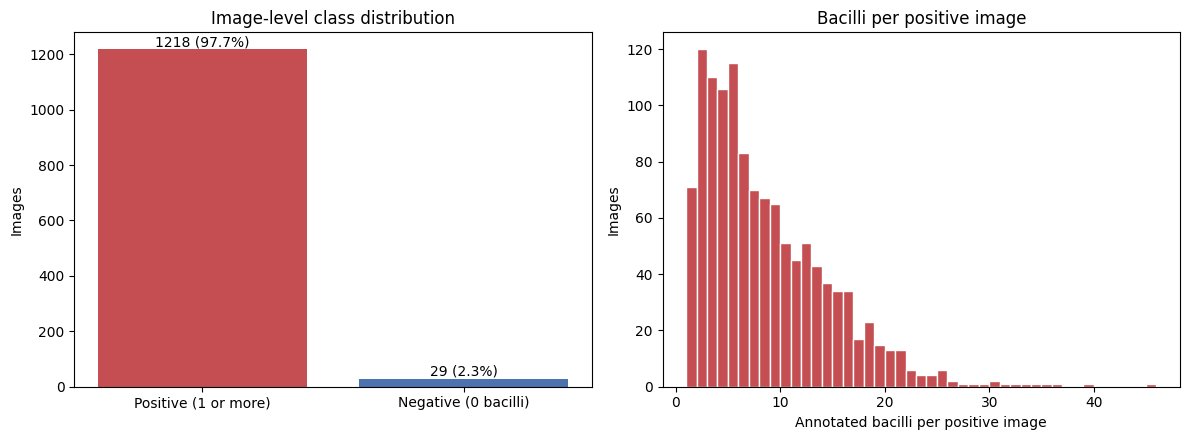

[5.1] Class counts: {'Positive (1 or more)': 1218, 'Negative (0 bacilli)': 29}
[5.1] Bacilli per positive image: median 7.0, IQR 4.0 to 12.0, max 45
[5.1] Imbalance ratio (positive:negative): 42.0 : 1


In [ ]:
# CELL 5.1  Class distribution and bacilli per image
start_cell("5.1", "Class distribution and bacilli counts")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = labelled["label"].map({0: "Negative (0 bacilli)", 1: "Positive (1 or more)"}).value_counts()
bars = axes[0].bar(counts.index, counts.values,
                   color=["#C44E52" if name.startswith("Positive") else "#4C72B0" for name in counts.index])
for bar, value in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value, f"{value} ({value / len(labelled):.1%})",
                 ha="center", va="bottom")
axes[0].set_ylabel("Images")
axes[0].set_title("Image-level class distribution")
positives = labelled[labelled["label"] == 1]["n_bacilli"]
axes[1].hist(positives, bins=range(1, int(positives.max()) + 2), color="#C44E52", edgecolor="white")
axes[1].set_xlabel("Annotated bacilli per positive image")
axes[1].set_ylabel("Images")
axes[1].set_title("Bacilli per positive image")
fig.tight_layout()
save_fig(fig, "fig_5_1_class_distribution")
plt.show()
log(f"Class counts: {counts.to_dict()}")
log(f"Bacilli per positive image: median {positives.median():.1f}, IQR "
    f"{positives.quantile(0.25):.1f} to {positives.quantile(0.75):.1f}, max {positives.max():.0f}")
log(f"Imbalance ratio (positive:negative): "
    f"{(counts.get('Positive (1 or more)', 0) / max(counts.get('Negative (0 bacilli)', 0), 1)):.1f} : 1")

### 5.2 Bounding-box geometry

The annotations are used here only to characterise the dataset. They are never used as model inputs, since the study is an image-level classification task, not detection. Box width, height and area describe how large a bacillus appears relative to the 1632 x 1224 original frame, which is what actually survives the resize to 224 x 224 used in Section 6.

[5.2] Figure saved: outputs/figures/fig_5_2_box_geometry.png


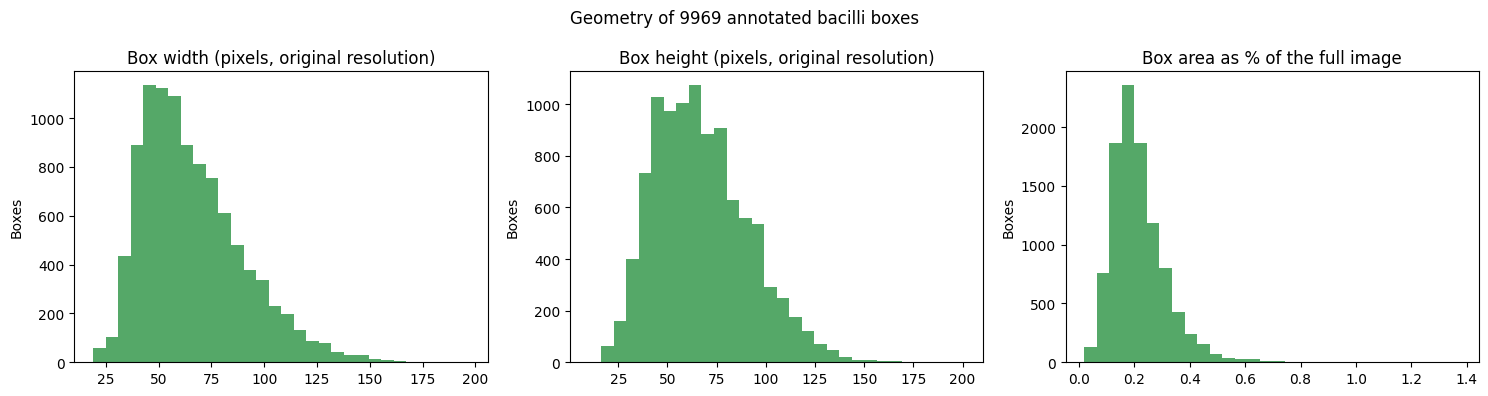

[5.2] Box width (original px): median 62.0, IQR 48.0 to 80.0
[5.2] Box height (original px): median 64.0, IQR 49.0 to 82.0
[5.2] Box area: median 0.198% of the frame
[5.2] After resizing to 224 x 224, a median box is approximately 8.5 x 11.7 pixels. Report this figure in the Methodology as evidence of how much detail survives the resize.


In [ ]:
# CELL 5.2  Bounding-box width, height and area distribution
start_cell("5.2", "Bounding-box geometry")

box_rows = []
for _, row in labelled[labelled["label"] == 1].iterrows():
    for box in json.loads(row["boxes_json"]):
        if box is None:
            continue
        x0, y0, x1, y1 = box
        box_rows.append({"image_id": row["image_id"], "width_px": x1 - x0, "height_px": y1 - y0,
                         "area_px2": (x1 - x0) * (y1 - y0),
                         "area_frac": ((x1 - x0) * (y1 - y0)) / (row["width"] * row["height"])})
BOXES = pd.DataFrame(box_rows)
BOXES.to_csv(DIRS["manifests"] / "bacilli_box_geometry.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(BOXES["width_px"], bins=30, color="#55A868")
axes[0].set_title("Box width (pixels, original resolution)")
axes[1].hist(BOXES["height_px"], bins=30, color="#55A868")
axes[1].set_title("Box height (pixels, original resolution)")
axes[2].hist(BOXES["area_frac"] * 100, bins=30, color="#55A868")
axes[2].set_title("Box area as % of the full image")
for ax in axes:
    ax.set_ylabel("Boxes")
fig.suptitle(f"Geometry of {len(BOXES)} annotated bacilli boxes")
fig.tight_layout()
save_fig(fig, "fig_5_2_box_geometry")
plt.show()

side_after_resize = CONFIG["preprocessing"]["image_size"]
scale_x = side_after_resize / labelled["width"].iloc[0]
scale_y = side_after_resize / labelled["height"].iloc[0]
approx_w_224 = BOXES["width_px"] * scale_x
approx_h_224 = BOXES["height_px"] * scale_y
log(f"Box width (original px): median {BOXES['width_px'].median():.1f}, "
    f"IQR {BOXES['width_px'].quantile(0.25):.1f} to {BOXES['width_px'].quantile(0.75):.1f}")
log(f"Box height (original px): median {BOXES['height_px'].median():.1f}, "
    f"IQR {BOXES['height_px'].quantile(0.25):.1f} to {BOXES['height_px'].quantile(0.75):.1f}")
log(f"Box area: median {BOXES['area_frac'].median() * 100:.3f}% of the frame")
log(f"After resizing to {side_after_resize} x {side_after_resize}, a median box is approximately "
    f"{approx_w_224.median():.1f} x {approx_h_224.median():.1f} pixels. Report this figure in the "
    "Methodology as evidence of how much detail survives the resize.")

### 5.3 Spatial distribution of bacilli within the frame

If annotated bacilli cluster in a particular region of the image (for example, always centred, because of how the microscope field was framed), a model could partly learn field position rather than bacillus appearance. This heatmap checks for that, and the edge-proximity figure is directly relevant to the random-crop augmentation defined in Section 6.

[5.3] Figure saved: outputs/figures/fig_5_3_bacilli_spatial_heatmap.png


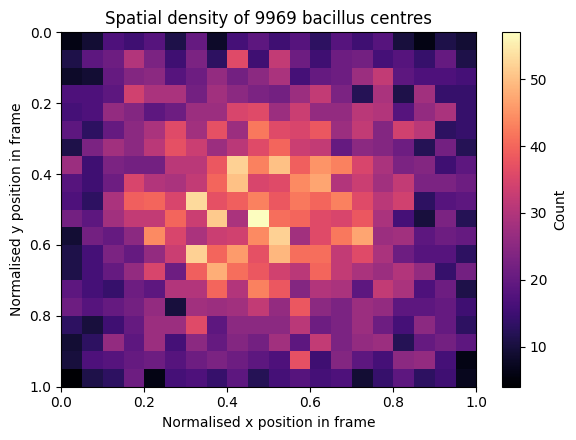

[5.3] Bacillus centre x: mean 0.499 (0.5 = frame centre), SD 0.256
[5.3] Bacillus centre y: mean 0.498 (0.5 = frame centre), SD 0.258
[5.3] Bacilli within 10% of a frame edge: 24.1%. A high figure here is relevant to the random-crop augmentation in Section 6, which could crop bacilli out of a training image.


In [ ]:
# CELL 5.3  Spatial heatmap of bacillus centres (normalised to a common frame)
start_cell("5.3", "Spatial distribution of bacilli")

centres_x, centres_y = [], []
for _, row in labelled[labelled["label"] == 1].iterrows():
    for box in json.loads(row["boxes_json"]):
        if box is None:
            continue
        x0, y0, x1, y1 = box
        centres_x.append((x0 + x1) / 2 / row["width"])
        centres_y.append((y0 + y1) / 2 / row["height"])

fig, ax = plt.subplots(figsize=(6, 4.5))
h = ax.hist2d(centres_x, centres_y, bins=20, range=[[0, 1], [0, 1]], cmap="magma")
ax.invert_yaxis()
ax.set_xlabel("Normalised x position in frame")
ax.set_ylabel("Normalised y position in frame")
ax.set_title(f"Spatial density of {len(centres_x)} bacillus centres")
fig.colorbar(h[3], ax=ax, label="Count")
fig.tight_layout()
save_fig(fig, "fig_5_3_bacilli_spatial_heatmap")
plt.show()

cx, cy = np.array(centres_x), np.array(centres_y)
log(f"Bacillus centre x: mean {cx.mean():.3f} (0.5 = frame centre), SD {cx.std():.3f}")
log(f"Bacillus centre y: mean {cy.mean():.3f} (0.5 = frame centre), SD {cy.std():.3f}")
EDGE_FRACTION = float(np.mean((cx < 0.1) | (cx > 0.9) | (cy < 0.1) | (cy > 0.9)))
log(f"Bacilli within 10% of a frame edge: {EDGE_FRACTION:.1%}. A high figure here is relevant to the "
    "random-crop augmentation in Section 6, which could crop bacilli out of a training image.")

[5.4] Resolution (width x height): count
[5.4]   1632 x 1224: 1247
[5.4] Aspect ratio (width / height): min 1.333, median 1.333, max 1.333
[5.4] All images are resized to 224 x 224 (proposal Section 3.3); non-square images are therefore stretched.
[5.4] Per-image colour statistics by class (mean and SD across images):
[5.4]               R               G               B         brightness         contrast        
[5.4]            mean     std    mean     std    mean     std       mean     std     mean     std
[5.4]   label                                                                                    
[5.4]   0      0.6316  0.0695  0.4740  0.0376  0.4496  0.0507     0.5184  0.0315   0.1256  0.0273
[5.4]   1      0.6017  0.0687  0.4919  0.0319  0.4545  0.0593     0.5160  0.0327   0.1134  0.0244
[5.4] Figure saved: outputs/figures/fig_5_4_colour_statistics.png


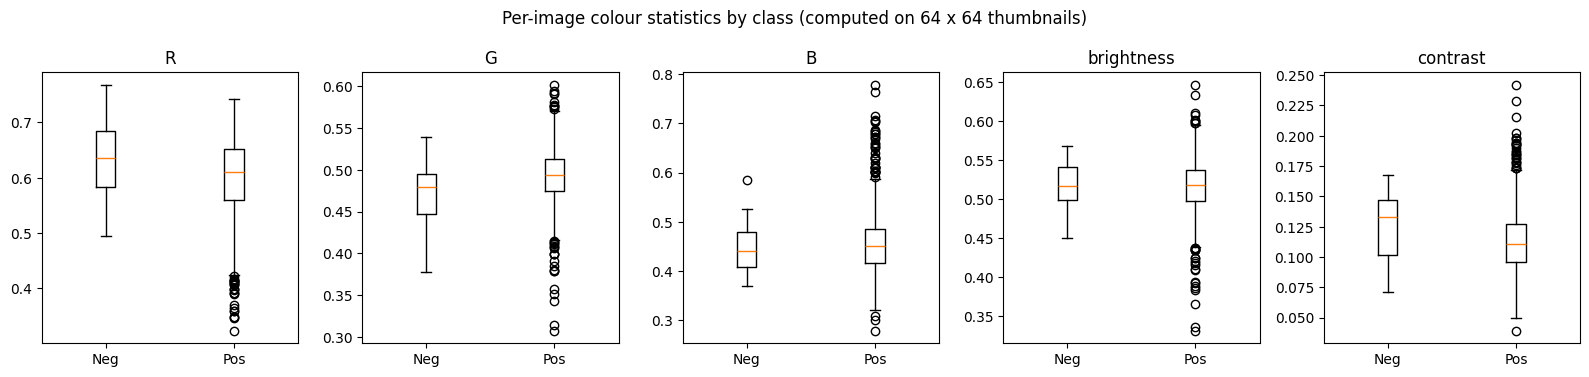

In [ ]:
# CELL 5.4  Image resolution and colour statistics by class, and per-image feature extraction
start_cell("5.4", "Resolution and colour statistics")

size_counts = labelled.groupby(["width", "height"]).size().sort_values(ascending=False)
log("Resolution (width x height): count")
for (w, h), n in size_counts.head(10).items():
    log(f"  {int(w)} x {int(h)}: {n}")
if len(size_counts) > 10:
    log(f"  ... {len(size_counts) - 10} further resolutions")
aspect = labelled["width"] / labelled["height"]
log(f"Aspect ratio (width / height): min {aspect.min():.3f}, median {aspect.median():.3f}, max {aspect.max():.3f}")
log(f"All images are resized to {CONFIG['preprocessing']['image_size']} x {CONFIG['preprocessing']['image_size']} "
    "(proposal Section 3.3); non-square images are therefore stretched.")

feature_rows = []
for _, row in labelled.iterrows():
    with Image.open(DATA_ROOT / row["image_path"]) as img:
        rgb = img.convert("RGB")
        arr = np.asarray(rgb.resize((64, 64)), dtype=np.float32) / 255.0
        gray = np.asarray(rgb.convert("L").resize((256, 256)), dtype=np.float64)
    laplacian = ndimage.laplace(gray)
    sobel_x, sobel_y = ndimage.sobel(gray, axis=0), ndimage.sobel(gray, axis=1)
    edge_magnitude = np.hypot(sobel_x, sobel_y)
    feature_rows.append({
        "image_id": row["image_id"], "label": row["label"],
        "R": arr[..., 0].mean(), "G": arr[..., 1].mean(), "B": arr[..., 2].mean(),
        "brightness": arr.mean(), "contrast": arr.std(),
        "sharpness_laplacian_var": laplacian.var(),
        "edge_density": float((edge_magnitude > np.percentile(edge_magnitude, 90)).mean()),
    })
FEATURES = pd.DataFrame(feature_rows)
FEATURES.to_csv(DIRS["manifests"] / "image_level_features.csv", index=False)

summary = FEATURES.groupby("label")[["R", "G", "B", "brightness", "contrast"]].agg(["mean", "std"]).round(4)
log("Per-image colour statistics by class (mean and SD across images):")
for line in summary.to_string().splitlines():
    log("  " + line)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, column in zip(axes, ["R", "G", "B", "brightness", "contrast"]):
    data = [FEATURES.loc[FEATURES["label"] == k, column] for k in (0, 1)]
    ax.boxplot(data)
    ax.set_xticks([1, 2], ["Neg", "Pos"])
    ax.set_title(column)
fig.suptitle("Per-image colour statistics by class (computed on 64 x 64 thumbnails)")
fig.tight_layout()
save_fig(fig, "fig_5_4_colour_statistics")
plt.show()

### 5.5 Image sharpness and edge density

The manual review in Section 4.5 found that some rejected negative images were noticeably out of focus. This cell quantifies sharpness for every retained image, so "some negatives were blurry" becomes a specific, reportable statistic rather than an impression, using the variance of the Laplacian, a standard focus measure: a sharply focused image has more high-frequency detail, and so a higher Laplacian variance, than a blurred one.

[5.5] Sharpness (Laplacian variance; higher = sharper) and edge density by class:
[5.5]         sharpness_laplacian_var                   edge_density                
[5.5]                            mean      std   median         mean     std  median
[5.5]   label                                                                       
[5.5]   0                     26.4412  26.7576  15.9965       0.0995  0.0015  0.0998
[5.5]   1                     23.3843  21.2823  17.0141       0.0997  0.0004  0.0998
[5.5] Figure saved: outputs/figures/fig_5_5_sharpness_edge_density.png


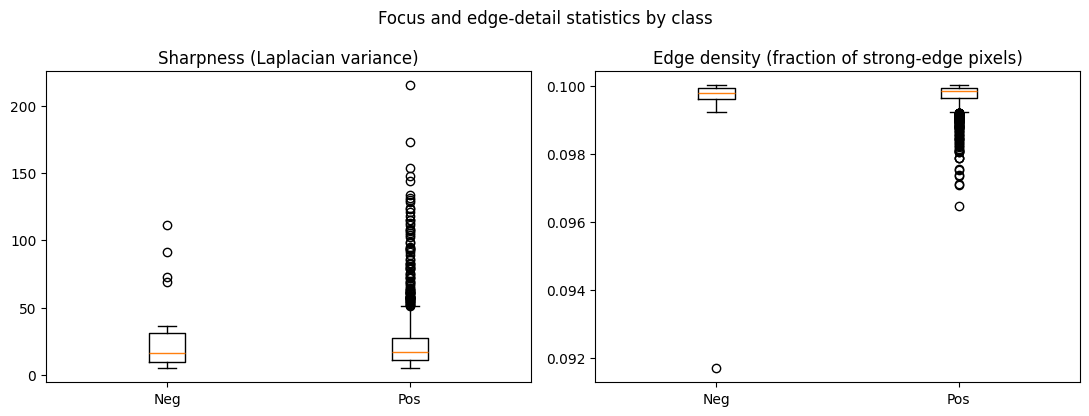

[5.5] Mann-Whitney U test, sharpness by class: U = 16952.0, p = 0.7116 (descriptive check for Discussion; not one of the four pre-registered hypotheses)


In [ ]:
# CELL 5.5  Sharpness and edge density by class
start_cell("5.5", "Sharpness and edge density")

sharp_summary = FEATURES.groupby("label")[["sharpness_laplacian_var", "edge_density"]].agg(["mean", "std", "median"]).round(4)
log("Sharpness (Laplacian variance; higher = sharper) and edge density by class:")
for line in sharp_summary.to_string().splitlines():
    log("  " + line)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, column, title in [(axes[0], "sharpness_laplacian_var", "Sharpness (Laplacian variance)"),
                          (axes[1], "edge_density", "Edge density (fraction of strong-edge pixels)")]:
    data = [FEATURES.loc[FEATURES["label"] == k, column] for k in (0, 1)]
    ax.boxplot(data)
    ax.set_xticks([1, 2], ["Neg", "Pos"])
    ax.set_title(title)
fig.suptitle("Focus and edge-detail statistics by class")
fig.tight_layout()
save_fig(fig, "fig_5_5_sharpness_edge_density")
plt.show()

neg_sharp = FEATURES.loc[FEATURES["label"] == 0, "sharpness_laplacian_var"]
pos_sharp = FEATURES.loc[FEATURES["label"] == 1, "sharpness_laplacian_var"]
SHARPNESS_U, SHARPNESS_P = stats.mannwhitneyu(neg_sharp, pos_sharp, alternative="two-sided")
log(f"Mann-Whitney U test, sharpness by class: U = {SHARPNESS_U:.1f}, p = {SHARPNESS_P:.4f} "
    "(descriptive check for Discussion; not one of the four pre-registered hypotheses)")
if SHARPNESS_P < 0.05:
    log("Sharpness differs significantly by class. State plainly in Discussion/Limitations that this could "
        "give the models a non-diagnostic shortcut, and that it motivated the manual review in Section 4.5.")

### 5.6 Feature correlations with class

This checks, quantitatively, whether any single easily-computed image property is a strong proxy for the label on its own. A strong correlation here would be a warning sign for the interpretability analysis in Section 10.4: a model could achieve good accuracy by learning a shortcut such as overall brightness rather than the presence of bacilli.

[5.6] Point-biserial correlation of each feature with the class label (label 1 = positive):
[5.6]   G: r = +0.084
[5.6]   edge_density: r = +0.076
[5.6]   contrast: r = -0.075
[5.6]   R: r = -0.066
[5.6]   sharpness_laplacian_var: r = -0.022
[5.6]   B: r = +0.013
[5.6]   brightness: r = -0.011
[5.6] Figure saved: outputs/figures/fig_5_6_feature_correlation.png


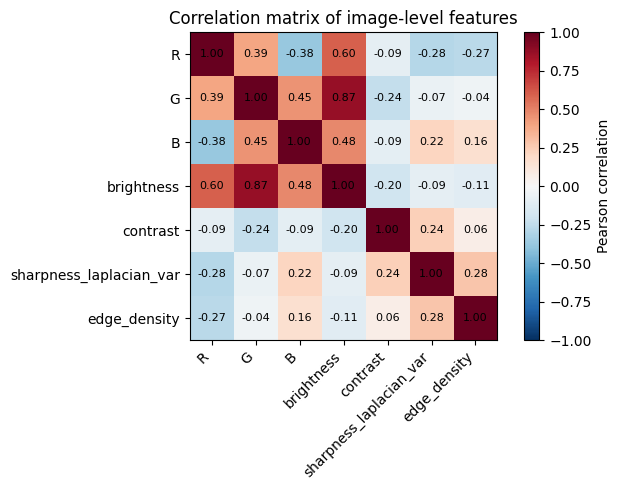

[5.6] Strongest single-feature correlate of the class label: G (r = +0.084). A magnitude above about 0.3 to 0.4 is worth naming explicitly in Discussion as a potential shortcut.


In [ ]:
# CELL 5.6  Correlation of extracted features with the class label
start_cell("5.6", "Feature correlations with class")

feature_cols = ["R", "G", "B", "brightness", "contrast", "sharpness_laplacian_var", "edge_density"]
corr_with_label = FEATURES[feature_cols + ["label"]].corr(numeric_only=True)["label"].drop("label").sort_values(
    key=abs, ascending=False)
log("Point-biserial correlation of each feature with the class label (label 1 = positive):")
for feature, value in corr_with_label.items():
    log(f"  {feature}: r = {value:+.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
corr_matrix = FEATURES[feature_cols].corr(numeric_only=True)
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=45, ha="right")
ax.set_yticks(range(len(feature_cols)), feature_cols)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix of image-level features")
fig.tight_layout()
save_fig(fig, "fig_5_6_feature_correlation")
plt.show()

STRONGEST_FEATURE = corr_with_label.abs().idxmax()
log(f"Strongest single-feature correlate of the class label: {STRONGEST_FEATURE} "
    f"(r = {corr_with_label[STRONGEST_FEATURE]:+.3f}). A magnitude above about 0.3 to 0.4 is worth naming "
    "explicitly in Discussion as a potential shortcut.")

### 5.7 Near-duplicate content check

The gate (Section 4.3) removes byte-identical duplicates. This cell checks for images that are *visually* near-identical but not byte-identical, for example the same microscope field saved twice at slightly different compression settings. A perceptual average-hash is used: each image is reduced to an 8 x 8 greyscale thumbnail and thresholded against its own mean, giving a 64-bit fingerprint; two images with a small Hamming distance between fingerprints are visually similar.

**This check is diagnostic only.** With the final labelled set already fixed in Section 4.6, any near-duplicates found here are reported as a limitation rather than used to exclude further images at this stage, unless a pair is found to cross the train/test boundary (checked in Section 7.1), in which case it is a leakage risk that must be resolved before training.

[5.7] Near-duplicate threshold: Hamming distance <= 5 of 64 bits
[5.7] Near-duplicate pairs found: 259 (byte-identical duplicates were already removed in Section 4.6)
[5.7]   IMG_0067 <-> IMG_0788: distance 0
[5.7]   IMG_0060 <-> IMG_0553: distance 0
[5.7]   IMG_0076 <-> IMG_0503: distance 0
[5.7]   IMG_0110 <-> IMG_0235: distance 0
[5.7]   IMG_0629 <-> IMG_0702: distance 0
[5.7]   IMG_0404 <-> IMG_0515: distance 0
[5.7]   IMG_0392 <-> IMG_0528: distance 0
[5.7]   IMG_0387 <-> IMG_0638: distance 0
[5.7]   IMG_0201 <-> IMG_1238: distance 0
[5.7]   IMG_0110 <-> IMG_1253: distance 0
[5.7]   ... 249 further pairs in outputs/manifests/near_duplicate_pairs.csv
[5.7] ACTION: Cell 7.1 checks this list against the split and flags any pair that crosses the train-val/test boundary. Resolve any such pair before training.


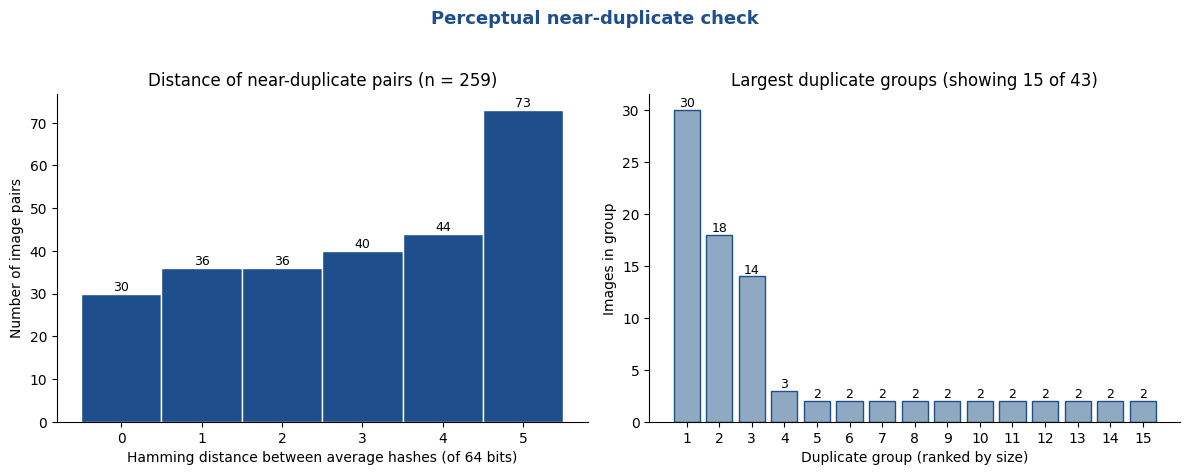

[5.7] Figure saved: outputs/figures/fig_5_7_near_duplicate_summary.png
[5.7] Exact hash matches (distance 0): 30 of 259 pairs (11.6%)
[5.7] Distinct images involved: 143 of 1247 (11.5%)
[5.7] Duplicate groups: 43 | largest group: 30 images | median group size: 2.0


In [ ]:
# CELL 5.7  Perceptual near-duplicate check (average hash, Hamming distance)
# CODE ATTRIBUTION: the average-hash method follows the widely used approach popularised by
# the imagehash package documentation, https://github.com/JohannesBuchner/imagehash; the hash
# and distance computation are implemented directly for this study, without that dependency.
start_cell("5.7", "Near-duplicate content check")


def average_hash(path: Path, hash_size: int = 8) -> np.ndarray:
    with Image.open(path) as img:
        small = np.asarray(img.convert("L").resize((hash_size, hash_size), Image.LANCZOS), dtype=np.float64)
    return (small > small.mean()).ravel()


hashes = np.stack([average_hash(DATA_ROOT / p) for p in labelled["image_path"]])
n = len(hashes)
hamming = np.zeros((n, n), dtype=np.int16)
for i in range(n):
    hamming[i] = (hashes[i] != hashes).sum(axis=1)
threshold = CONFIG["dataset"]["near_duplicate_hamming_threshold"]
np.fill_diagonal(hamming, 64)
close_pairs = np.argwhere((hamming <= threshold) & (np.triu(np.ones_like(hamming, dtype=bool), k=1)))

pair_records = [{"image_id_a": labelled["image_id"].iloc[i], "image_id_b": labelled["image_id"].iloc[j],
                 "hamming_distance": int(hamming[i, j])} for i, j in close_pairs]
PAIRS_DF = pd.DataFrame(pair_records).sort_values("hamming_distance") if pair_records else pd.DataFrame(
    columns=["image_id_a", "image_id_b", "hamming_distance"])
PAIRS_DF.to_csv(DIRS["manifests"] / "near_duplicate_pairs.csv", index=False)
log(f"Near-duplicate threshold: Hamming distance <= {threshold} of 64 bits")
log(f"Near-duplicate pairs found: {len(PAIRS_DF)} (byte-identical duplicates were already removed in Section 4.6)")
for _, r in PAIRS_DF.head(10).iterrows():
    log(f"  {r['image_id_a']} <-> {r['image_id_b']}: distance {r['hamming_distance']}")
if len(PAIRS_DF) > 10:
    log(f"  ... {len(PAIRS_DF) - 10} further pairs in outputs/manifests/near_duplicate_pairs.csv")
if PAIRS_DF.empty:
    log("No near-duplicates found at this threshold.")
else:
    log("ACTION: Cell 7.1 checks this list against the split and flags any pair that crosses the "
        "train-val/test boundary. Resolve any such pair before training.")

    # ---- Figure 5.7: distance distribution and duplicate groups ----
    # Group images that are linked through one or more near-duplicate pairs (union-find),
    # because a single image can appear in several pairs and the groups are what matter
    # for a leakage-safe split.
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for a, b in zip(PAIRS_DF["image_id_a"], PAIRS_DF["image_id_b"]):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    group_counts = {}
    for img_id in list(parent):
        root = find(img_id)
        group_counts[root] = group_counts.get(root, 0) + 1
    group_sizes = sorted(group_counts.values(), reverse=True)

    n_pairs = len(PAIRS_DF)
    n_images_involved = len(parent)
    n_groups = len(group_sizes)
    n_exact = int((PAIRS_DF["hamming_distance"] == 0).sum())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    ax = axes[0]
    bins = np.arange(-0.5, threshold + 1.5, 1)
    counts, _, bars = ax.hist(PAIRS_DF["hamming_distance"], bins=bins, color="#1F4E8C", edgecolor="white")
    for count, bar in zip(counts, bars):
        if count > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, count, str(int(count)),
                    ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(0, threshold + 1))
    ax.set_xlabel("Hamming distance between average hashes (of 64 bits)")
    ax.set_ylabel("Number of image pairs")
    ax.set_title(f"Distance of near-duplicate pairs (n = {n_pairs})")
    ax.spines[["top", "right"]].set_visible(False)

    ax = axes[1]
    top_groups = group_sizes[:15]
    ax.bar(range(1, len(top_groups) + 1), top_groups, color="#8EA9C1", edgecolor="#1F4E8C")
    for rank, size in enumerate(top_groups, start=1):
        ax.text(rank, size, str(size), ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(1, len(top_groups) + 1))
    ax.set_xlabel("Duplicate group (ranked by size)")
    ax.set_ylabel("Images in group")
    ax.set_title(f"Largest duplicate groups (showing {len(top_groups)} of {n_groups})")
    ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle("Perceptual near-duplicate check", fontsize=13, fontweight="bold", color="#1F4E8C")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig_path = DIRS["figures"] / "fig_5_7_near_duplicate_summary.png"
    fig.savefig(fig_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    log(f"Figure saved: outputs/figures/{fig_path.name}")
    log(f"Exact hash matches (distance 0): {n_exact} of {n_pairs} pairs ({100 * n_exact / n_pairs:.1f}%)")
    log(f"Distinct images involved: {n_images_involved} of {n} ({100 * n_images_involved / n:.1f}%)")
    log(f"Duplicate groups: {n_groups} | largest group: {group_sizes[0]} images | "
        f"median group size: {np.median(group_sizes):.1f}")

[5.8] Figure saved: outputs/figures/fig_5_8_final_negative_spot_check.png


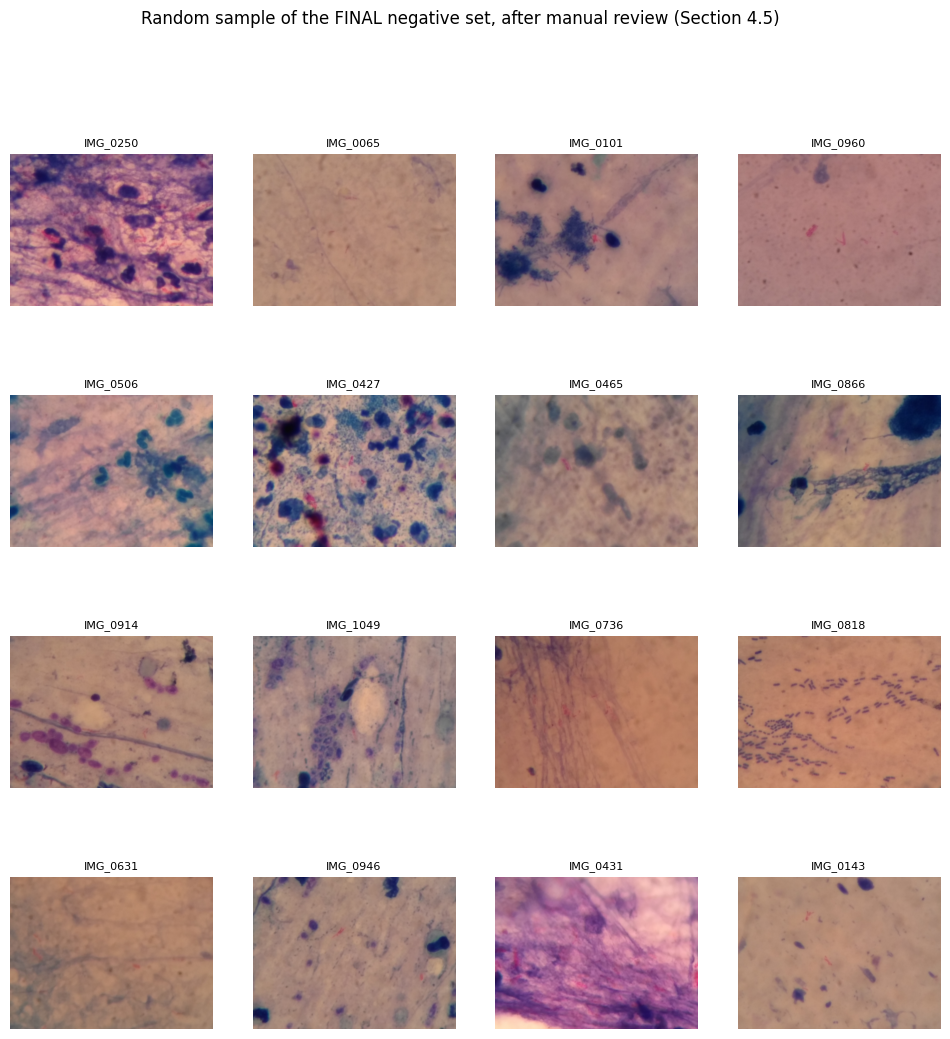

[5.8] Spot-check sample IDs: IMG_0250, IMG_0065, IMG_0101, IMG_0960, IMG_0506, IMG_0427, IMG_0465, IMG_0866, IMG_0914, IMG_1049, IMG_0736, IMG_0818, IMG_0631, IMG_0946, IMG_0431, IMG_0143


In [ ]:
# CELL 5.8  Visual spot check of the final negative set (post-review)
start_cell("5.8", "Visual spot check of the final negative set")

rng = np.random.default_rng(SEED)
negatives = labelled[labelled["label"] == 0]
sample = negatives.iloc[rng.choice(len(negatives), size=min(16, len(negatives)), replace=False)]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    with Image.open(DATA_ROOT / row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row["image_id"], fontsize=8)
fig.suptitle("Random sample of the FINAL negative set, after manual review (Section 4.5)")
save_fig(fig, "fig_5_8_final_negative_spot_check")
plt.show()
log(f"Spot-check sample IDs: {', '.join(sample['image_id'])}")

[5.9] Figure saved: outputs/figures/fig_5_9_sample_images.png


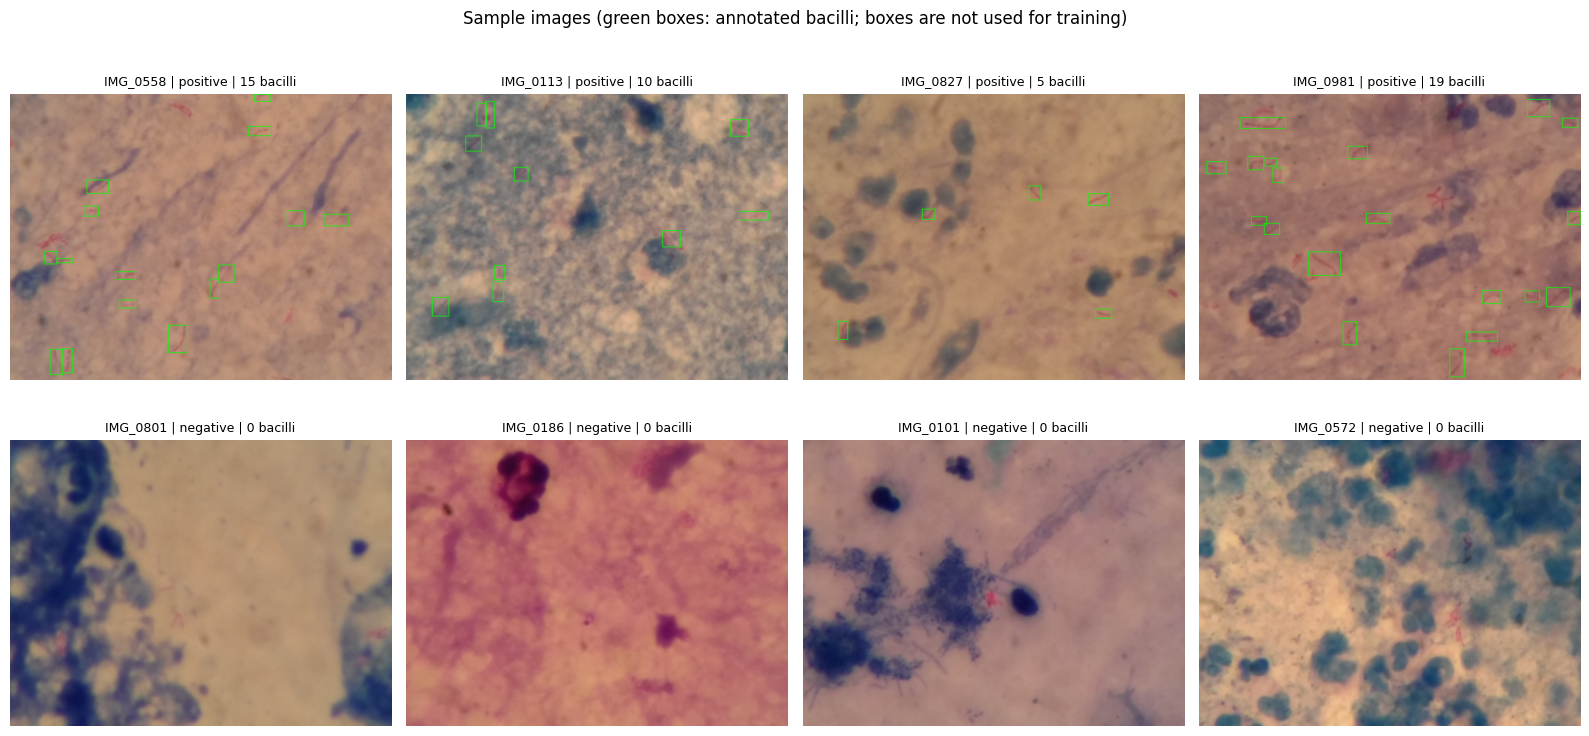

In [ ]:
# CELL 5.9  Sample images with annotated bacilli
start_cell("5.9", "Sample images")

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row_index, label_value in enumerate([1, 0]):
    subset = labelled[labelled["label"] == label_value]
    chosen = subset.iloc[rng.choice(len(subset), size=min(4, len(subset)), replace=False)]
    for col_index in range(4):
        ax = axes[row_index, col_index]
        ax.axis("off")
        if col_index >= len(chosen):
            continue
        item = chosen.iloc[col_index]
        with Image.open(DATA_ROOT / item["image_path"]) as img:
            canvas = img.convert("RGB")
        draw = ImageDraw.Draw(canvas)
        for box in json.loads(item["boxes_json"]):
            if box is not None:
                draw.rectangle(box, outline=(0, 255, 0), width=3)
        ax.imshow(canvas)
        ax.set_title(f"{item['image_id']} | {'positive' if label_value else 'negative'} | "
                     f"{int(item['n_bacilli'])} bacilli", fontsize=9)
fig.suptitle("Sample images (green boxes: annotated bacilli; boxes are not used for training)")
fig.tight_layout()
save_fig(fig, "fig_5_9_sample_images")
plt.show()

In [ ]:
# CELL 5.10  EDA summary table
start_cell("5.10", "EDA summary")

eda_summary = pd.DataFrame([
    {"item": "Final images", "value": len(labelled)},
    {"item": "Positive images", "value": int((labelled["label"] == 1).sum())},
    {"item": "Negative images", "value": int((labelled["label"] == 0).sum())},
    {"item": "Median bacilli per positive image", "value": float(labelled.loc[labelled["label"] == 1, "n_bacilli"].median())},
    {"item": "Median bacillus box area (% of frame)", "value": round(float(BOXES["area_frac"].median() * 100), 3)},
    {"item": "Bacilli within 10% of a frame edge (%)", "value": round(EDGE_FRACTION * 100, 1)},
    {"item": "Sharpness Mann-Whitney p-value (class difference)", "value": round(float(SHARPNESS_P), 4)},
    {"item": "Strongest single-feature correlate of label", "value": STRONGEST_FEATURE},
    {"item": "Near-duplicate pairs (Hamming <= threshold)", "value": len(PAIRS_DF)},
])
eda_summary.to_csv(DIRS["tables"] / "table_5_10_eda_summary.csv", index=False)
log("EDA summary (also written to outputs/tables/table_5_10_eda_summary.csv):")
for line in eda_summary.to_string(index=False).splitlines():
    log("  " + line)

[5.10] EDA summary (also written to outputs/tables/table_5_10_eda_summary.csv):
[5.10]                                                item   value
[5.10]                                        Final images    1247
[5.10]                                     Positive images    1218
[5.10]                                     Negative images      29
[5.10]                   Median bacilli per positive image     7.0
[5.10]               Median bacillus box area (% of frame)   0.198
[5.10]              Bacilli within 10% of a frame edge (%)    24.1
[5.10]   Sharpness Mann-Whitney p-value (class difference)  0.7116
[5.10]         Strongest single-feature correlate of label       G
[5.10]         Near-duplicate pairs (Hamming <= threshold)     259


In [ ]:
# CELL 5.11  Archive pre-fix training artifacts (run again before the group-aware split)
start_cell("5.11", "Archive pre-fix training artifacts")

import shutil
archive_root = OUT / f"superseded_pre_groupsplit_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
targets = [
    DIRS["results"] / "cv_runs",
    DIRS["models"] / "resnet50_final.pt",
    DIRS["models"] / "vit_base_final.pt",
    DIRS["results"] / "test_predictions.csv",
    DIRS["results"] / "TEST_SET_UNLOCKED.txt",
    DIRS["results"] / "resnet50_selected_config.json",
    DIRS["results"] / "vit_base_selected_config.json",
    DIRS["logs"] / "cv",
    DIRS["logs"] / "final_resnet50.csv",
    DIRS["logs"] / "final_vit_base.csv",
]
moved = []
for path in targets:
    if path.exists():
        dest = archive_root / path.relative_to(OUT)
        dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(path), str(dest))
        moved.append(str(path.relative_to(OUT)))
if moved:
    log(f"Archived {len(moved)} stale item(s) to outputs/{archive_root.name}/:")
    for item in moved:
        log(f"  {item}")
else:
    log("Nothing to archive.")

[5.11] Nothing to archive.


# 6. Data Preprocessing and Augmentation

Every image is resized once to 224 x 224 and held in memory, so both architectures receive exactly the same resized pixels. Training data then receive random augmentation (D3); validation and test data receive no augmentation, only tensor conversion and normalisation, so evaluation is carried out on unmodified images (proposal Section 3.3).

Colour jitter changes brightness, contrast and saturation only. **Hue is deliberately not altered**, because the red colour of acid-fast bacilli against the blue counterstain is the diagnostic signal in ZN microscopy (consistent with the colour statistics in Section 5.4), and shifting hue would corrupt it.

**Normalisation (P1).** With `per_backbone`, each model receives inputs normalised with the statistics its pretrained weights were trained with, read from library metadata rather than typed in by hand. Every other step is identical for both models.

This section builds the pipeline from the full labelled set; it does not require the train/test split, which is created afterwards in Section 7.

In [ ]:
# CELL 6.1  Resize once and cache every included image in memory
start_cell("6.1", "Image cache")

IMG_SIZE = CONFIG["preprocessing"]["image_size"]
IMAGE_CACHE = {}
for _, row in labelled.iterrows():
    with Image.open(DATA_ROOT / row["image_path"]) as img:
        IMAGE_CACHE[row["image_id"]] = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
LABEL_OF = dict(zip(labelled["image_id"], labelled["label"].astype(int)))
cache_mb = len(IMAGE_CACHE) * IMG_SIZE * IMG_SIZE * 3 / 1024 ** 2
log(f"Cached {len(IMAGE_CACHE)} images at {IMG_SIZE} x {IMG_SIZE} RGB (about {cache_mb:.0f} MB)")

[6.1] Cached 1247 images at 224 x 224 RGB (about 179 MB)


In [ ]:
# CELL 6.2  Normalisation statistics and transform pipelines
# CODE ATTRIBUTION: transform classes follow the torchvision documentation,
#   https://pytorch.org/vision/stable/transforms.html
# Pretrained normalisation statistics are read from torchvision weight metadata and from
# timm (get_pretrained_cfg_value), https://huggingface.co/docs/timm
start_cell("6.2", "Normalisation and transforms")


def normalisation_stats(model_name: str):
    mode = CONFIG["preprocessing"]["normalisation_mode"]
    if mode == "imagenet_both":
        return CONFIG["preprocessing"]["imagenet_mean"], CONFIG["preprocessing"]["imagenet_std"]
    if model_name == "resnet50":
        weights = getattr(ResNet50_Weights, CONFIG["models"]["resnet50"]["weights"])
        preset = weights.transforms()
        return list(preset.mean), list(preset.std)
    tag = CONFIG["models"]["vit_base"]["tag"]
    return list(timm.get_pretrained_cfg_value(tag, "mean")), list(timm.get_pretrained_cfg_value(tag, "std"))


NORM = {name: normalisation_stats(name) for name in ["resnet50", "vit_base"]}
for name, (mean, std) in NORM.items():
    log(f"{name}: mean {[round(v, 4) for v in mean]} | std {[round(v, 4) for v in std]}")


def build_train_transform(model_name: str, intensity: str):
    aug = CONFIG["augmentation"]
    level = aug["intensity"][intensity]
    jitter = level["colour_jitter"]
    mean, std = NORM[model_name]
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=tuple(level["crop_scale"])),
        transforms.RandomHorizontalFlip(p=aug["hflip_p"]),
        transforms.RandomVerticalFlip(p=aug["vflip_p"]),
        transforms.RandomRotation(degrees=aug["rotation_degrees"]),
        transforms.ColorJitter(brightness=jitter, contrast=jitter, saturation=jitter),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])


def build_eval_transform(model_name: str):
    mean, std = NORM[model_name]
    return transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])


log("Training transform (low): " + str(build_train_transform("resnet50", "low")).replace("\n", " "))
log("Evaluation transform: " + str(build_eval_transform("resnet50")).replace("\n", " "))

[6.2] resnet50: mean [0.485, 0.456, 0.406] | std [0.229, 0.224, 0.225]
[6.2] vit_base: mean [0.5, 0.5, 0.5] | std [0.5, 0.5, 0.5]
[6.2] Training transform (low): Compose(     RandomResizedCrop(size=(224, 224), scale=(0.9, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)     RandomHorizontalFlip(p=0.5)     RandomVerticalFlip(p=0.5)     RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)     ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)     ToTensor()     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) )
[6.2] Evaluation transform: Compose(     ToTensor()     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) )


In [ ]:
# CELL 6.3  Dataset class and seeded DataLoaders
# CODE ATTRIBUTION: Dataset/DataLoader pattern and seeded worker initialisation follow the
# PyTorch documentation on data loading and reproducibility,
#   https://pytorch.org/docs/stable/data.html and https://pytorch.org/docs/stable/notes/randomness.html
start_cell("6.3", "Dataset and loaders")


class SmearDataset(Dataset):
    def __init__(self, image_ids, transform):
        self.image_ids = list(image_ids)
        self.transform = transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        tensor = self.transform(IMAGE_CACHE[image_id])
        return tensor, torch.tensor(float(LABEL_OF[image_id])), index


def _seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(image_ids, transform, shuffle: bool, seed: int) -> DataLoader:
    generator = torch.Generator()
    generator.manual_seed(seed)
    micro_batch = CONFIG["training"]["batch_size"] // CONFIG["training"]["grad_accum_steps"]
    return DataLoader(SmearDataset(image_ids, transform), batch_size=micro_batch, shuffle=shuffle,
                      num_workers=CONFIG["training"]["num_workers"], pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=_seed_worker, generator=generator, drop_last=False)


probe = make_loader(labelled["image_id"].iloc[:8], build_eval_transform("resnet50"), shuffle=False, seed=SEED)
batch_x, batch_y, _ = next(iter(probe))
log(f"Probe batch: tensor {tuple(batch_x.shape)}, labels {batch_y.tolist()}")

[6.3] Probe batch: tensor (8, 3, 224, 224), labels [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


[6.4] Figure saved: outputs/figures/fig_6_4_augmentation_preview.png


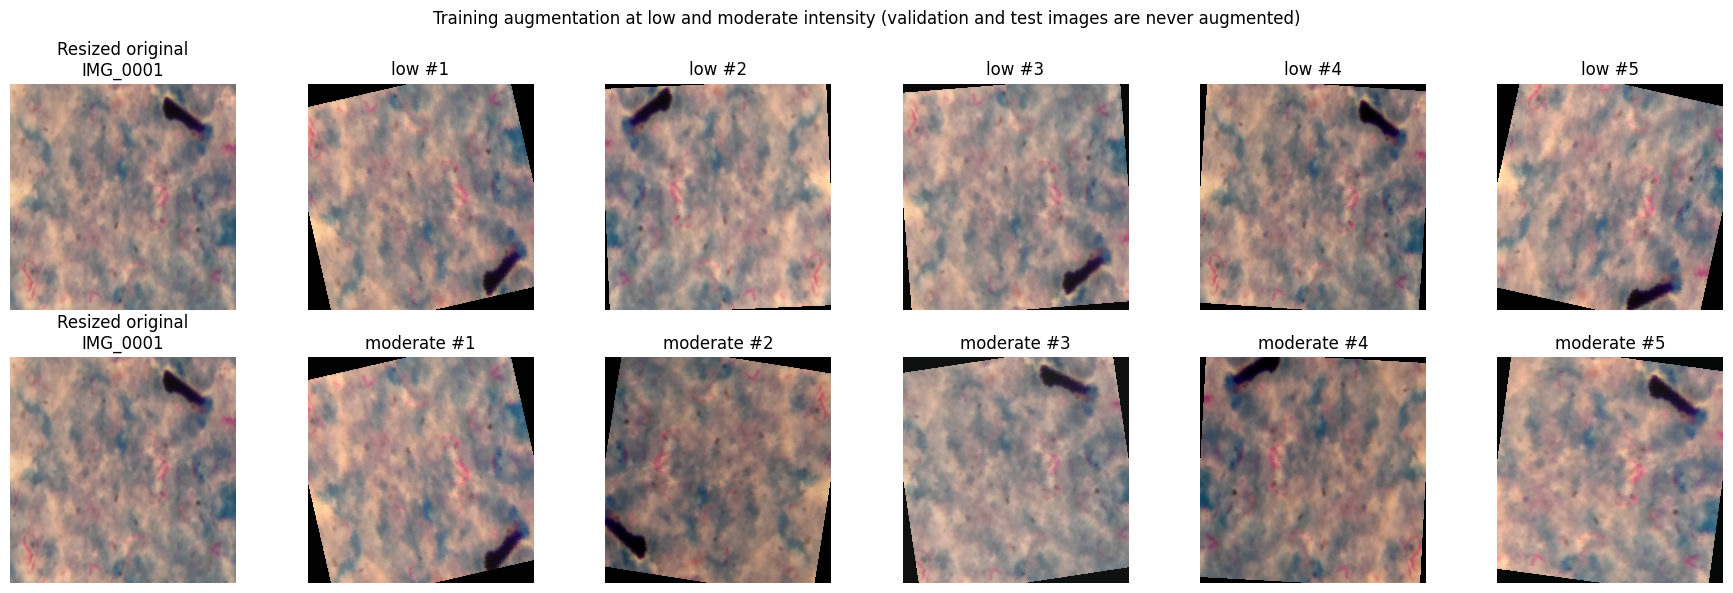

In [ ]:
# CELL 6.4  Augmentation preview (training transforms only)
start_cell("6.4", "Augmentation preview")


def denormalise(tensor, mean, std):
    arr = tensor.numpy().transpose(1, 2, 0) * np.array(std) + np.array(mean)
    return np.clip(arr, 0, 1)


example_id = labelled.loc[labelled["label"] == 1, "image_id"].iloc[0]
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for row_index, intensity in enumerate(["low", "moderate"]):
    torch.manual_seed(SEED)
    transform = build_train_transform("resnet50", intensity)
    axes[row_index, 0].imshow(IMAGE_CACHE[example_id])
    axes[row_index, 0].set_title(f"Resized original\n{example_id}")
    for col in range(1, 6):
        axes[row_index, col].imshow(denormalise(transform(IMAGE_CACHE[example_id]), *NORM["resnet50"]))
        axes[row_index, col].set_title(f"{intensity} #{col}")
    for ax in axes[row_index]:
        ax.axis("off")
fig.suptitle("Training augmentation at low and moderate intensity (validation and test images are never augmented)")
fig.tight_layout()
save_fig(fig, "fig_6_4_augmentation_preview")
plt.show()

# 7. Train-Validation-Test Split

The held-out test set (20%) is fixed here and is not touched again until Section 10.1. Five folds are assigned within the remaining 80% and are shared by both architectures, so every comparison in Sections 8 to 10 uses identical data (proposal Section 3.5). If a split file already exists it is reloaded rather than regenerated, so the split never changes between sessions unless the included image set itself changes (for example, after a review decision is corrected).

The compute benchmark that used to sit here now runs in Cell 8.0, immediately after the shared training functions it depends on are defined (Section 8.0).

In [ ]:
# CELL 7.1  Group-aware split: near-duplicate clusters kept within one partition
# CODE ATTRIBUTION: StratifiedGroupKFold and train_test_split usage follows the scikit-learn
# documentation, https://scikit-learn.org/stable/modules/cross_validation.html
# Union-find clustering of near-duplicate pairs is a standard graph-connectivity technique,
# implemented here to prevent near-duplicate leakage across partitions (see Section 5.7).
start_cell("7.1", "Group-aware split and fold assignment")

pairs_df = pd.read_csv(DIRS["manifests"] / "near_duplicate_pairs.csv")

parent = {image_id: image_id for image_id in labelled["image_id"]}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb


for _, r in pairs_df.iterrows():
    union(r["image_id_a"], r["image_id_b"])

labelled = labelled.copy()
labelled["group"] = labelled["image_id"].map(find)
group_sizes = labelled.groupby("group").size()
log(f"Near-duplicate clustering: {len(group_sizes)} groups from {len(labelled)} images "
    f"({int((group_sizes == 1).sum())} singletons, largest cluster {int(group_sizes.max())} images)")

label_counts_per_group = labelled.groupby("group")["label"].nunique()
mixed_groups = label_counts_per_group[label_counts_per_group > 1].index.tolist()
if mixed_groups:
    log(f"WARNING: {len(mixed_groups)} near-duplicate cluster(s) contain BOTH labels -- "
        "these are visually near-identical images with disagreeing labels. Report this explicitly:")
    for g in mixed_groups:
        members = labelled.loc[labelled["group"] == g, ["image_id", "label"]]
        log(f"  cluster {g}: " + ", ".join(f"{r.image_id}(label {r.label})" for r in members.itertuples()))
else:
    log("No near-duplicate cluster contains both labels.")

group_label = labelled.groupby("group")["label"].agg(lambda s: s.mode().iloc[0])

split_path = DIRS["splits"] / "split_assignment.csv"
if split_path.exists():
    archive_dir = DIRS["splits"] / "superseded"
    archive_dir.mkdir(exist_ok=True)
    archived = archive_dir / f"split_assignment_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
    split_path.rename(archived)
    log(f"Previous split (with cross-partition near-duplicates) archived to splits/superseded/{archived.name}")

groups = group_label.index.to_numpy()
g_trainval, g_test = train_test_split(
    groups, test_size=CONFIG["split"]["test_size"], stratify=group_label.to_numpy(), random_state=SEED)
test_groups = set(g_test)

assignment = labelled[["image_id", "label", "group"]].copy()
assignment["partition"] = np.where(assignment["group"].isin(test_groups), "test", "trainval")
assignment["fold"] = -1

tv_mask = assignment["partition"] == "trainval"
sgkf = StratifiedGroupKFold(n_splits=CONFIG["split"]["n_folds"], shuffle=True, random_state=SEED)
tv_idx = assignment.index[tv_mask].to_numpy()
for fold, (_, val_positions) in enumerate(
        sgkf.split(assignment.loc[tv_mask], assignment.loc[tv_mask, "label"], groups=assignment.loc[tv_mask, "group"])):
    assignment.loc[tv_idx[val_positions], "fold"] = fold

assignment = assignment.drop(columns=["group"])
assignment.to_csv(split_path, index=False)
log(f"New group-aware split written (sha256 {sha256_of_file(split_path)[:16]}...)")

merged = assignment.merge(labelled[["image_id", "md5"]], on="image_id")
test_md5 = set(merged.loc[merged["partition"] == "test", "md5"])
trainval_md5 = set(merged.loc[merged["partition"] == "trainval", "md5"])
assert not (test_md5 & trainval_md5), "Identical image content found in both test and train-val partitions"

partition_of = assignment.set_index("image_id")["partition"]
crossing = pairs_df[partition_of.reindex(pairs_df["image_id_a"]).to_numpy() !=
                    partition_of.reindex(pairs_df["image_id_b"]).to_numpy()]
assert len(crossing) == 0, f"{len(crossing)} near-duplicate pairs still cross partitions -- grouping failed"
log("Leakage checks passed: no image ID, exact file content, or near-duplicate cluster appears in both partitions.")

table = assignment.assign(group=np.where(assignment["partition"] == "test", "test",
                                         "fold " + assignment["fold"].astype(str)))
dist = table.groupby("group")["label"].agg(n="size", positives="sum")
dist["negatives"] = dist["n"] - dist["positives"]
dist["positive_share"] = (dist["positives"] / dist["n"]).round(3)
log("Partition composition:")
for line in dist.to_string().splitlines():
    log("  " + line)
log(f"Train-val total: {int((assignment['partition'] == 'trainval').sum())} | "
    f"Test total: {int((assignment['partition'] == 'test').sum())}")

TRAINVAL = assignment[assignment["partition"] == "trainval"].reset_index(drop=True)
TEST = assignment[assignment["partition"] == "test"].reset_index(drop=True)

[7.1] Near-duplicate clustering: 1147 groups from 1247 images (1104 singletons, largest cluster 30 images)
[7.1] WARNING: 3 near-duplicate cluster(s) contain BOTH labels -- these are visually near-identical images with disagreeing labels. Report this explicitly:
[7.1]   cluster IMG_0926: IMG_0465(label 0), IMG_0926(label 1)
[7.1]   cluster IMG_0942: IMG_0071(label 1), IMG_0166(label 1), IMG_0181(label 1), IMG_0216(label 1), IMG_0242(label 1), IMG_0247(label 1), IMG_0285(label 1), IMG_0492(label 1), IMG_0497(label 1), IMG_0573(label 1), IMG_0736(label 0), IMG_0886(label 1), IMG_0909(label 1), IMG_0925(label 1), IMG_0942(label 1), IMG_1239(label 1), IMG_1252(label 1), IMG_1256(label 1)
[7.1]   cluster IMG_1091: IMG_0040(label 0), IMG_1091(label 1)
[7.1] New group-aware split written (sha256 c5daa1cc5366749e...)
[7.1] Leakage checks passed: no image ID, exact file content, or near-duplicate cluster appears in both partitions.
[7.1] Partition composition:
[7.1]             n  positives  ne

# 8. Model 1: ResNet-50

### 8.0 Shared training utilities

The functions in this cell are used identically by both Model 1 (this section) and Model 2 (Section 9): the metric function, one training epoch, one prediction pass, the two-stage fine-tuning loop, the grid-search runner, the cross-validation summariser and the final retrain function. They are defined once, here, so that any change to how a model is trained or scored applies to both architectures automatically and cannot silently drift between them. Each is then simply **called with a different `model_name` argument** in Sections 8 and 9.

In [ ]:
# CELL 8.0  Metric function (shared by both models)
start_cell("8.0", "Shared training utilities: metric function")

THRESHOLD = CONFIG["training"]["decision_threshold"]


def binary_metrics(y_true, prob, threshold: float = THRESHOLD) -> dict:
    y_true = np.asarray(y_true).astype(int)
    pred = (np.asarray(prob) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    def ratio(a, b):
        return a / b if b > 0 else float("nan")

    return {
        "accuracy": ratio(tp + tn, tp + tn + fp + fn),
        "sensitivity": ratio(tp, tp + fn),
        "specificity": ratio(tn, tn + fp),
        "precision": ratio(tp, tp + fp),
        "f1": ratio(2 * tp, 2 * tp + fp + fn),
        "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else float("nan"),
        "tp": int(tp), "tn": int(tn), "fp": int(fp), "fn": int(fn),
    }


log("binary_metrics defined: accuracy, sensitivity, specificity, precision, F1 at threshold "
    f"{THRESHOLD}; AUC threshold-free")

[8.0] binary_metrics defined: accuracy, sensitivity, specificity, precision, F1 at threshold 0.5; AUC threshold-free


In [ ]:
# CELL 8.0  Model factory and freezing helpers (shared)
# CODE ATTRIBUTION: torchvision.models.resnet50 and ResNet50_Weights usage follows the torchvision
#   documentation, https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html
# timm.create_model and get_classifier follow the timm documentation, https://huggingface.co/docs/timm
start_cell("8.0", "Shared training utilities: model factory")


def build_model(model_name: str, pretrained: bool = True) -> nn.Module:
    if model_name == "resnet50":
        weights = getattr(ResNet50_Weights, CONFIG["models"]["resnet50"]["weights"]) if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, 1)
    elif model_name == "vit_base":
        model = timm.create_model(CONFIG["models"]["vit_base"]["tag"], pretrained=pretrained, num_classes=1)
    else:
        raise ValueError(model_name)
    return model


def get_head(model: nn.Module, model_name: str) -> nn.Module:
    return model.fc if model_name == "resnet50" else model.get_classifier()


def set_stage(model: nn.Module, model_name: str, stage: int) -> None:
    """Stage 1: only the head is trainable. Stage 2: every parameter is trainable."""
    for parameter in model.parameters():
        parameter.requires_grad = (stage == 2)
    if stage == 1:
        for parameter in get_head(model, model_name).parameters():
            parameter.requires_grad = True


def set_train_mode(model: nn.Module, model_name: str, stage: int) -> None:
    """In Stage 1 the frozen backbone stays in eval mode (fixed batch-norm statistics)."""
    if stage == 1:
        model.eval()
        get_head(model, model_name).train()
    else:
        model.train()


def count_parameters(model: nn.Module):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


log("build_model, get_head, set_stage, set_train_mode, count_parameters defined")

[8.0] build_model, get_head, set_stage, set_train_mode, count_parameters defined


In [ ]:
# CELL 8.0  One training epoch and one prediction pass (shared)
# CODE ATTRIBUTION: automatic mixed precision (torch.autocast, torch.amp.GradScaler) follows the
# PyTorch AMP documentation, https://pytorch.org/docs/stable/amp.html
start_cell("8.0", "Shared training utilities: epoch functions")


def train_one_epoch(model, model_name, stage, loader, criterion, optimiser, scaler) -> float:
    set_train_mode(model, model_name, stage)
    accum = CONFIG["training"]["grad_accum_steps"]
    optimiser.zero_grad(set_to_none=True)
    total_loss, n_seen = 0.0, 0
    for step, (x, y, _) in enumerate(loader, start=1):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x).squeeze(1)
            loss = criterion(logits, y)
        scaler.scale(loss / accum).backward()
        if step % accum == 0 or step == len(loader):
            scaler.step(optimiser)
            scaler.update()
            optimiser.zero_grad(set_to_none=True)
        total_loss += loss.item() * len(y)
        n_seen += len(y)
    return total_loss / n_seen


@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    probs, labels, indices, total_loss = [], [], [], 0.0
    for x, y, index in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            total_loss += criterion(logits, y).item() * len(y)
        probs.append(torch.sigmoid(logits).cpu().numpy())
        labels.append(y.cpu().numpy())
        indices.append(index.numpy())
    y_all = np.concatenate(labels).astype(int)
    return y_all, np.concatenate(probs), np.concatenate(indices), total_loss / max(len(y_all), 1)


log("train_one_epoch and predict defined")

[8.0] train_one_epoch and predict defined


In [ ]:
# CELL 8.0  Two-stage fine-tuning with early stopping on validation AUC (shared; D1, D9)
# CODE ATTRIBUTION: CosineAnnealingLR and Adam follow the torch.optim documentation,
#   https://pytorch.org/docs/stable/optim.html ; BCEWithLogitsLoss(pos_weight) follows
#   https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html
start_cell("8.0", "Shared training utilities: two-stage training function")


def _state_on_cpu(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def fit_two_stage(model_name, train_ids, val_ids, hp, seed, fixed_epochs=None, max_epochs_override=None):
    """Train one model. With val_ids, early stopping applies (cross-validation).
    With fixed_epochs=(s1, s2) and val_ids=None, trains for exactly that many epochs (final retrain)."""
    set_seed(seed)
    tcfg = CONFIG["training"]
    model = build_model(model_name).to(DEVICE)
    train_loader = make_loader(train_ids, build_train_transform(model_name, hp["aug_intensity"]), True, seed)
    val_loader = (make_loader(val_ids, build_eval_transform(model_name), False, seed)
                  if val_ids is not None else None)

    train_labels = np.array([LABEL_OF[i] for i in train_ids])
    pos_weight = (train_labels == 0).sum() / max((train_labels == 1).sum(), 1)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=DEVICE, dtype=torch.float32))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = []
    best = {"auc": -np.inf, "state": None, "stage": 0, "epoch": 0}
    s1_max, s2_max = (fixed_epochs if fixed_epochs else
                      (tcfg["stage1_max_epochs"], None))
    if max_epochs_override:
        s1_max, s2_max = max_epochs_override
    started = time.time()
    epoch_times = {1: [], 2: []}

    def run_stage(stage, n_epochs, optimiser, scheduler, patience):
        nonlocal best
        since_best, epochs_run, stage_best_epoch = 0, 0, 0
        for epoch in range(1, n_epochs + 1):
            t0 = time.time()
            train_loss = train_one_epoch(model, model_name, stage, train_loader, criterion, optimiser, scaler)
            lr_now = optimiser.param_groups[0]["lr"]
            if scheduler is not None:
                scheduler.step()
            row = {"stage": stage, "epoch": epoch, "global_epoch": len(history) + 1,
                   "lr": lr_now, "train_loss": train_loss}
            if val_loader is not None:
                y_val, p_val, _, val_loss = predict(model, val_loader, criterion)
                metrics = binary_metrics(y_val, p_val)
                row.update(val_loss=val_loss, **{f"val_{k}": v for k, v in metrics.items()})
                if metrics["auc"] > best["auc"]:
                    best = {"auc": metrics["auc"], "state": _state_on_cpu(model), "stage": stage, "epoch": epoch}
                    stage_best_epoch, since_best = epoch, 0
                else:
                    since_best += 1
            epoch_times[stage].append(time.time() - t0)
            history.append(row)
            epochs_run = epoch
            if val_loader is not None and since_best >= patience:
                break
        return epochs_run, stage_best_epoch

    # Stage 1: head only
    set_stage(model, model_name, 1)
    opt1 = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                            lr=tcfg["stage1_lr"], weight_decay=hp["weight_decay"])
    s1_run, s1_best = run_stage(1, s1_max, opt1, None, tcfg["stage1_patience"])
    if best["state"] is not None:
        model.load_state_dict(best["state"])

    # Stage 2: full network, cosine annealing over the remaining budget
    if s2_max is None:
        s2_max = tcfg["max_total_epochs"] - s1_run
    set_stage(model, model_name, 2)
    s2_run, s2_best = 0, 0
    if s2_max > 0:
        opt2 = torch.optim.Adam(model.parameters(), lr=hp["stage2_lr"], weight_decay=hp["weight_decay"])
        sched2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=s2_max)
        s2_run, s2_best = run_stage(2, s2_max, opt2, sched2, tcfg["stage2_patience"])
    if best["state"] is not None:
        model.load_state_dict(best["state"])

    summary = {
        "model": model_name, "hp": hp, "seed": seed, "pos_weight": float(pos_weight),
        "stage1_epochs_run": s1_run, "stage1_best_epoch": s1_best,
        "stage2_epochs_run": s2_run, "stage2_best_epoch": s2_best if best["stage"] == 2 else 0,
        "best_val_auc": float(best["auc"]) if val_loader is not None else None,
        "seconds_total": time.time() - started,
        "mean_seconds_per_epoch_stage1": float(np.mean(epoch_times[1])) if epoch_times[1] else None,
        "mean_seconds_per_epoch_stage2": float(np.mean(epoch_times[2])) if epoch_times[2] else None,
        "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
    }
    if val_loader is not None:
        y_val, p_val, idx_val, _ = predict(model, val_loader)
        summary["val_metrics"] = binary_metrics(y_val, p_val)
        summary["val_predictions"] = {"image_id": [val_ids[i] for i in idx_val],
                                      "label": y_val.tolist(), "prob": p_val.tolist()}
    return model, summary, pd.DataFrame(history)


log("fit_two_stage defined (Stage 1 head only, Stage 2 full network, early stopping on validation AUC)")

[8.0] fit_two_stage defined (Stage 1 head only, Stage 2 full network, early stopping on validation AUC)


In [ ]:
# CELL 8.0  Grid-search, CV-summary and final-retrain runners (shared; called once per model)
start_cell("8.0", "Shared training utilities: grid search, CV summary, final retrain")

GRID = [{"stage2_lr": lr, "weight_decay": wd, "aug_intensity": aug}
        for lr, wd, aug in itertools.product(CONFIG["grid"]["stage2_lr"], CONFIG["grid"]["weight_decay"],
                                             CONFIG["grid"]["aug_intensity"])]


def config_id(hp):
    return f"lr{hp['stage2_lr']:.0e}_wd{hp['weight_decay']:.0e}_{hp['aug_intensity']}"


def run_grid_search(model_name: str) -> None:
    """Exhaustive grid search (D4) with five-fold cross-validation, resumable: a run already saved
    to disk is skipped. Both models call this with the same GRID and fold assignments (Section 7.1)."""
    run_dir = DIRS["results"] / "cv_runs" / model_name
    run_dir.mkdir(parents=True, exist_ok=True)
    done_before = len(list(run_dir.glob("*.json")))
    log(f"{model_name}: {done_before} of {len(GRID) * CONFIG['split']['n_folds']} runs already complete")
    for hp in GRID:
        for fold in range(CONFIG["split"]["n_folds"]):
            result_path = run_dir / f"{config_id(hp)}_fold{fold}.json"
            if result_path.exists():
                continue
            train_ids = TRAINVAL.loc[TRAINVAL["fold"] != fold, "image_id"].tolist()
            val_ids = TRAINVAL.loc[TRAINVAL["fold"] == fold, "image_id"].tolist()
            model, summary, history = fit_two_stage(model_name, train_ids, val_ids, hp, seed=SEED + fold)
            summary.update(config_id=config_id(hp), fold=fold)
            log_dir = DIRS["logs"] / "cv" / model_name / config_id(hp)
            log_dir.mkdir(parents=True, exist_ok=True)
            history.to_csv(log_dir / f"fold{fold}.csv", index=False)
            with result_path.open("w", encoding="utf-8") as handle:
                json.dump(summary, handle, indent=2)
            vm = summary["val_metrics"]
            log(f"{model_name} {config_id(hp)} fold {fold}: val AUC {vm['auc']:.4f}, sens {vm['sensitivity']:.3f}, "
                f"spec {vm['specificity']:.3f} | epochs S1 {summary['stage1_epochs_run']} "
                f"S2 {summary['stage2_epochs_run']} | {summary['seconds_total'] / 60:.1f} min")
            del model
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
    log(f"{model_name}: {len(list(run_dir.glob('*.json')))} runs now complete")


def summarize_and_select(model_name: str):
    """Aggregate every completed CV run for one model, log the ranking, and select the configuration
    with the highest mean validation AUC (tie-break: lower SD). Returns (cv_summary_rows, selection dict)."""
    records = []
    for path in sorted((DIRS["results"] / "cv_runs" / model_name).glob("*.json")):
        with path.open(encoding="utf-8") as handle:
            run = json.load(handle)
        records.append({"model": model_name, "config_id": run["config_id"], "fold": run["fold"],
                        **{f"val_{k}": run["val_metrics"][k] for k in
                           ["accuracy", "sensitivity", "specificity", "auc", "precision", "f1"]},
                        "stage1_best_epoch": run["stage1_best_epoch"], "stage2_best_epoch": run["stage2_best_epoch"],
                        "stage1_epochs_run": run["stage1_epochs_run"], "stage2_epochs_run": run["stage2_epochs_run"],
                        "minutes": run["seconds_total"] / 60, "device": run["device"]})
    runs_df = pd.DataFrame(records)
    expected_runs = len(GRID) * CONFIG["split"]["n_folds"]
    if len(runs_df) != expected_runs:
        raise RuntimeError(f"{model_name}: {len(runs_df)} of {expected_runs} runs complete. "
                           "Finish the Training subsection first.")
    log(f"{model_name}: total GPU time for the grid: {runs_df['minutes'].sum() / 60:.2f} hours on "
        f"{runs_df['device'].unique().tolist()}")

    metric_cols = ["val_accuracy", "val_sensitivity", "val_specificity", "val_auc", "val_precision", "val_f1"]
    summary_df = runs_df.groupby("config_id")[metric_cols].agg(["mean", "std"])
    summary_df.columns = [f"{m}_{s}" for m, s in summary_df.columns]
    summary_df = summary_df.reset_index()
    summary_df.insert(0, "model", model_name)

    ranked = summary_df.sort_values(["val_auc_mean", "val_auc_std"], ascending=[False, True])
    log(f"{model_name}: all configurations ranked by mean validation AUC (mean +/- SD across folds; "
        "descriptive only, D8):")
    for _, r in ranked.iterrows():
        log(f"  {r['config_id']}: AUC {r['val_auc_mean']:.4f} +/- {r['val_auc_std']:.4f} | "
            f"sens {r['val_sensitivity_mean']:.3f} +/- {r['val_sensitivity_std']:.3f} | "
            f"spec {r['val_specificity_mean']:.3f} +/- {r['val_specificity_std']:.3f}")
    best_id = ranked.iloc[0]["config_id"]
    best_runs = runs_df[runs_df["config_id"] == best_id]
    hp = next(h for h in GRID if config_id(h) == best_id)
    s1 = max(1, int(np.median(best_runs["stage1_best_epoch"])))
    s2 = int(np.median(best_runs["stage2_best_epoch"]))
    selection = {"config_id": best_id, "hp": hp, "final_stage1_epochs": s1, "final_stage2_epochs": s2,
                "cv_val_auc_mean": float(ranked.iloc[0]["val_auc_mean"]),
                "cv_val_auc_std": float(ranked.iloc[0]["val_auc_std"]),
                "stage1_best_epochs_by_fold": best_runs.sort_values("fold")["stage1_best_epoch"].tolist(),
                "stage2_best_epochs_by_fold": best_runs.sort_values("fold")["stage2_best_epoch"].tolist()}
    log(f"{model_name} SELECTED: {best_id} | final retrain: {s1} Stage 1 epochs, {s2} Stage 2 epochs "
        f"(fold best epochs S1 {selection['stage1_best_epochs_by_fold']}, "
        f"S2 {selection['stage2_best_epochs_by_fold']})")
    return runs_df, summary_df, selection


def retrain_final(model_name: str, selection: dict):
    """Retrain one model once on the full 80% train-val partition using its selected configuration,
    for the fixed epoch counts chosen in summarize_and_select (P3). Skips retraining if weights
    already exist on disk (resumable across sessions)."""
    weight_path = DIRS["models"] / f"{model_name}_final.pt"
    all_trainval_ids = TRAINVAL["image_id"].tolist()
    if weight_path.exists():
        model = build_model(model_name, pretrained=False).to(DEVICE)
        model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
        log(f"{model_name}: final weights loaded from {weight_path.name} (not retrained)")
        return model.eval()
    model, summary, history = fit_two_stage(
        model_name, all_trainval_ids, None, selection["hp"], seed=SEED,
        fixed_epochs=(selection["final_stage1_epochs"], selection["final_stage2_epochs"]))
    torch.save(model.state_dict(), weight_path)
    history.to_csv(DIRS["logs"] / f"final_{model_name}.csv", index=False)
    log(f"{model_name}: retrained on {len(all_trainval_ids)} images for {selection['final_stage1_epochs']} + "
        f"{selection['final_stage2_epochs']} epochs in {summary['seconds_total'] / 60:.1f} min; "
        f"pos_weight {summary['pos_weight']:.3f}; weights sha256 {sha256_of_file(weight_path)[:16]}...")
    return model.eval()


log("run_grid_search, summarize_and_select and retrain_final defined")

[8.0] run_grid_search, summarize_and_select and retrain_final defined


### 8.0 (continued): compute benchmark (smoke test)

Before committing to the full cross-validated grid search (Sections 8.2 and 9.2), each model is trained for 2 epochs per stage on fold 0, using the `fit_two_stage` function just defined above. The purpose is to confirm that the pipeline runs end to end and to measure seconds per epoch on the available hardware. **The metrics produced here are not results and are not reported.** Only the timing is used, to judge whether the full grid is feasible before the deadline. This is the natural point to run it: it is the first thing that needs the shared training engine, and it applies equally to both models, before either one's own Architecture subsection.

In [ ]:
# CELL 8.0  Smoke test and projected grid cost (both models, for planning only)
start_cell("8.0", "Compute benchmark (smoke test)")

smoke_hp = {"stage2_lr": CONFIG["grid"]["stage2_lr"][0], "weight_decay": CONFIG["grid"]["weight_decay"][0],
            "aug_intensity": CONFIG["grid"]["aug_intensity"][0]}
fold0_train = TRAINVAL.loc[TRAINVAL["fold"] != 0, "image_id"].tolist()
fold0_val = TRAINVAL.loc[TRAINVAL["fold"] == 0, "image_id"].tolist()
runs_per_model = (len(CONFIG["grid"]["stage2_lr"]) * len(CONFIG["grid"]["weight_decay"]) *
                  len(CONFIG["grid"]["aug_intensity"]) * CONFIG["split"]["n_folds"])
smoke = {}
for name in ["resnet50", "vit_base"]:
    model, summary, history = fit_two_stage(name, fold0_train, fold0_val, smoke_hp, SEED,
                                            max_epochs_override=(2, 2))
    s1, s2 = summary["mean_seconds_per_epoch_stage1"], summary["mean_seconds_per_epoch_stage2"]
    worst_hours = runs_per_model * (10 * s1 + 40 * s2) / 3600
    smoke[name] = {"sec_per_epoch_stage1": s1, "sec_per_epoch_stage2": s2, "worst_case_grid_hours": worst_hours}
    log(f"{name}: {s1:.1f} s/epoch (Stage 1), {s2:.1f} s/epoch (Stage 2) on {summary['device']}")
    log(f"{name}: worst-case grid time if every run used all 50 epochs: {worst_hours:.1f} GPU hours "
        f"({runs_per_model} runs). Early stopping will shorten this; the true figure is logged in Sections 8.2/9.2.")
    if DEVICE.type == "cuda":
        log(f"{name}: peak GPU memory {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")
        torch.cuda.reset_peak_memory_stats()
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
with (DIRS["results"] / "smoke_test_timing.json").open("w", encoding="utf-8") as handle:
    json.dump(smoke, handle, indent=2)
log("Smoke-test metrics are not results and must not be reported.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 195MB/s]


[8.0] resnet50: 6.2 s/epoch (Stage 1), 5.6 s/epoch (Stage 2) on Tesla T4
[8.0] resnet50: worst-case grid time if every run used all 50 epochs: 4.8 GPU hours (60 runs). Early stopping will shorten this; the true figure is logged in Sections 8.2/9.2.
[8.0] resnet50: peak GPU memory 1.68 GB


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

[8.0] vit_base: 5.4 s/epoch (Stage 1), 8.0 s/epoch (Stage 2) on Tesla T4
[8.0] vit_base: worst-case grid time if every run used all 50 epochs: 6.2 GPU hours (60 runs). Early stopping will shorten this; the true figure is logged in Sections 8.2/9.2.
[8.0] vit_base: peak GPU memory 3.21 GB
[8.0] Smoke-test metrics are not results and must not be reported.


## 8.1 Architecture: ResNet-50

**ResNet-50** (He et al., 2016) is a 50-layer convolutional network built from residual ("skip-connection") blocks, which let gradients flow through very deep stacks of convolutions without vanishing. It is initialised here from ImageNet-1k pretrained weights (`torchvision`, weight tag `IMAGENET1K_V2`, D6/P2), and its original 1,000-class fully connected layer is replaced with a single linear unit for binary classification (proposal Section 3.5).

**Staged freezing.** Stage 1 trains only this new head, with the backbone frozen and its batch-normalisation layers kept in evaluation mode, so the pretrained feature statistics are not disturbed while the head adapts to sputum smear images. Stage 2 unfreezes every parameter (D1), allowing the convolutional filters themselves to adapt to ZN-stained bacilli.

In [ ]:
# CELL 8.1  ResNet-50: build and inspect the architecture
start_cell("8.1", "ResNet-50 architecture")

resnet_probe = build_model("resnet50", pretrained=False)
log(f"ResNet-50 head replaced: fc = Linear(in_features={resnet_probe.fc.in_features}, out_features=1)")
for stage in (1, 2):
    set_stage(resnet_probe, "resnet50", stage)
    total, trainable = count_parameters(resnet_probe)
    log(f"resnet50 stage {stage}: {total:,} parameters, {trainable:,} trainable "
        f"({trainable / total:.4%} of the network)")
log(f"ResNet-50 pretrained weights: {CONFIG['models']['resnet50']['weights']} (ImageNet-1k)")
log(f"Layer4 (final residual block, used for Grad-CAM in Section 8.3): {resnet_probe.layer4[-1]}")
del resnet_probe

[8.1] ResNet-50 head replaced: fc = Linear(in_features=2048, out_features=1)
[8.1] resnet50 stage 1: 23,510,081 parameters, 2,049 trainable (0.0087% of the network)
[8.1] resnet50 stage 2: 23,510,081 parameters, 23,510,081 trainable (100.0000% of the network)
[8.1] ResNet-50 pretrained weights: IMAGENET1K_V2 (ImageNet-1k)
[8.1] Layer4 (final residual block, used for Grad-CAM in Section 8.3): Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)


## 8.2 Training: ResNet-50

This runs the exhaustive grid search (D4: 3 Stage-2 learning rates x 2 weight decays x 2 augmentation intensities = 12 configurations) with five-fold cross-validation, using `run_grid_search` from Cell 8.0. It is long-running and resumable: a completed run is written to its own JSON file, and re-running this cell skips every run that already exists. Progress can safely be split across multiple Colab sessions.

In [ ]:
# CELL 8.2  ResNet-50: run the grid search (resumable)
start_cell("8.2", "ResNet-50 grid search")
run_grid_search("resnet50")

[8.2] resnet50: 0 of 60 runs already complete
[8.2] resnet50 lr1e-04_wd1e-04_low fold 0: val AUC 0.8982, sens 0.976, spec 0.200 | epochs S1 4 S2 7 | 0.9 min
[8.2] resnet50 lr1e-04_wd1e-04_low fold 1: val AUC 0.7663, sens 0.745, spec 0.250 | epochs S1 10 S2 7 | 1.3 min
[8.2] resnet50 lr1e-04_wd1e-04_low fold 2: val AUC 0.7576, sens 0.895, spec 0.167 | epochs S1 10 S2 10 | 1.6 min
[8.2] resnet50 lr1e-04_wd1e-04_low fold 3: val AUC 0.6119, sens 0.995, spec 0.000 | epochs S1 4 S2 8 | 1.0 min
[8.2] resnet50 lr1e-04_wd1e-04_low fold 4: val AUC 0.8744, sens 0.787, spec 1.000 | epochs S1 7 S2 7 | 1.1 min
[8.2] resnet50 lr1e-04_wd1e-04_moderate fold 0: val AUC 0.9136, sens 0.953, spec 0.400 | epochs S1 4 S2 7 | 0.9 min
[8.2] resnet50 lr1e-04_wd1e-04_moderate fold 1: val AUC 0.7310, sens 0.864, spec 0.250 | epochs S1 6 S2 7 | 1.1 min
[8.2] resnet50 lr1e-04_wd1e-04_moderate fold 2: val AUC 0.7758, sens 1.000, spec 0.000 | epochs S1 8 S2 8 | 1.3 min
[8.2] resnet50 lr1e-04_wd1e-04_moderate fold 3: 

In [ ]:
# CELL 8.2  ResNet-50: cross-validation summary and configuration selection
start_cell("8.2", "ResNet-50 CV summary and selection")
RESNET_CV_RUNS, RESNET_CV_SUMMARY, RESNET_SELECTED = summarize_and_select("resnet50")
with (DIRS["results"] / "resnet50_selected_config.json").open("w", encoding="utf-8") as handle:
    json.dump(RESNET_SELECTED, handle, indent=2)

[8.2] resnet50: total GPU time for the grid: 1.26 hours on ['Tesla T4']
[8.2] resnet50: all configurations ranked by mean validation AUC (mean +/- SD across folds; descriptive only, D8):
[8.2]   lr1e-04_wd1e-05_moderate: AUC 0.8326 +/- 0.1237 | sens 0.907 +/- 0.035 | spec 0.440 +/- 0.222
[8.2]   lr5e-05_wd1e-05_moderate: AUC 0.8192 +/- 0.1050 | sens 0.910 +/- 0.063 | spec 0.373 +/- 0.321
[8.2]   lr5e-05_wd1e-04_low: AUC 0.7973 +/- 0.1021 | sens 0.873 +/- 0.113 | spec 0.357 +/- 0.380
[8.2]   lr5e-05_wd1e-05_low: AUC 0.7952 +/- 0.0997 | sens 0.899 +/- 0.100 | spec 0.223 +/- 0.181
[8.2]   lr1e-04_wd1e-04_moderate: AUC 0.7895 +/- 0.1186 | sens 0.924 +/- 0.053 | spec 0.280 +/- 0.189
[8.2]   lr5e-05_wd1e-04_moderate: AUC 0.7871 +/- 0.1101 | sens 0.886 +/- 0.111 | spec 0.363 +/- 0.253
[8.2]   lr1e-05_wd1e-04_low: AUC 0.7839 +/- 0.1036 | sens 0.848 +/- 0.130 | spec 0.423 +/- 0.403
[8.2]   lr1e-05_wd1e-05_low: AUC 0.7819 +/- 0.1042 | sens 0.848 +/- 0.130 | spec 0.423 +/- 0.403
[8.2]   lr1e-04_w

[8.2] Figure saved: outputs/figures/fig_8_2_resnet50_learning_curves.png


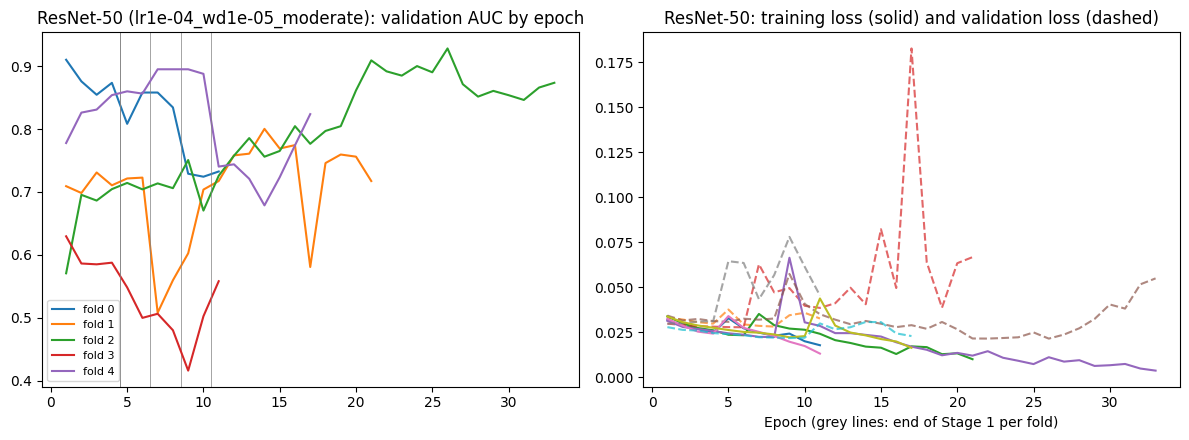

In [ ]:
# CELL 8.2  ResNet-50: learning curves across the five folds of the selected configuration
start_cell("8.2", "ResNet-50 learning curves")

cid = RESNET_SELECTED["config_id"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for fold in range(CONFIG["split"]["n_folds"]):
    hist = pd.read_csv(DIRS["logs"] / "cv" / "resnet50" / cid / f"fold{fold}.csv")
    axes[0].plot(hist["global_epoch"], hist["val_auc"], label=f"fold {fold}")
    axes[1].plot(hist["global_epoch"], hist["train_loss"], label=f"fold {fold} train")
    axes[1].plot(hist["global_epoch"], hist["val_loss"], linestyle="--", alpha=0.7)
    s1_end = int((hist["stage"] == 1).sum())
    axes[0].axvline(s1_end + 0.5, color="grey", linewidth=0.5)
axes[0].set_title(f"ResNet-50 ({cid}): validation AUC by epoch")
axes[1].set_title("ResNet-50: training loss (solid) and validation loss (dashed)")
axes[1].set_xlabel("Epoch (grey lines: end of Stage 1 per fold)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_8_2_resnet50_learning_curves")
plt.show()

In [ ]:
# CELL 8.2  ResNet-50: final retraining on the full 80% partition
start_cell("8.2", "ResNet-50 final retraining")
RESNET_FINAL = retrain_final("resnet50", RESNET_SELECTED)

[8.2] resnet50: retrained on 994 images for 3 + 0 epochs in 0.2 min; pos_weight 0.024; weights sha256 9a8a31a290cebcb4...


## 8.3 Evaluation: ResNet-50

The final ResNet-50 model is scored once on the held-out test set. **Running this cell counts as using the test set.** It writes `outputs/results/TEST_SET_UNLOCKED.txt`; Section 9.3 checks for this file and reuses it rather than unlocking a second time, and the comparative analysis in Section 10 depends on both models having been scored this way, on the same images.

In [ ]:
# CELL 8.3  ResNet-50: held-out test predictions (unlocks the test set)
start_cell("8.3", "ResNet-50 test evaluation")

unlock_flag = DIRS["results"] / "TEST_SET_UNLOCKED.txt"
FORCE_REEVALUATE = False
if unlock_flag.exists() and not FORCE_REEVALUATE:
    log(f"Test set already unlocked ({unlock_flag.read_text().strip()}). Continuing uses the existing unlock; "
        "no new unlock is recorded.")
else:
    unlock_flag.write_text(f"Test set evaluated at {datetime.now().isoformat(timespec='seconds')}\n")
    log("Test set unlocked by this cell (ResNet-50 evaluation).")

test_ids = TEST["image_id"].tolist()
predictions_path = DIRS["results"] / "test_predictions.csv"
predictions = (pd.read_csv(predictions_path) if predictions_path.exists()
              else pd.DataFrame({"image_id": test_ids, "label": [LABEL_OF[i] for i in test_ids]}))

loader = make_loader(test_ids, build_eval_transform("resnet50"), False, SEED)
y_true, prob, idx, _ = predict(RESNET_FINAL, loader)
ordered = pd.DataFrame({"image_id": [test_ids[i] for i in idx], "prob_resnet50": prob})
predictions = predictions.drop(columns=[c for c in ["prob_resnet50", "pred_resnet50"] if c in predictions.columns])
predictions = predictions.merge(ordered, on="image_id")
predictions["pred_resnet50"] = (predictions["prob_resnet50"] >= THRESHOLD).astype(int)
predictions.to_csv(predictions_path, index=False)
log(f"ResNet-50 test predictions saved for {len(predictions)} images")

RESNET_TEST_METRICS = binary_metrics(predictions["label"].to_numpy(), predictions["prob_resnet50"].to_numpy())
m = RESNET_TEST_METRICS
log(f"ResNet-50 test performance: acc {m['accuracy']:.4f} | sens {m['sensitivity']:.4f} | "
    f"spec {m['specificity']:.4f} | AUC {m['auc']:.4f} | prec {m['precision']:.4f} | F1 {m['f1']:.4f} | "
    f"TP {m['tp']} TN {m['tn']} FP {m['fp']} FN {m['fn']}")

[8.3] Test set unlocked by this cell (ResNet-50 evaluation).
[8.3] ResNet-50 test predictions saved for 253 images
[8.3] ResNet-50 test performance: acc 0.8300 | sens 0.8340 | spec 0.6667 | AUC 0.8671 | prec 0.9904 | F1 0.9055 | TP 206 TN 4 FP 2 FN 41


[8.3] Figure saved: outputs/figures/fig_8_3_resnet50_confusion_roc.png


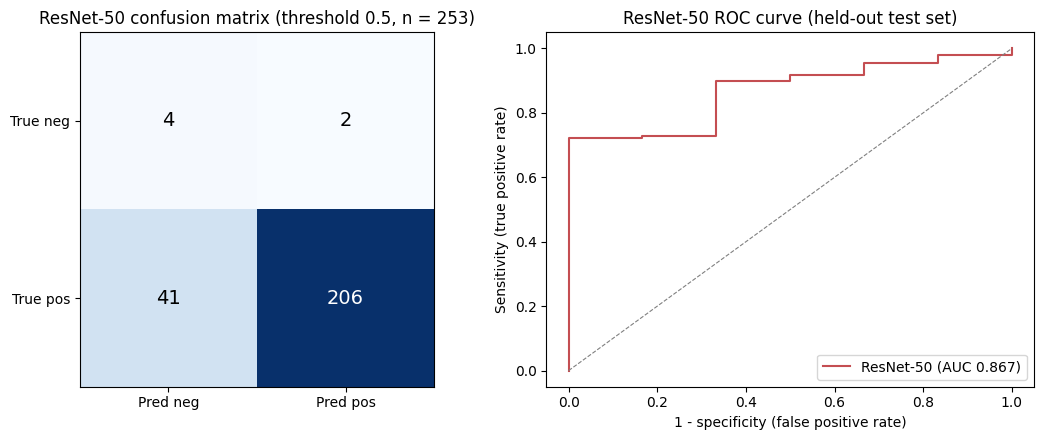

In [ ]:
# CELL 8.3  ResNet-50: confusion matrix and ROC curve (single model)
start_cell("8.3", "ResNet-50 confusion matrix and ROC")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
m = RESNET_TEST_METRICS
matrix = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
axes[0].imshow(matrix, cmap="Blues")
for (r, c), v in np.ndenumerate(matrix):
    axes[0].text(c, r, str(v), ha="center", va="center", fontsize=14,
                color="white" if v > matrix.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["Pred neg", "Pred pos"])
axes[0].set_yticks([0, 1], ["True neg", "True pos"])
axes[0].set_title(f"ResNet-50 confusion matrix (threshold {THRESHOLD}, n = {len(predictions)})")

fpr, tpr, _ = roc_curve(predictions["label"], predictions["prob_resnet50"])
axes[1].plot(fpr, tpr, color="#C44E52", label=f"ResNet-50 (AUC {m['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=0.8)
axes[1].set_xlabel("1 - specificity (false positive rate)")
axes[1].set_ylabel("Sensitivity (true positive rate)")
axes[1].set_title("ResNet-50 ROC curve (held-out test set)")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig_8_3_resnet50_confusion_roc")
plt.show()

### Grad-CAM: how ResNet-50 makes its decisions

Grad-CAM (Selvaraju et al., 2020) is computed on the last convolutional block (`layer4`) for the positive-class logit, giving a coarse localisation map of the image regions that most influenced the prediction. This is exploratory only (SQ5); the combined ResNet-50 versus ViT-Base comparison, on the same images, is in Section 10.4.

[8.3] Figure saved: outputs/figures/fig_8_3_resnet50_gradcam_preview.png


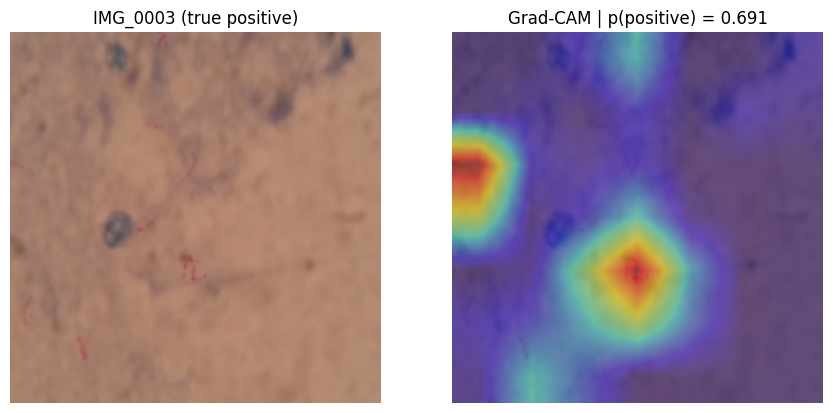

[8.3] grad_cam_resnet defined; preview on IMG_0003. The full comparative panel is built in Section 10.4.


In [ ]:
# CELL 8.3  ResNet-50: Grad-CAM function and a quick preview
# CODE ATTRIBUTION: Grad-CAM follows the method of Selvaraju et al. (2020), implemented with
# PyTorch forward and full backward hooks per the torch.nn.Module documentation,
# https://pytorch.org/docs/stable/generated/torch.nn.Module.html
start_cell("8.3", "ResNet-50 Grad-CAM")


def grad_cam_resnet(model, x):
    store = {}
    layer = model.layer4[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: store.__setitem__("act", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__("grad", go[0]))
    try:
        model.eval()
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logit = model(x).squeeze()
            logit.backward()
    finally:
        h1.remove()
        h2.remove()
    act, grad = store["act"][0].detach(), store["grad"][0].detach()
    weights = grad.mean(dim=(1, 2), keepdim=True)
    cam = F.relu((weights * act).sum(dim=0))
    cam = F.interpolate(cam[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), torch.sigmoid(logit).item()


example = predictions.loc[predictions["label"] == 1, "image_id"].iloc[0]
x_example = build_eval_transform("resnet50")(IMAGE_CACHE[example]).unsqueeze(0).to(DEVICE)
cam, p_res = grad_cam_resnet(RESNET_FINAL, x_example)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(IMAGE_CACHE[example])
axes[0].set_title(f"{example} (true positive)")
axes[1].imshow(IMAGE_CACHE[example])
axes[1].imshow(cam, cmap="jet", alpha=0.45)
axes[1].set_title(f"Grad-CAM | p(positive) = {p_res:.3f}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig_8_3_resnet50_gradcam_preview")
plt.show()
log(f"grad_cam_resnet defined; preview on {example}. The full comparative panel is built in Section 10.4.")

# 9. Model 2: ViT-Base

Every function used below was defined once, in Cell 8.0, and is applied here with `model_name="vit_base"` exactly as it was applied to ResNet-50 in Section 8. This section deliberately mirrors Section 8's structure so the two models can be read, and were built, symmetrically (proposal Section 3.8).

## 9.1 Architecture: ViT-Base

**ViT-Base/16** (Dosovitskiy et al., 2021) splits each 224 x 224 image into a grid of 16 x 16 patches, projects each patch to a token embedding, and processes the resulting sequence with a standard Transformer encoder, in the same way a language model processes a sequence of word tokens. A learned classification token attends to all patch tokens across 12 self-attention layers, and its final representation is passed to a linear classification head.

It is initialised here from `vit_base_patch16_224.augreg_in1k` (via `timm`), an ImageNet-1k-only pretrained checkpoint (D6). This is a deliberate methodological choice: the ViT-Base checkpoints most commonly used in practice are pretrained on the larger ImageNet-21k and only fine-tuned on ImageNet-1k, which would confound any architecture comparison with a pretraining-data advantage. Using an ImageNet-1k-only checkpoint keeps the pretraining data identical to ResNet-50's, at the cost of using a somewhat less common ViT-Base variant; this trade-off is discussed in the report's Discussion and Limitations.

The same staged-freezing procedure as ResNet-50 applies: Stage 1 trains only the classification head, Stage 2 unfreezes the whole network (D1).

In [ ]:
# CELL 9.1  ViT-Base: build and inspect the architecture
start_cell("9.1", "ViT-Base architecture")

vit_probe = build_model("vit_base", pretrained=False)
log(f"ViT-Base classifier head: {vit_probe.get_classifier()}")
for stage in (1, 2):
    set_stage(vit_probe, "vit_base", stage)
    total, trainable = count_parameters(vit_probe)
    log(f"vit_base stage {stage}: {total:,} parameters, {trainable:,} trainable "
        f"({trainable / total:.4%} of the network)")
log(f"ViT-Base pretrained tag: {CONFIG['models']['vit_base']['tag']} (ImageNet-1k only, D6)")
log(f"Patch size 16 x 16 on a {IMG_SIZE} x {IMG_SIZE} image gives {(IMG_SIZE // 16) ** 2} patch tokens "
    f"plus {vit_probe.num_prefix_tokens} prefix token(s) (class token), used for the attention map in Section 9.3")
del vit_probe

[9.1] ViT-Base classifier head: Linear(in_features=768, out_features=1, bias=True)
[9.1] vit_base stage 1: 85,799,425 parameters, 769 trainable (0.0009% of the network)
[9.1] vit_base stage 2: 85,799,425 parameters, 85,799,425 trainable (100.0000% of the network)
[9.1] ViT-Base pretrained tag: vit_base_patch16_224.augreg_in1k (ImageNet-1k only, D6)
[9.1] Patch size 16 x 16 on a 224 x 224 image gives 196 patch tokens plus 1 prefix token(s) (class token), used for the attention map in Section 9.3


## 9.2 Training: ViT-Base

Identical procedure to Section 8.2, with the same shared functions, the same fold assignments, and the same grid (D4). Any difference between the two models' results comes from architecture, not from a difference in how they were trained.

In [ ]:
# CELL 9.2  ViT-Base: run the grid search (resumable)
start_cell("9.2", "ViT-Base grid search")
run_grid_search("vit_base")

[9.2] vit_base: 0 of 60 runs already complete
[9.2] vit_base lr1e-04_wd1e-04_low fold 0: val AUC 0.9645, sens 0.947, spec 0.600 | epochs S1 10 S2 36 | 5.8 min
[9.2] vit_base lr1e-04_wd1e-04_low fold 1: val AUC 0.8179, sens 0.913, spec 0.500 | epochs S1 10 S2 7 | 1.8 min
[9.2] vit_base lr1e-04_wd1e-04_low fold 2: val AUC 0.9409, sens 0.768, spec 1.000 | epochs S1 8 S2 10 | 2.0 min
[9.2] vit_base lr1e-04_wd1e-04_low fold 3: val AUC 0.5929, sens 0.372, spec 1.000 | epochs S1 4 S2 7 | 1.3 min
[9.2] vit_base lr1e-04_wd1e-04_low fold 4: val AUC 0.8998, sens 0.570, spec 1.000 | epochs S1 5 S2 7 | 1.4 min
[9.2] vit_base lr1e-04_wd1e-04_moderate fold 0: val AUC 0.9479, sens 1.000, spec 0.000 | epochs S1 10 S2 8 | 2.0 min
[9.2] vit_base lr1e-04_wd1e-04_moderate fold 1: val AUC 0.8560, sens 0.891, spec 0.500 | epochs S1 10 S2 7 | 1.8 min
[9.2] vit_base lr1e-04_wd1e-04_moderate fold 2: val AUC 0.9576, sens 1.000, spec 0.000 | epochs S1 8 S2 18 | 3.1 min
[9.2] vit_base lr1e-04_wd1e-04_moderate fold

In [ ]:
# CELL 9.2  ViT-Base: cross-validation summary and configuration selection
start_cell("9.2", "ViT-Base CV summary and selection")
VIT_CV_RUNS, VIT_CV_SUMMARY, VIT_SELECTED = summarize_and_select("vit_base")
with (DIRS["results"] / "vit_base_selected_config.json").open("w", encoding="utf-8") as handle:
    json.dump(VIT_SELECTED, handle, indent=2)

[9.2] vit_base: total GPU time for the grid: 2.30 hours on ['Tesla T4']
[9.2] vit_base: all configurations ranked by mean validation AUC (mean +/- SD across folds; descriptive only, D8):
[9.2]   lr5e-05_wd1e-04_moderate: AUC 0.9195 +/- 0.0931 | sens 0.927 +/- 0.044 | spec 0.587 +/- 0.306
[9.2]   lr5e-05_wd1e-04_low: AUC 0.9169 +/- 0.0688 | sens 0.716 +/- 0.265 | spec 0.800 +/- 0.447
[9.2]   lr5e-05_wd1e-05_low: AUC 0.9081 +/- 0.0732 | sens 0.901 +/- 0.076 | spec 0.767 +/- 0.308
[9.2]   lr5e-05_wd1e-05_moderate: AUC 0.9019 +/- 0.1043 | sens 0.865 +/- 0.107 | spec 0.667 +/- 0.295
[9.2]   lr1e-04_wd1e-04_moderate: AUC 0.8868 +/- 0.0965 | sens 0.847 +/- 0.205 | spec 0.450 +/- 0.447
[9.2]   lr1e-04_wd1e-05_moderate: AUC 0.8789 +/- 0.1064 | sens 0.801 +/- 0.169 | spec 0.767 +/- 0.253
[9.2]   lr1e-05_wd1e-04_moderate: AUC 0.8715 +/- 0.1441 | sens 0.777 +/- 0.310 | spec 0.837 +/- 0.171
[9.2]   lr1e-05_wd1e-05_moderate: AUC 0.8713 +/- 0.1442 | sens 0.783 +/- 0.313 | spec 0.837 +/- 0.171
[9.2]  

[9.2] Figure saved: outputs/figures/fig_9_2_vit_base_learning_curves.png


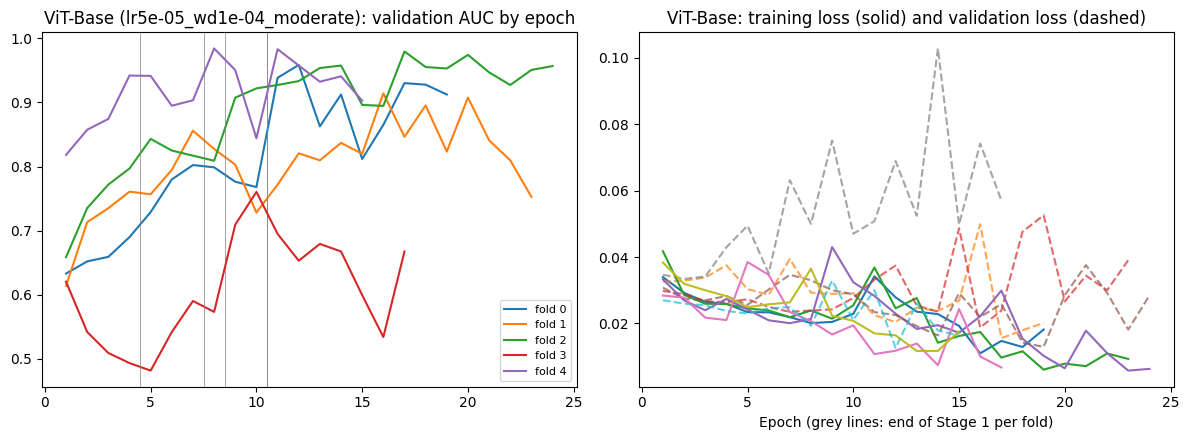

In [ ]:
# CELL 9.2  ViT-Base: learning curves across the five folds of the selected configuration
start_cell("9.2", "ViT-Base learning curves")

cid = VIT_SELECTED["config_id"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for fold in range(CONFIG["split"]["n_folds"]):
    hist = pd.read_csv(DIRS["logs"] / "cv" / "vit_base" / cid / f"fold{fold}.csv")
    axes[0].plot(hist["global_epoch"], hist["val_auc"], label=f"fold {fold}")
    axes[1].plot(hist["global_epoch"], hist["train_loss"], label=f"fold {fold} train")
    axes[1].plot(hist["global_epoch"], hist["val_loss"], linestyle="--", alpha=0.7)
    s1_end = int((hist["stage"] == 1).sum())
    axes[0].axvline(s1_end + 0.5, color="grey", linewidth=0.5)
axes[0].set_title(f"ViT-Base ({cid}): validation AUC by epoch")
axes[1].set_title("ViT-Base: training loss (solid) and validation loss (dashed)")
axes[1].set_xlabel("Epoch (grey lines: end of Stage 1 per fold)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_9_2_vit_base_learning_curves")
plt.show()

In [ ]:
# CELL 9.2  ViT-Base: final retraining on the full 80% partition
start_cell("9.2", "ViT-Base final retraining")
VIT_FINAL = retrain_final("vit_base", VIT_SELECTED)

[9.2] vit_base: retrained on 994 images for 5 + 6 epochs in 1.3 min; pos_weight 0.024; weights sha256 3c6606a219e2ef35...


## 9.3 Evaluation: ViT-Base

Scored once on the same held-out test images as ResNet-50 (Section 8.3), which is what makes every comparison in Section 10 a *paired* comparison on identical data.

In [ ]:
# CELL 9.3  ViT-Base: held-out test predictions (reuses the existing unlock)
start_cell("9.3", "ViT-Base test evaluation")

unlock_flag = DIRS["results"] / "TEST_SET_UNLOCKED.txt"
if not unlock_flag.exists():
    unlock_flag.write_text(f"Test set evaluated at {datetime.now().isoformat(timespec='seconds')}\n")
    log("Test set unlocked by this cell (ViT-Base evaluation).")
else:
    log(f"Test set already unlocked ({unlock_flag.read_text().strip()}); reusing the existing unlock.")

test_ids = TEST["image_id"].tolist()
predictions_path = DIRS["results"] / "test_predictions.csv"
predictions = (pd.read_csv(predictions_path) if predictions_path.exists()
              else pd.DataFrame({"image_id": test_ids, "label": [LABEL_OF[i] for i in test_ids]}))

loader = make_loader(test_ids, build_eval_transform("vit_base"), False, SEED)
y_true, prob, idx, _ = predict(VIT_FINAL, loader)
ordered = pd.DataFrame({"image_id": [test_ids[i] for i in idx], "prob_vit_base": prob})
predictions = predictions.drop(columns=[c for c in ["prob_vit_base", "pred_vit_base"] if c in predictions.columns])
predictions = predictions.merge(ordered, on="image_id")
predictions["pred_vit_base"] = (predictions["prob_vit_base"] >= THRESHOLD).astype(int)
predictions.to_csv(predictions_path, index=False)
log(f"ViT-Base test predictions saved for {len(predictions)} images")

VIT_TEST_METRICS = binary_metrics(predictions["label"].to_numpy(), predictions["prob_vit_base"].to_numpy())
m = VIT_TEST_METRICS
log(f"ViT-Base test performance: acc {m['accuracy']:.4f} | sens {m['sensitivity']:.4f} | "
    f"spec {m['specificity']:.4f} | AUC {m['auc']:.4f} | prec {m['precision']:.4f} | F1 {m['f1']:.4f} | "
    f"TP {m['tp']} TN {m['tn']} FP {m['fp']} FN {m['fn']}")

[9.3] Test set already unlocked (Test set evaluated at 2026-10-04T21:54:46); reusing the existing unlock.
[9.3] ViT-Base test predictions saved for 253 images
[9.3] ViT-Base test performance: acc 0.8617 | sens 0.8623 | spec 0.8333 | AUC 0.9541 | prec 0.9953 | F1 0.9241 | TP 213 TN 5 FP 1 FN 34


[9.3] Figure saved: outputs/figures/fig_9_3_vit_base_confusion_roc.png


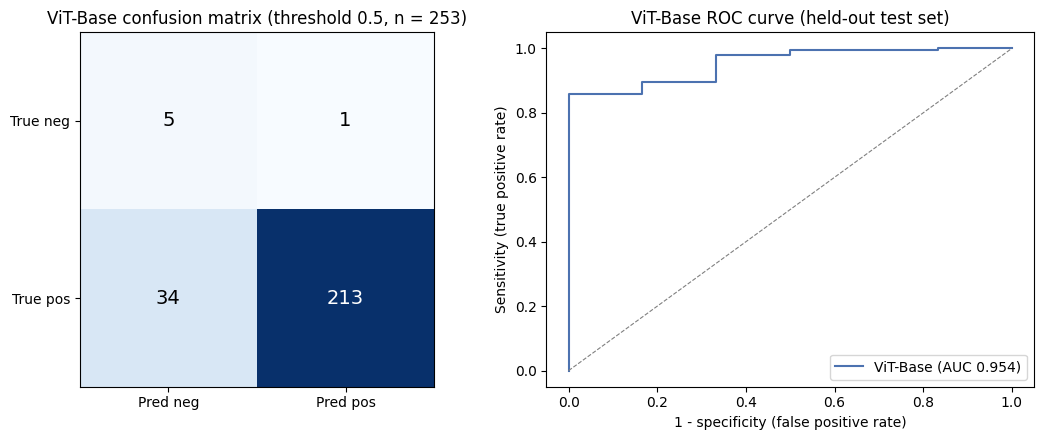

In [ ]:
# CELL 9.3  ViT-Base: confusion matrix and ROC curve (single model)
start_cell("9.3", "ViT-Base confusion matrix and ROC")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
m = VIT_TEST_METRICS
matrix = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
axes[0].imshow(matrix, cmap="Blues")
for (r, c), v in np.ndenumerate(matrix):
    axes[0].text(c, r, str(v), ha="center", va="center", fontsize=14,
                color="white" if v > matrix.max() / 2 else "black")
axes[0].set_xticks([0, 1], ["Pred neg", "Pred pos"])
axes[0].set_yticks([0, 1], ["True neg", "True pos"])
axes[0].set_title(f"ViT-Base confusion matrix (threshold {THRESHOLD}, n = {len(predictions)})")

fpr, tpr, _ = roc_curve(predictions["label"], predictions["prob_vit_base"])
axes[1].plot(fpr, tpr, color="#4C72B0", label=f"ViT-Base (AUC {m['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=0.8)
axes[1].set_xlabel("1 - specificity (false positive rate)")
axes[1].set_ylabel("Sensitivity (true positive rate)")
axes[1].set_title("ViT-Base ROC curve (held-out test set)")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig_9_3_vit_base_confusion_roc")
plt.show()

### Last-layer attention: how ViT-Base makes its decisions

Following proposal Section 3.7, the attention weights of the final self-attention layer are averaged over heads and taken from the class token to the 196 patch tokens, then upsampled to 224 x 224. Like Grad-CAM, this is exploratory only; the combined comparison is in Section 10.4.

[9.3] Figure saved: outputs/figures/fig_9_3_vit_base_attention_preview.png


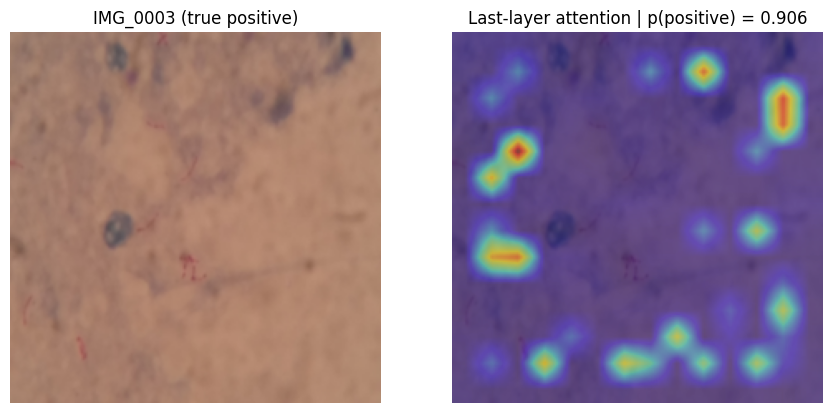

[9.3] vit_last_layer_attention defined; preview on IMG_0003. The full comparative panel is built in Section 10.4.


In [ ]:
# CELL 9.3  ViT-Base: last-layer attention function and a quick preview
# CODE ATTRIBUTION: the attention hook recomputes softmax(q k^T * scale) from the inputs of the
# final timm Attention module, mirroring the non-fused branch of timm.layers.Attention.forward
# (timm source, https://github.com/huggingface/pytorch-image-models).
start_cell("9.3", "ViT-Base attention map")


@torch.no_grad()
def vit_last_layer_attention(model, x):
    store = {}
    attn_module = model.blocks[-1].attn

    def hook(module, inputs, output):
        tokens = inputs[0]
        b, n, _ = tokens.shape
        qkv = module.qkv(tokens).reshape(b, n, 3, module.num_heads, module.head_dim).permute(2, 0, 3, 1, 4)
        q, k, _ = qkv.unbind(0)
        q, k = module.q_norm(q), module.k_norm(k)
        store["attn"] = ((q * module.scale) @ k.transpose(-2, -1)).softmax(dim=-1)

    handle = attn_module.register_forward_hook(hook)
    try:
        model.eval()
        logit = model(x).squeeze()
    finally:
        handle.remove()
    attn = store["attn"][0].mean(dim=0)  # average over heads -> tokens x tokens
    cls_to_patches = attn[0, model.num_prefix_tokens:]
    side = int(math.sqrt(cls_to_patches.numel()))
    amap = cls_to_patches.reshape(1, 1, side, side).float()
    amap = F.interpolate(amap, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    amap = (amap - amap.min()) / (amap.max() - amap.min() + 1e-8)
    return amap.cpu().numpy(), torch.sigmoid(logit).item()


example = predictions.loc[predictions["label"] == 1, "image_id"].iloc[0]
x_example = build_eval_transform("vit_base")(IMAGE_CACHE[example]).unsqueeze(0).to(DEVICE)
amap, p_vit = vit_last_layer_attention(VIT_FINAL, x_example)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(IMAGE_CACHE[example])
axes[0].set_title(f"{example} (true positive)")
axes[1].imshow(IMAGE_CACHE[example])
axes[1].imshow(amap, cmap="jet", alpha=0.45)
axes[1].set_title(f"Last-layer attention | p(positive) = {p_vit:.3f}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig_9_3_vit_base_attention_preview")
plt.show()
log(f"vit_last_layer_attention defined; preview on {example}. The full comparative panel is built in Section 10.4.")

# 10. Comparative Analysis

Sections 8 and 9 evaluated each model on its own. This section compares them directly on the same held-out test images, since both were scored on identical data (Sections 8.3 and 9.3).

[10.1] Figure saved: outputs/figures/fig_10_1_combined_roc_curves.png


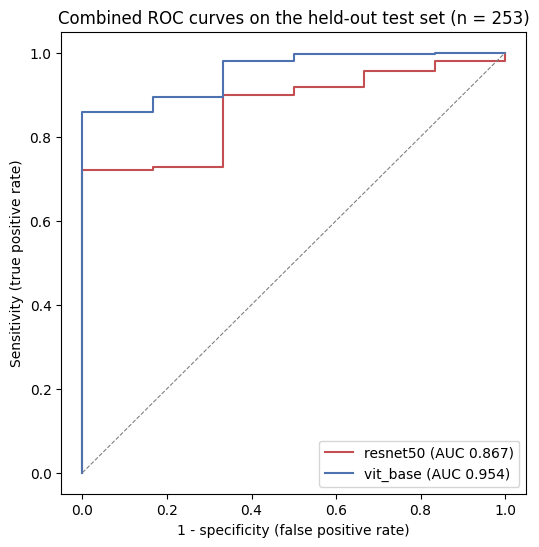

[10.1] Side-by-side test performance:
[10.1]        metric  resnet50  vit_base  difference_resnet_minus_vit
[10.1]      accuracy    0.8300    0.8617                      -0.0316
[10.1]   sensitivity    0.8340    0.8623                      -0.0283
[10.1]   specificity    0.6667    0.8333                      -0.1667
[10.1]           auc    0.8671    0.9541                      -0.0870
[10.1]     precision    0.9904    0.9953                      -0.0049
[10.1]            f1    0.9055    0.9241                      -0.0186


In [ ]:
# CELL 10.1  Combined test performance (both models, same images)
start_cell("10.1", "Combined test performance")

predictions = pd.read_csv(DIRS["results"] / "test_predictions.csv")
Y_TEST = predictions["label"].to_numpy()
P_RES, P_VIT = predictions["prob_resnet50"].to_numpy(), predictions["prob_vit_base"].to_numpy()
TEST_METRICS = {"resnet50": RESNET_TEST_METRICS, "vit_base": VIT_TEST_METRICS}

fig, ax = plt.subplots(figsize=(6, 6))
for name, prob, colour in [("resnet50", P_RES, "#C44E52"), ("vit_base", P_VIT, "#4C72B0")]:
    fpr, tpr, _ = roc_curve(Y_TEST, prob)
    ax.plot(fpr, tpr, color=colour, label=f"{name} (AUC {TEST_METRICS[name]['auc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=0.8)
ax.set_xlabel("1 - specificity (false positive rate)")
ax.set_ylabel("Sensitivity (true positive rate)")
ax.set_title(f"Combined ROC curves on the held-out test set (n = {len(Y_TEST)})")
ax.legend(loc="lower right")
save_fig(fig, "fig_10_1_combined_roc_curves")
plt.show()

comparison = pd.DataFrame({"metric": ["accuracy", "sensitivity", "specificity", "auc", "precision", "f1"],
                           "resnet50": [RESNET_TEST_METRICS[k] for k in ["accuracy", "sensitivity", "specificity", "auc", "precision", "f1"]],
                           "vit_base": [VIT_TEST_METRICS[k] for k in ["accuracy", "sensitivity", "specificity", "auc", "precision", "f1"]]})
comparison["difference_resnet_minus_vit"] = comparison["resnet50"] - comparison["vit_base"]
log("Side-by-side test performance:")
for line in comparison.round(4).to_string(index=False).splitlines():
    log("  " + line)

## 10.2 Statistical hypothesis tests

| Hypothesis | Test | Images used |
|---|---|---|
| H1 accuracy | McNemar's test on correct/incorrect per image (Dietterich, 1998) | All test images |
| H2 sensitivity | McNemar's test | Positive-label test images only (D7) |
| H3 specificity | McNemar's test | Negative-label test images only (D7) |
| H4 AUC-ROC | DeLong's method for paired AUCs (DeLong, DeLong and Clarke-Pearson, 1988) | All test images |

McNemar's test uses only the discordant images: b = ResNet-50 correct and ViT-Base wrong; c = the reverse. Where b + c is below 25, the exact binomial form is used; otherwise the chi-square form with continuity correction. Each null hypothesis is rejected only if p < 0.0125 (Bonferroni, four tests).

In [ ]:
# CELL 10.2  Statistical test functions
# CODE ATTRIBUTION:
#   Wilson score interval: formula from Wilson (1927), implemented for this study.
#   McNemar's test: exact binomial and continuity-corrected chi-square forms as described by
#     Dietterich (1998); scipy.stats.binomtest and scipy.stats.chi2 per the SciPy documentation,
#     https://docs.scipy.org/doc/scipy/reference/stats.html
#   DeLong's test: variance estimator of DeLong, DeLong and Clarke-Pearson (1988), computed with the
#     midrank formulation of Sun and Xu (2014); implemented for this study and checked against a
#     direct pairwise implementation.
start_cell("10.2", "Statistical test functions")


def wilson_ci(successes: int, n: int, level: float = 0.95):
    if n == 0:
        return float("nan"), float("nan")
    z = stats.norm.ppf(1 - (1 - level) / 2)
    p = successes / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return max(0.0, centre - half), min(1.0, centre + half)


def mcnemar_test(correct_a, correct_b, exact_below: int = 25) -> dict:
    correct_a, correct_b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    if b + c == 0:
        return {"b": b, "c": c, "method": "no discordant pairs", "statistic": float("nan"), "p_value": 1.0,
                "odds_ratio_b_over_c": float("nan")}
    if b + c < exact_below:
        method, statistic = "exact binomial", float(min(b, c))
        p_value = stats.binomtest(b, b + c, 0.5, alternative="two-sided").pvalue
    else:
        method = "chi-square with continuity correction"
        statistic = (abs(b - c) - 1) ** 2 / (b + c)
        p_value = stats.chi2.sf(statistic, df=1)
    return {"b": b, "c": c, "method": method, "statistic": float(statistic), "p_value": float(p_value),
            "odds_ratio_b_over_c": b / c if c > 0 else float("inf")}


def _midrank(x):
    order = np.argsort(x, kind="mergesort")
    sorted_x = x[order]
    n = len(x)
    ranks = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and sorted_x[j] == sorted_x[i]:
            j += 1
        ranks[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = ranks
    return out


def delong_test(y_true, prob_a, prob_b) -> dict:
    """Paired DeLong test for two correlated AUCs on the same cases."""
    y_true = np.asarray(y_true).astype(int)
    pos, neg = y_true == 1, y_true == 0
    m, n = int(pos.sum()), int(neg.sum())
    aucs, v10, v01 = [], [], []
    for prob in (np.asarray(prob_a, float), np.asarray(prob_b, float)):
        x, y = prob[pos], prob[neg]
        tx, ty, tz = _midrank(x), _midrank(y), _midrank(np.concatenate([x, y]))
        aucs.append(tz[:m].sum() / (m * n) - (m + 1) / (2 * n))
        v10.append((tz[:m] - tx) / n)
        v01.append(1 - (tz[m:] - ty) / m)
    s10, s01 = np.cov(np.vstack(v10)), np.cov(np.vstack(v01))
    cov = s10 / m + s01 / n
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        z, p_value = float("nan"), 1.0
    else:
        z = diff / math.sqrt(var)
        p_value = 2 * stats.norm.sf(abs(z))
    half = stats.norm.ppf(0.975) * math.sqrt(max(var, 0))
    return {"auc_a": float(aucs[0]), "auc_b": float(aucs[1]), "difference": float(diff), "z": float(z),
            "p_value": float(p_value), "diff_ci_low": float(diff - half), "diff_ci_high": float(diff + half)}


def paired_bootstrap(y_true, prob_a, prob_b, reps: int, seed: int) -> pd.DataFrame:
    """Stratified bootstrap: positives and negatives are resampled separately, so each replicate keeps
    the test set's class counts. Returns one row per replicate with metrics for both models."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true).astype(int)
    pos_idx, neg_idx = np.where(y_true == 1)[0], np.where(y_true == 0)[0]
    rows = []
    for _ in range(reps):
        idx = np.concatenate([rng.choice(pos_idx, len(pos_idx), replace=True),
                              rng.choice(neg_idx, len(neg_idx), replace=True)])
        ma = binary_metrics(y_true[idx], prob_a[idx])
        mb = binary_metrics(y_true[idx], prob_b[idx])
        rows.append({**{f"a_{k}": ma[k] for k in METRICS}, **{f"b_{k}": mb[k] for k in METRICS}})
    return pd.DataFrame(rows)


METRICS = ["accuracy", "sensitivity", "specificity", "auc", "precision", "f1"]
log("Defined: wilson_ci, mcnemar_test, delong_test, paired_bootstrap")

[10.2] Defined: wilson_ci, mcnemar_test, delong_test, paired_bootstrap


In [ ]:
# CELL 10.2  Run the hypothesis tests
start_cell("10.2", "Hypothesis tests")

stat_cfg = CONFIG["statistics"]
ALPHA_ADJ = stat_cfg["alpha_adjusted"]
correct_res = predictions["pred_resnet50"].to_numpy() == Y_TEST
correct_vit = predictions["pred_vit_base"].to_numpy() == Y_TEST
pos_mask, neg_mask = Y_TEST == 1, Y_TEST == 0

boot = paired_bootstrap(Y_TEST, P_RES, P_VIT, stat_cfg["bootstrap_reps"], SEED)

tests = {
    "H1 accuracy": mcnemar_test(correct_res, correct_vit, stat_cfg["mcnemar_exact_below"]),
    "H2 sensitivity": mcnemar_test(correct_res[pos_mask], correct_vit[pos_mask], stat_cfg["mcnemar_exact_below"]),
    "H3 specificity": mcnemar_test(correct_res[neg_mask], correct_vit[neg_mask], stat_cfg["mcnemar_exact_below"]),
}
delong = delong_test(Y_TEST, P_RES, P_VIT)

lo_q, hi_q = 100 * (1 - stat_cfg["ci_level"]) / 2, 100 * (1 + stat_cfg["ci_level"]) / 2
diff_rows = []
for metric in METRICS:
    diffs = boot[f"a_{metric}"] - boot[f"b_{metric}"]
    low, high = np.nanpercentile(diffs, [lo_q, hi_q])
    diff_rows.append({"metric": metric,
                      "difference_resnet_minus_vit": RESNET_TEST_METRICS[metric] - VIT_TEST_METRICS[metric],
                      "ci_low": low, "ci_high": high})
diff_table = pd.DataFrame(diff_rows)

hyp_rows = []
for label, metric, subset_n in [("H1 accuracy", "accuracy", len(Y_TEST)),
                                ("H2 sensitivity", "sensitivity", int(pos_mask.sum())),
                                ("H3 specificity", "specificity", int(neg_mask.sum()))]:
    t = tests[label]
    d = diff_table.set_index("metric").loc[metric]
    hyp_rows.append({"hypothesis": label, "images_used": subset_n,
                     "resnet50": RESNET_TEST_METRICS[metric], "vit_base": VIT_TEST_METRICS[metric],
                     "difference": d["difference_resnet_minus_vit"], "diff_ci_low": d["ci_low"],
                     "diff_ci_high": d["ci_high"], "test": f"McNemar ({t['method']})",
                     "statistic": t["statistic"], "p_value": t["p_value"],
                     "discordant_b_resnet_only_correct": t["b"], "discordant_c_vit_only_correct": t["c"],
                     "alpha_adjusted": ALPHA_ADJ,
                     "decision": "reject H0" if t["p_value"] < ALPHA_ADJ else "fail to reject H0"})
hyp_rows.append({"hypothesis": "H4 AUC-ROC", "images_used": len(Y_TEST),
                 "resnet50": delong["auc_a"], "vit_base": delong["auc_b"], "difference": delong["difference"],
                 "diff_ci_low": delong["diff_ci_low"], "diff_ci_high": delong["diff_ci_high"],
                 "test": "DeLong (z)", "statistic": delong["z"], "p_value": delong["p_value"],
                 "discordant_b_resnet_only_correct": np.nan, "discordant_c_vit_only_correct": np.nan,
                 "alpha_adjusted": ALPHA_ADJ,
                 "decision": "reject H0" if delong["p_value"] < ALPHA_ADJ else "fail to reject H0"})
hypothesis_table = pd.DataFrame(hyp_rows)
hypothesis_table.to_csv(DIRS["results"] / "hypothesis_tests.csv", index=False)
diff_table.to_csv(DIRS["results"] / "test_metric_differences.csv", index=False)
for _, r in hypothesis_table.iterrows():
    log(f"{r['hypothesis']}: ResNet-50 {r['resnet50']:.4f} vs ViT-Base {r['vit_base']:.4f} | difference "
        f"{r['difference']:+.4f} (95% CI {r['diff_ci_low']:+.4f} to {r['diff_ci_high']:+.4f}) | {r['test']} "
        f"statistic {r['statistic']:.4f}, p = {r['p_value']:.4f} | alpha {ALPHA_ADJ} -> {r['decision']}")
log("DeLong CI for the AUC difference is the normal-approximation interval from the DeLong variance.")
log("Reporting rule: 'fail to reject H0' is not evidence that the models are equivalent.")

[10.2] H1 accuracy: ResNet-50 0.8300 vs ViT-Base 0.8617 | difference -0.0316 (95% CI -0.0830 to +0.0198) | McNemar (chi-square with continuity correction) statistic 1.1136, p = 0.2913 | alpha 0.0125 -> fail to reject H0
[10.2] H2 sensitivity: ResNet-50 0.8340 vs ViT-Base 0.8623 | difference -0.0283 (95% CI -0.0810 to +0.0243) | McNemar (chi-square with continuity correction) statistic 0.8372, p = 0.3602 | alpha 0.0125 -> fail to reject H0
[10.2] H3 specificity: ResNet-50 0.6667 vs ViT-Base 0.8333 | difference -0.1667 (95% CI -0.5000 to +0.0000) | McNemar (exact binomial) statistic 0.0000, p = 1.0000 | alpha 0.0125 -> fail to reject H0
[10.2] H4 AUC-ROC: ResNet-50 0.8671 vs ViT-Base 0.9541 | difference -0.0870 (95% CI -0.1834 to +0.0093) | DeLong (z) statistic -1.7704, p = 0.0767 | alpha 0.0125 -> fail to reject H0
[10.2] DeLong CI for the AUC difference is the normal-approximation interval from the DeLong variance.
[10.2] Reporting rule: 'fail to reject H0' is not evidence that the mod

## 10.3 Uncertainty and effect sizes

Each model's own test-set metrics with 95% intervals: Wilson intervals for the four proportion-based metrics (accuracy, sensitivity, specificity, precision), and stratified bootstrap intervals for AUC and F1, since these are not simple proportions. Precision and F1 are descriptive only and are not hypothesis-tested (proposal Section 3.6).

In [ ]:
# CELL 10.3  Per-model metrics with 95% intervals
start_cell("10.3", "Uncertainty (95% intervals)")

proportion_parts = {
    "accuracy": lambda m: (m["tp"] + m["tn"], m["tp"] + m["tn"] + m["fp"] + m["fn"]),
    "sensitivity": lambda m: (m["tp"], m["tp"] + m["fn"]),
    "specificity": lambda m: (m["tn"], m["tn"] + m["fp"]),
    "precision": lambda m: (m["tp"], m["tp"] + m["fp"]),
}
metric_rows = []
for prefix, name, model_metrics in [("a", "resnet50", RESNET_TEST_METRICS), ("b", "vit_base", VIT_TEST_METRICS)]:
    for metric in METRICS:
        if metric in proportion_parts:
            k, n = proportion_parts[metric](model_metrics)
            low, high = wilson_ci(k, n, stat_cfg["ci_level"])
            method = f"Wilson ({k}/{n})"
        else:
            low, high = np.nanpercentile(boot[f"{prefix}_{metric}"], [lo_q, hi_q])
            method = f"stratified bootstrap ({stat_cfg['bootstrap_reps']} reps)"
        metric_rows.append({"model": name, "metric": metric, "value": model_metrics[metric],
                            "ci_low": low, "ci_high": high, "interval_method": method})
metrics_table = pd.DataFrame(metric_rows)
metrics_table.to_csv(DIRS["results"] / "test_metrics_with_ci.csv", index=False)
for _, r in metrics_table.iterrows():
    log(f"{r['model']} {r['metric']}: {r['value']:.4f} (95% CI {r['ci_low']:.4f} to {r['ci_high']:.4f}; "
        f"{r['interval_method']})")

[10.3] resnet50 accuracy: 0.8300 (95% CI 0.7789 to 0.8713; Wilson (210/253))
[10.3] resnet50 sensitivity: 0.8340 (95% CI 0.7826 to 0.8752; Wilson (206/247))
[10.3] resnet50 specificity: 0.6667 (95% CI 0.3000 to 0.9032; Wilson (4/6))
[10.3] resnet50 auc: 0.8671 (95% CI 0.7753 to 0.9501; stratified bootstrap (2000 reps))
[10.3] resnet50 precision: 0.9904 (95% CI 0.9656 to 0.9974; Wilson (206/208))
[10.3] resnet50 f1: 0.9055 (95% CI 0.8764 to 0.9313; stratified bootstrap (2000 reps))
[10.3] vit_base accuracy: 0.8617 (95% CI 0.8137 to 0.8988; Wilson (218/253))
[10.3] vit_base sensitivity: 0.8623 (95% CI 0.8138 to 0.8998; Wilson (213/247))
[10.3] vit_base specificity: 0.8333 (95% CI 0.4365 to 0.9699; Wilson (5/6))
[10.3] vit_base auc: 0.9541 (95% CI 0.8988 to 0.9960; stratified bootstrap (2000 reps))
[10.3] vit_base precision: 0.9953 (95% CI 0.9740 to 0.9992; Wilson (213/214))
[10.3] vit_base f1: 0.9241 (95% CI 0.8978 to 0.9489; stratified bootstrap (2000 reps))


## 10.4 Exploratory interpretability (SQ5)

**Image subset (D2, P4):** test images are grouped by true class and by whether each model was correct (both correct, ResNet-50 only, ViT-Base only, both wrong). Up to 3 images are drawn from each of the eight cells with a fixed seed, and both explanation methods are shown on the **same** images, so they can be compared directly.

**Interpretation limits:** this is a qualitative, illustrative analysis with no clinician or laboratory validation and no quantitative measure of explanation quality. Gradient-based maps and attention weights measure different things, so side-by-side panels support description, not a claim that one model "looks at" bacilli more correctly than the other.

In [ ]:
# CELL 10.4  Select the interpretability subset
start_cell("10.4", "Interpretability subset")

pattern = np.select([correct_res & correct_vit, correct_res & ~correct_vit, ~correct_res & correct_vit],
                    ["both correct", "ResNet-50 only correct", "ViT-Base only correct"], default="both wrong")
predictions["agreement"] = pattern
rng = np.random.default_rng(SEED)
chosen = []
for label_value in (1, 0):
    for group in ["both correct", "ResNet-50 only correct", "ViT-Base only correct", "both wrong"]:
        pool = predictions[(predictions["label"] == label_value) & (predictions["agreement"] == group)]
        take = min(CONFIG["interpretability"]["per_cell"], len(pool))
        log(f"class {label_value} | {group}: {len(pool)} available, {take} selected")
        if take:
            chosen.append(pool.iloc[rng.choice(len(pool), take, replace=False)])
SUBSET = pd.concat(chosen).reset_index(drop=True)
SUBSET.to_csv(DIRS["results"] / "interpretability_subset.csv", index=False)
log(f"Interpretability subset: {len(SUBSET)} images saved to outputs/results/interpretability_subset.csv")

[10.4] class 1 | both correct: 188 available, 3 selected
[10.4] class 1 | ResNet-50 only correct: 18 available, 3 selected
[10.4] class 1 | ViT-Base only correct: 25 available, 3 selected
[10.4] class 1 | both wrong: 16 available, 3 selected
[10.4] class 0 | both correct: 4 available, 3 selected
[10.4] class 0 | ResNet-50 only correct: 0 available, 0 selected
[10.4] class 0 | ViT-Base only correct: 1 available, 1 selected
[10.4] class 0 | both wrong: 1 available, 1 selected
[10.4] Interpretability subset: 17 images saved to outputs/results/interpretability_subset.csv


In [ ]:
# CELL 10.4  Side-by-side explanation panels (Grad-CAM from 8.3, attention from 9.3)
start_cell("10.4", "Explanation panels")

for label_value, label_name in [(1, "positive"), (0, "negative")]:
    rows = SUBSET[SUBSET["label"] == label_value]
    if rows.empty:
        log(f"No {label_name} images in the subset")
        continue
    fig, axes = plt.subplots(len(rows), 3, figsize=(10, 3.4 * len(rows)), squeeze=False)
    for r, (_, item) in enumerate(rows.iterrows()):
        image = IMAGE_CACHE[item["image_id"]]
        x_res = build_eval_transform("resnet50")(image).unsqueeze(0).to(DEVICE)
        x_vit = build_eval_transform("vit_base")(image).unsqueeze(0).to(DEVICE)
        cam, p_res = grad_cam_resnet(RESNET_FINAL, x_res)
        amap, p_vit = vit_last_layer_attention(VIT_FINAL, x_vit)
        axes[r, 0].imshow(image)
        axes[r, 0].set_title(f"{item['image_id']} | true {label_name}\n{item['agreement']}", fontsize=9)
        axes[r, 1].imshow(image)
        axes[r, 1].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, 1].set_title(f"ResNet-50 Grad-CAM | p(pos) = {p_res:.3f}", fontsize=9)
        axes[r, 2].imshow(image)
        axes[r, 2].imshow(amap, cmap="jet", alpha=0.45)
        axes[r, 2].set_title(f"ViT-Base last-layer attention | p(pos) = {p_vit:.3f}", fontsize=9)
        for ax in axes[r]:
            ax.axis("off")
    fig.suptitle(f"Exploratory explanation maps, {label_name} test images (not clinically validated)")
    fig.tight_layout()
    save_fig(fig, f"fig_10_4_explanations_{label_name}")
    plt.show()
log("Describe the panels in Findings factually; interpret them only in the Discussion.")

Output hidden; open in https://colab.research.google.com to view.

## 10.5 Report-ready tables and environment record

In [ ]:
# CELL 10.5  Export tables, freeze the environment, list every output
start_cell("10.5", "Report-ready tables and environment record")

rounded = {
    "table_resnet50_cv_selected.csv": RESNET_CV_SUMMARY[RESNET_CV_SUMMARY["config_id"] == RESNET_SELECTED["config_id"]],
    "table_vit_base_cv_selected.csv": VIT_CV_SUMMARY[VIT_CV_SUMMARY["config_id"] == VIT_SELECTED["config_id"]],
    "table_test_performance_comparison.csv": comparison,
    "table_test_metrics_with_ci.csv": metrics_table,
    "table_test_metric_differences.csv": diff_table,
    "table_hypothesis_tests.csv": hypothesis_table,
}
for filename, frame in rounded.items():
    frame.round(4).to_csv(DIRS["tables"] / filename, index=False)
    log(f"Report table written: outputs/tables/{filename}")

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(OUT / "environment.txt").write_text(freeze, encoding="utf-8")
log(f"Environment frozen to outputs/environment.txt ({len(freeze.splitlines())} packages)")

log("Output inventory (excluding per-run CV files):")
for path in sorted(OUT.rglob("*")):
    if path.is_file() and "cv_runs" not in path.parts and path.parent.name != "cv":
        log(f"  {path.relative_to(OUT)}  ({path.stat().st_size / 1024:.1f} KB)")
log(f"Cross-validation run files: {len(list((DIRS['results'] / 'cv_runs').rglob('*.json')))}")
log("Notebook complete.")

[10.5] Report table written: outputs/tables/table_resnet50_cv_selected.csv
[10.5] Report table written: outputs/tables/table_vit_base_cv_selected.csv
[10.5] Report table written: outputs/tables/table_test_performance_comparison.csv
[10.5] Report table written: outputs/tables/table_test_metrics_with_ci.csv
[10.5] Report table written: outputs/tables/table_test_metric_differences.csv
[10.5] Report table written: outputs/tables/table_hypothesis_tests.csv
[10.5] Environment frozen to outputs/environment.txt (723 packages)
[10.5] Output inventory (excluding per-run CV files):
[10.5]   config.json  (2.4 KB)
[10.5]   environment.txt  (13.9 KB)
[10.5]   figures/fig_10_1_combined_roc_curves.png  (130.9 KB)
[10.5]   figures/fig_10_4_explanations_negative.png  (1575.4 KB)
[10.5]   figures/fig_10_4_explanations_positive.png  (4312.2 KB)
[10.5]   figures/fig_4_5_audit_positives_page01.png  (10927.1 KB)
[10.5]   figures/fig_4_5_audit_positives_page02.png  (13150.7 KB)
[10.5]   figures/fig_4_5_audit_

# 11. Conclusion and Recommendations

*This section follows the golden thread in Section 1.2 and uses the final figures from Section 10 (run completed 5 October 2026 on the group-aware split). All differences are ResNet-50 minus ViT-Base, as in Table 10.2.*

### 11.1 Summary of findings

All four pre-registered tests were run at the Bonferroni-adjusted alpha of 0.0125, on the 253 held-out test images (247 positive, 6 negative). In the order of Table 10.2:

- **H1 (accuracy).** ResNet-50 achieved 0.8300 and ViT-Base achieved 0.8617 (difference -0.0316, 95% CI -0.0830 to +0.0198). McNemar's test (continuity-corrected chi-square 1.1136; discordant pairs 18 and 26) failed to reject H0 (p = 0.2913).
- **H2 (sensitivity).** ResNet-50 achieved 0.8340 and ViT-Base achieved 0.8623 (difference -0.0283, 95% CI -0.0810 to +0.0243). McNemar's test (chi-square 0.8372; discordant pairs 18 and 25 among the 247 positive images) failed to reject H0 (p = 0.3602).
- **H3 (specificity).** ResNet-50 achieved 0.6667 (4 of 6) and ViT-Base achieved 0.8333 (5 of 6) (difference -0.1667, 95% CI -0.5000 to 0.0000). The exact McNemar test, with one discordant pair among the 6 negative images, failed to reject H0 (p = 1.0000). With 6 negatives this test needs at least 8 discordant pairs to reach 0.0125, so it could not have rejected H0 under any outcome.
- **H4 (AUC-ROC).** ResNet-50 achieved 0.8671 and ViT-Base achieved 0.9541 (difference -0.0870; DeLong 95% CI -0.1834 to +0.0093). DeLong's test (z = -1.7704) failed to reject H0 (p = 0.0767). The paired bootstrap interval for the same difference (-0.1768 to -0.0040) just excluded zero, but the pre-specified inferential test was DeLong's, and its decision stands.

Precision (0.9904 and 0.9953) and F1 (0.9055 and 0.9241) were reported descriptively and were not tested. The unadjusted p-values were also above 0.05 for all four hypotheses.

### 11.2 Answer to the primary research question

The study cannot say that either architecture performed better. ViT-Base had the higher point estimate on every metric, and its cross-validation AUC-ROC was also higher (0.9195 against 0.8326). However, none of the differences was statistically significant at the adjusted alpha, and the 95% intervals of the two models overlapped on every metric. A failure to reject H0 is not evidence that the models are equivalent, so the honest answer is that this test set could not tell them apart.

The result is limited by the small negative class (6 test images), which makes the specificity comparison structurally underpowered and leaves specificity intervals very wide (0.3000 to 0.9032 for ResNet-50 and 0.4365 to 0.9699 for ViT-Base). AUC-ROC also rests heavily on how only six images are ranked. Two further points affect interpretation. The final ResNet-50 was trained for 3 head-only epochs (the median best Stage 2 epoch was 0), whereas ViT-Base received 5 head epochs and 6 full fine-tuning epochs, so the comparison is between each model's cross-validation-selected regime and not between identical fine-tuning depths. Accuracy should also not be read on its own: a rule that labelled every image positive would score 0.976 accuracy on this test set, with zero specificity.

### 11.3 What the exploratory interpretability analysis (SQ5, Section 10.4) suggests

Maps were produced for 17 test images chosen by true class and by agreement pattern (both models correct, one correct, both wrong). The Grad-CAM maps for ResNet-50 typically showed one or two coarse high-activation regions per image, sometimes at the image margin. The class-token attention maps for ViT-Base typically showed several small, separate peaks spread across the field. In several images (for example IMG_0733 and IMG_0931) the highest attention values fell on dark blue-stained structures, and in an image with visible small red marks that both models misclassified (IMG_1102) the peaks did not obviously coincide with those marks.

This pattern was seen on both correctly and incorrectly classified images, so the maps do not clearly separate the two groups. Whether any highlighted region contained a bacillus cannot be established without expert annotation. Grad-CAM (class-specific, gradient-based) and class-token attention (not class-specific, and not in general an explanation) are different quantities and were not compared numerically. This analysis is exploratory, was not clinically validated and was not a formal test.

### 11.4 Recommendations for future work

These follow from the results above.

- **Increase and verify the negative class.** Collect many more verified negative images, sized by a power analysis, because the 6-image negative test set made H03 untestable at 0.0125. Have a microbiologist re-read the 29 retained negatives, the seven RECHECK-flagged images (two of which, IMG_0736 and IMG_0801, are in the test set) and the three near-duplicate clusters that contained both labels.
- **Match the fine-tuning regime.** Repeat the comparison with a fixed fine-tuning budget for both models and a wider learning-rate range, so that a difference cannot be attributed to the median-epoch rule that left ResNet-50 without a Stage 2.
- **Account for dependence within clusters.** Use slide or patient identifiers where available, and a cluster-level bootstrap, because the 253 test images came from 230 near-duplicate groups.
- **External validation.** Validate both models on independently sourced images, ideally from South African NHLS laboratories and from more than one microscope and camera. The current data came from one Ugandan institution (Mulago, Kampala).
- **Shortcut test.** The single-feature check found only weak correlations (largest magnitude 0.084, green channel), so an ablation is not urgent, but a colour-ablation or stain-normalisation experiment would test the multivariate shortcuts that this check cannot rule out.
- **Quantify interpretability.** Score Grad-CAM and attention maps against the 9,969 existing bounding boxes with a pointing or overlap measure, then ask experts to review them, because the maps could not be linked to bacilli by eye.
- **Patch-level or detection formulation.** Use the bounding boxes directly (patch-level, multi-instance or object detection) at higher input resolution, because a median bacillus covered only about 8.5 by 11.7 pixels at 224 by 224.
- **Operating point.** Analyse calibration and choose screening thresholds, because the fixed 0.5 threshold missed 16.6% (ResNet-50) and 13.8% (ViT-Base) of positive images.

### 11.5 Final statement on the hypotheses

At alpha = 0.0125 (Bonferroni-adjusted for four tests):

- H01: There is no statistically significant difference in classification accuracy between ResNet-50 and ViT-Base. H11 states that there is a difference. The null hypothesis of no difference in accuracy was **not rejected** (p = 0.2913).
- H02: There is no statistically significant difference in sensitivity. H12 states that there is a difference. The null hypothesis of no difference in sensitivity was **not rejected** (p = 0.3602).
- H03: There is no statistically significant difference in specificity. H13 states that there is a difference. The null hypothesis of no difference in specificity was **not rejected** (p = 1.0000), in a test that could not have rejected it with 6 negative images.
- H04: There is no statistically significant difference in AUC-ROC. H14 states that there is a difference. The null hypothesis of no difference in AUC-ROC was **not rejected** (p = 0.0767).

None of the alternative hypotheses H11 to H14 was supported. This does not show that the two architectures perform equally; it shows that this dataset and test set did not provide enough evidence to separate them. The study is an architecture comparison on one public dataset and makes no claim of clinical readiness for South African public health laboratories.

# 12. References

This list compiles every source cited in a code-attribution comment across this notebook. It is a working list for the notebook's own code provenance, not the report's academic reference list; merge it into the report's Harvard-Anglia reference list (Section 12 of the report, not of this notebook) rather than submitting it as-is, and add the access date each source was actually consulted.

**Software, libraries and documentation**

- Clark, A. and contributors. Pillow documentation: Image module. Available at: https://pillow.readthedocs.io/en/stable/reference/Image.html (Accessed: [date]).
- Kaggle. kagglehub. Available at: https://github.com/Kaggle/kagglehub (Accessed: [date]).
- Paszke, A. et al. PyTorch documentation: torch.nn.Module, torch.optim, torch.amp, data loading and reproducibility notes. Available at: https://pytorch.org/docs/stable/ (Accessed: [date]).
- Pedregosa, F. et al. scikit-learn documentation: model selection and cross-validation, sklearn.metrics. Available at: https://scikit-learn.org/stable/ (Accessed: [date]).
- Python Software Foundation. Python 3 documentation: xml.etree.ElementTree, hashlib, pathlib, csv. Available at: https://docs.python.org/3/library/ (Accessed: [date]).
- TorchVision maintainers. torchvision documentation: transforms, models.resnet50. Available at: https://pytorch.org/vision/stable/ (Accessed: [date]).
- Virtanen, P. et al. SciPy documentation: scipy.stats. Available at: https://docs.scipy.org/doc/scipy/reference/stats.html (Accessed: [date]).
- Wightman, R. PyTorch Image Models (timm) documentation and source. Available at: https://huggingface.co/docs/timm and https://github.com/huggingface/pytorch-image-models (Accessed: [date]).
- Buchner, J. imagehash (average-hash method reference, not used as a dependency). Available at: https://github.com/JohannesBuchner/imagehash (Accessed: [date]).

**Methods**

- DeLong, E.R., DeLong, D.M. and Clarke-Pearson, D.L. (1988) 'Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach', *Biometrics*, 44(3), pp. 837-845.
- Dietterich, T.G. (1998) 'Approximate statistical tests for comparing supervised classification learning algorithms', *Neural Computation*, 10(7), pp. 1895-1923.
- Dosovitskiy, A. et al. (2021) 'An image is worth 16x16 words: transformers for image recognition at scale', *International Conference on Learning Representations*.
- He, K. et al. (2016) 'Deep residual learning for image recognition', *IEEE Conference on Computer Vision and Pattern Recognition*, pp. 770-778.
- Selvaraju, R.R. et al. (2020) 'Grad-CAM: visual explanations from deep networks via gradient-based localization', *International Journal of Computer Vision*, 128, pp. 336-359.
- Sun, X. and Xu, W. (2014) 'Fast implementation of DeLong's algorithm for comparing the areas under correlated receiver operating characteristic curves', *IEEE Signal Processing Letters*, 21(11), pp. 1389-1393.
- Wilson, E.B. (1927) 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209-212.

**Dataset**

- Saife245 (2020) *Tuberculosis image dataset*. Kaggle. Available at: https://www.kaggle.com/datasets/saife245/tuberculosis-image-datasets (Accessed: [date]).
- [Confirm and add the original Makerere Automated Lab Diagnostics Database source publication once verified, per the note in Section 4.1 of this notebook.]
